# Extraction and Characterization of Martian Regions

## Introduction

This notebook documents the exploratory analysis and geospatial processing workflow used to build **profiles of regions on Mars** from digital elevation/terrain models (**DEM/DTM**) and **THEMIS** orbital imagery. Its purpose is to derive comparable variables describing the topography and thermal and albedo observations of selected areas.

The workflow begins with an examination of terrain in **Eberswalde crater** and an initial exploration of products for **Jezero and Eberswalde**. It then expands to **Gale, Holden, and Saheki**, covering data discovery, downloading, selection, clipping, feature extraction, and validation. Finally, it explores additional areas—including **Elysium Planitia, Olympus Mons, and Valles Marineris**, as well as locations identified by PIA references—and prepares a dedicated profile for Olympus Mons.

**Main variables and processes:** elevation, slope, roughness, THEMIS IRPBT4 and VISALB4 products, NoData handling, spatial resolution harmonization, coverage assessment, and CSV export. An independent test of terrestrial temperature extraction through an API is also included.


## 1. Initial Exploration of Martian Topography


### 1.1 Exploratory Data Analysis of the Eberswalde DTM
Inspect metadata, valid pixels, spatial extent, elevations, and terrain visualizations.


=== EDA: EBERSWALDE DTM ===
File: eberswalde_dtm.tif
Dimensions: 4,700 columns × 12,550 rows
Bandas: 1
Data type: ('int16',)
CRS:
PROJCS["SINUSOIDAL MARS",GEOGCS["GCS_MARS",DATUM["D_MARS",SPHEROID["MARS",3396000,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",-35],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Bounds: BoundingBox(left=-68735.0, bottom=-1958490.0, right=166265.0, top=-1330990.0)
Resolution: (50.0, 50.0) units/pixel
NoData: -32768.0
Affine transform: | 50.00, 0.00,-68735.00|
| 0.00,-50.00,-1330990.00|
| 0.00, 0.00, 1.00|

=== COVERAGE ===
Total pixels: 58,985,000
Valid pixels: 58,985,000
NoData pixels: 0
Valid coverage: 100.000%

=== APPROXIMATE EXTENT ===
Ancho: 235.00 km
Alto: 627.50 km
Area: 147462.50 km²

=== ELEVATION STATISTICS ===


,value_item
minimum,-3138.000
percentile_2,-2263.000
percentile_5,-2135.000
mean_value,-78.355
median_value,189.000
percentile_95,1077.000
percentile_98,1197.000
maximum,1881.000
standard_deviation,987.364
relief_total,5019.000


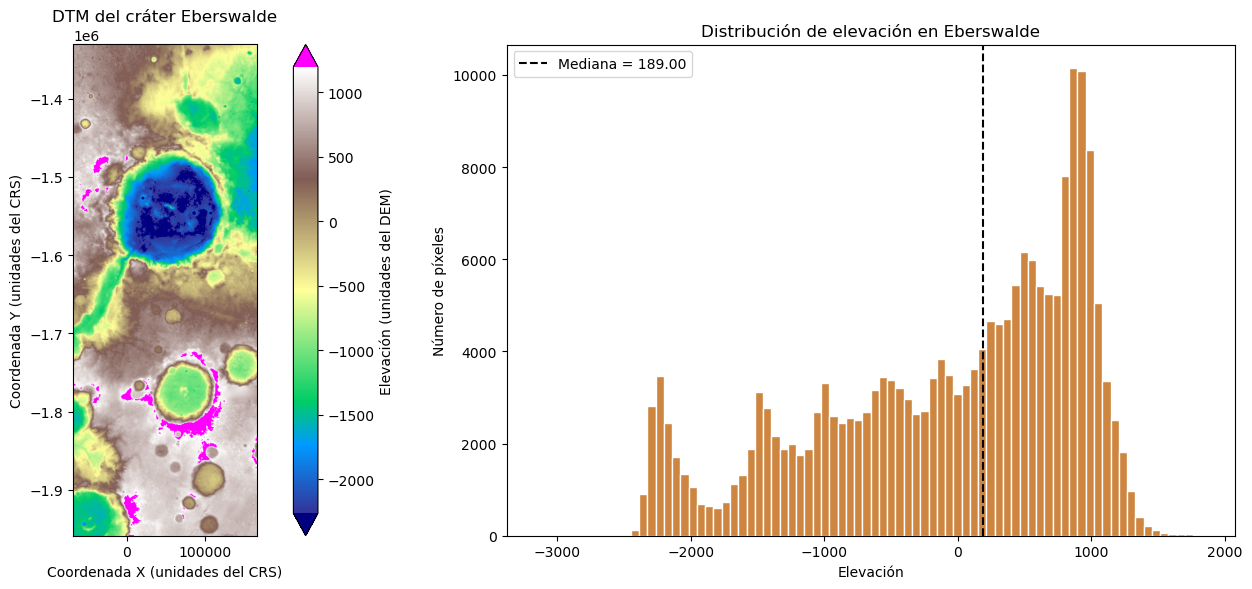


=== COMPATIBILITY DIAGNOSTICS ===
- Native resolution: 50.000 × 50.000 m/pixel (if the CRS uses metres).
- To compare with Jezero, both DEMs must be harmonised to a common spatial resolution.
- Roughness must be computed in a window defined in metres, not with a fixed number of pixels.
- Absolute elevation will not be compared directly with Mexico; we will use elevation spread, slope and roughness.


In [14]:
## EDA of Mars crater 2

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from matplotlib.colors import Normalize

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------
tif_file = "data/eberswalde_dtm.tif"

path = Path(tif_file)
if not path.is_file():
    raise FileNotFoundError(f"File not found: {path}")


# ------------------------------------------------------------
# READ AND METADATA
# ------------------------------------------------------------
with rasterio.open(path) as src:
    print("=== EDA: EBERSWALDE DTM ===")
    print(f"File: {path.name}")
    print(f"Dimensions: {src.width:,} columns × {src.height:,} rows")
    print(f"Bandas: {src.count}")
    print(f"Data type: {src.dtypes}")
    print(f"CRS:\n{src.crs}")
    print(f"Bounds: {src.bounds}")
    print(f"Resolution: {src.res} units/pixel")
    print(f"NoData: {src.nodata}")
    print(f"Affine transform: {src.transform}")

    # Read the first band as elevation
    dem = src.read(1, masked=True)

    res_x, res_y = src.res
    width_km = (src.width * res_x) / 1000
    height_km = (src.height * res_y) / 1000
    area_km2 = width_km * height_km

# Convert invalid values to a mask
dem = np.ma.masked_invalid(dem)

total_pixels = dem.size
nodata_pixels = np.ma.getmaskarray(dem).sum()
valid_pixels = total_pixels - nodata_pixels
coverage_pct = valid_pixels / total_pixels * 100

values = dem.compressed()

if values.size == 0:
    raise ValueError("No valid pixels in the first band.")

print("\n=== COVERAGE ===")
print(f"Total pixels: {total_pixels:,}")
print(f"Valid pixels: {valid_pixels:,}")
print(f"NoData pixels: {nodata_pixels:,}")
print(f"Valid coverage: {coverage_pct:.3f}%")

print("\n=== APPROXIMATE EXTENT ===")
print(f"Ancho: {width_km:.2f} km")
print(f"Alto: {height_km:.2f} km")
print(f"Area: {area_km2:.2f} km²")

stats = pd.Series({
    "minimum": values.min(),
    "percentile_2": np.percentile(values, 2),
    "percentile_5": np.percentile(values, 5),
    "mean_value": values.mean(),
    "median_value": np.median(values),
    "percentile_95": np.percentile(values, 95),
    "percentile_98": np.percentile(values, 98),
    "maximum": values.max(),
    "standard_deviation": values.std(),
    "relief_total": values.max() - values.min(),
})

print("\n=== ELEVATION STATISTICS ===")
display(stats.round(3).to_frame("value_item"))


# ------------------------------------------------------------
# VISUALIZATION: DTM AND HISTOGRAM
# ------------------------------------------------------------
# Downsample only for the figure, not for the statistics.
max_plot_size = 900
step = max(1, int(max(dem.shape) / max_plot_size))
dem_preview = dem[::step, ::step]

# Robust range to show relief without extremes dominating
vmin, vmax = np.percentile(values, [2, 98])

cmap = plt.colormaps["terrain"].copy()
cmap.set_bad("lightgray")  # NoData
cmap.set_under("navy")     # Elevaciones < percentil 2
cmap.set_over("magenta")   # Elevaciones > percentil 98

norm = Normalize(vmin=vmin, vmax=vmax, clip=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

image = axes[0].imshow(
    dem_preview,
    cmap=cmap,
    norm=norm,
    extent=[src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top],
    origin="upper",
)

axes[0].set_title("Eberswalde crater DTM")
axes[0].set_xlabel("X coordinate (CRS units)")
axes[0].set_ylabel("Y coordinate (CRS units)")
plt.colorbar(
    image,
    ax=axes[0],
    label="Elevation (DEM units)",
    extend="both",
)

# Histogram: random sample so it stays fast if the TIFF is large
rng = np.random.default_rng(42)
sample_size = min(200_000, values.size)
sample = rng.choice(values, size=sample_size, replace=False)

axes[1].hist(sample, bins=80, color="peru", edgecolor="white")
axes[1].axvline(
    np.median(values),
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Median = {np.median(values):.2f}",
)

axes[1].set_title("Elevation distribution in Eberswalde")
axes[1].set_xlabel("Elevation")
axes[1].set_ylabel("Number of pixels")
axes[1].legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# DIAGNOSTICS TO COMPARE IT WITH JEZERO
# ------------------------------------------------------------
print("\n=== COMPATIBILITY DIAGNOSTICS ===")
print(
    f"- Native resolution: {res_x:.3f} × {res_y:.3f} m/pixel "
    "(if the CRS uses metres)."
)
print(
    "- To compare with Jezero, both DEMs must be harmonised "
    "to a common spatial resolution."
)
print(
    "- Roughness must be computed in a window defined in metres, "
    "not with a fixed number of pixels."
)
print(
    "- Absolute elevation will not be compared directly with Mexico; "
    "we will use elevation spread, slope and roughness."
)

## 2. Querying THEMIS Orbital Products for the Initial Craters


### 2.1 Configuration and ODE Query Function


In [6]:
import requests
import pandas as pd

ODE_URL = "https://oderest.rsl.wustl.edu/live2/"

def query_ode(site_name, bounds, product_type, limit=100, offset=0):
    """
    Queries THEMIS metadata in ODE. Does not download files yet.

    bounds = {
        "minlat": ...,
        "maxlat": ...,
        "westernlon": ...,  # east longitude 0–360
        "easternlon": ...
    }
    """
    params = {
        "target": "mars",
        "query": "product",
        "results": "copmf",   # c=count, o=ODE id, p=identificadores, m=metadatos, f=file_list
        "output": "JSON",
        "ihid": "ODY",
        "iid": "THEMIS",
        "pt": product_type,
        "minlat": bounds["minlat"],
        "maxlat": bounds["maxlat"],
        "westernlon": bounds["westernlon"],
        "easternlon": bounds["easternlon"],
        "loc": "f",           # real intersection with the product footprint
        "limit": limit,
        "offset": offset,
    }

    response = requests.get(ODE_URL, params=params, timeout=90)
    response.raise_for_status()

    payload = response.json()
    ode_results = payload.get("ODEResults", payload)

    status = str(
        ode_results.get("Status", ode_results.get("status", "UNKNOWN"))
    ).upper()

    if status != "SUCCESS":
        error = ode_results.get("Error", ode_results.get("error", "No detail"))
        raise RuntimeError(f"ODE answered {status}: {error}")

    products_container = ode_results.get("Products", {})
    products = products_container.get("Product", [])

    # When ODE returns exactly one product, it does not return it as a list.
    if isinstance(products, dict):
        products = [products]

    result = pd.json_normalize(products)

    print(
        f"{site_name} | {product_type}: "
        f"{len(result)} products retrieved "
        f"(offset={offset}, limit={limit})"
    )

    return result

### 2.2 Test THEMIS Query for Jezero


In [7]:
jezero_irpbt = query_ode(
    site_name="jezero",
    bounds=SITES["jezero"],
    product_type="IRPBT4",
    limit=20,
)

display(jezero_irpbt.head())
print(jezero_irpbt.columns.tolist())

jezero | IRPBT4: 20 products retrieved (offset=0, limit=20)


,BB_georeferenced,Bundle_lid,Center_georeferenced,Center_latitude,Center_longitude,Collection_lid,Data_Set_Id,Description,Easternmost_longitude,Emission_angle,...,SpaceCraft_clock_start_count,SpaceCraft_clock_stop_count,Start_orbit_number,Stop_orbit_number,Target_name,UTC_start_time,UTC_stop_time,Westernmost_longitude,ODE_notes.ODE_note,Product_files.Product_file
0,True,urn:nasa:pds:ody.themis.geo,True,18.051,77.611,urn:nasa:pds:ody.themis.geo:data_irpbt,ody.themis.geo-data_irpbt,"MARS ODYSSEY THEMIS Projected Data Products, I...",78.117,0.704,...,1393680568.102,1393680628.170,98521,98521,MARS,2024-02-29T13:15:54.706Z,2024-02-29T13:16:54.971Z,77.115,"[NOTE: ODE Changed Product Type DDR to IRPBT4,...","[{'Description': 'PRODUCT DATA FILE', 'FileNam..."
1,True,urn:nasa:pds:ody.themis.geo,True,20.468,77.628,urn:nasa:pds:ody.themis.geo:data_irpbt,ody.themis.geo-data_irpbt,"MARS ODYSSEY THEMIS Projected Data Products, I...",78.399,1.329,...,1393990719.179,1393990856.196,98565,98565,MARS,2024-03-04T03:25:05.792Z,2024-03-04T03:27:22.858Z,76.836,"[NOTE: ODE Changed Product Type DDR to IRPBT4,...","[{'Description': 'PRODUCT DATA FILE', 'FileNam..."
2,True,urn:nasa:pds:ody.themis.geo,True,18.437,76.678,urn:nasa:pds:ody.themis.geo:data_irpbt,ody.themis.geo-data_irpbt,"MARS ODYSSEY THEMIS Projected Data Products, I...",77.177,1.399,...,1394168570.051,1394168630.119,98590,98590,MARS,2024-03-06T04:49:16.169Z,2024-03-06T04:50:16.434Z,76.17,"[NOTE: ODE Changed Product Type DDR to IRPBT4,...","[{'Description': 'PRODUCT DATA FILE', 'FileNam..."
3,True,urn:nasa:pds:ody.themis.geo,True,20.104,77.055,urn:nasa:pds:ody.themis.geo:data_irpbt,ody.themis.geo-data_irpbt,"MARS ODYSSEY THEMIS Projected Data Products, I...",78.002,1.443,...,1395900031.076,1395900211.009,98833,98833,MARS,2024-03-26T05:46:56.023Z,2024-03-26T05:49:55.762Z,76.143,"[NOTE: ODE Changed Product Type DDR to IRPBT4,...","[{'Description': 'PRODUCT DATA FILE', 'FileNam..."
4,True,urn:nasa:pds:ody.themis.geo,True,18.239,77.073,urn:nasa:pds:ody.themis.geo:data_irpbt,ody.themis.geo-data_irpbt,"MARS ODYSSEY THEMIS Projected Data Products, I...",77.569,1.009,...,1396210281.051,1396210341.119,98877,98877,MARS,2024-03-29T19:57:45.703Z,2024-03-29T19:58:45.969Z,76.568,"[NOTE: ODE Changed Product Type DDR to IRPBT4,...","[{'Description': 'PRODUCT DATA FILE', 'FileNam..."


['BB_georeferenced', 'Bundle_lid', 'Center_georeferenced', 'Center_latitude', 'Center_longitude', 'Collection_lid', 'Data_Set_Id', 'Description', 'Easternmost_longitude', 'Emission_angle', 'External_url', 'FilesURL', 'Footprint_C0_geometry', 'Footprint_geometry', 'Footprint_GL_geometry', 'Footprint_NP_geometry', 'Footprint_souce', 'Footprint_SP_geometry', 'Footprints_cross_meridian', 'ihid', 'iid', 'Incidence_angle', 'Label_product_type', 'LabelFileName', 'LabelURL', 'Map_resolution', 'Map_scale', 'Maximum_latitude', 'Minimum_latitude', 'Observation_time', 'ode_id', 'pdsid', 'PDSVolume_Id', 'Phase_angle', 'Pole_state', 'Product_creation_time', 'Product_lid', 'Product_name', 'Product_title', 'Product_version_id', 'ProductURL', 'pt', 'RelativePathtoVol', 'Solar_distance', 'Solar_longitude', 'Solar_time', 'SpaceCraft_clock_start_count', 'SpaceCraft_clock_stop_count', 'Start_orbit_number', 'Stop_orbit_number', 'Target_name', 'UTC_start_time', 'UTC_stop_time', 'Westernmost_longitude', 'ODE_

### 2.3 Combined Query and Organization of Retrieved Products


In [8]:
frames = []

for site_name, bounds in SITES.items():
    for product_type in PRODUCT_TYPES:
        result = query_ode(site_name, bounds, product_type, limit=100)

        if not result.empty:
            result["site"] = site_name
            result["requested_product_type"] = product_type
            frames.append(result)

themis_manifest = (
    pd.concat(frames, ignore_index=True)
    if frames
    else pd.DataFrame()
)

print(f"\nProducts retrieved: {len(themis_manifest):,}")
display(themis_manifest.head())

jezero | IRPBT4: 100 products retrieved (offset=0, limit=100)
jezero | VISALB4: 88 products retrieved (offset=0, limit=100)
eberswalde | IRPBT4: 100 products retrieved (offset=0, limit=100)
eberswalde | VISALB4: 44 products retrieved (offset=0, limit=100)

Products retrieved: 332


,BB_georeferenced,Bundle_lid,Center_georeferenced,Center_latitude,Center_longitude,Collection_lid,Data_Set_Id,Description,Easternmost_longitude,Emission_angle,...,Stop_orbit_number,Target_name,UTC_start_time,UTC_stop_time,Westernmost_longitude,ODE_notes.ODE_note,Product_files.Product_file,site,requested_product_type,USGS_Sites.USGS_Site
0,True,urn:nasa:pds:ody.themis.geo,True,18.051,77.611,urn:nasa:pds:ody.themis.geo:data_irpbt,ody.themis.geo-data_irpbt,"MARS ODYSSEY THEMIS Projected Data Products, I...",78.117,0.704,...,98521,MARS,2024-02-29T13:15:54.706Z,2024-02-29T13:16:54.971Z,77.115,"[NOTE: ODE Changed Product Type DDR to IRPBT4,...","[{'Description': 'PRODUCT DATA FILE', 'FileNam...",jezero,IRPBT4,NaN
1,True,urn:nasa:pds:ody.themis.geo,True,20.468,77.628,urn:nasa:pds:ody.themis.geo:data_irpbt,ody.themis.geo-data_irpbt,"MARS ODYSSEY THEMIS Projected Data Products, I...",78.399,1.329,...,98565,MARS,2024-03-04T03:25:05.792Z,2024-03-04T03:27:22.858Z,76.836,"[NOTE: ODE Changed Product Type DDR to IRPBT4,...","[{'Description': 'PRODUCT DATA FILE', 'FileNam...",jezero,IRPBT4,NaN
2,True,urn:nasa:pds:ody.themis.geo,True,18.437,76.678,urn:nasa:pds:ody.themis.geo:data_irpbt,ody.themis.geo-data_irpbt,"MARS ODYSSEY THEMIS Projected Data Products, I...",77.177,1.399,...,98590,MARS,2024-03-06T04:49:16.169Z,2024-03-06T04:50:16.434Z,76.17,"[NOTE: ODE Changed Product Type DDR to IRPBT4,...","[{'Description': 'PRODUCT DATA FILE', 'FileNam...",jezero,IRPBT4,NaN
3,True,urn:nasa:pds:ody.themis.geo,True,20.104,77.055,urn:nasa:pds:ody.themis.geo:data_irpbt,ody.themis.geo-data_irpbt,"MARS ODYSSEY THEMIS Projected Data Products, I...",78.002,1.443,...,98833,MARS,2024-03-26T05:46:56.023Z,2024-03-26T05:49:55.762Z,76.143,"[NOTE: ODE Changed Product Type DDR to IRPBT4,...","[{'Description': 'PRODUCT DATA FILE', 'FileNam...",jezero,IRPBT4,NaN
4,True,urn:nasa:pds:ody.themis.geo,True,18.239,77.073,urn:nasa:pds:ody.themis.geo:data_irpbt,ody.themis.geo-data_irpbt,"MARS ODYSSEY THEMIS Projected Data Products, I...",77.569,1.009,...,98877,MARS,2024-03-29T19:57:45.703Z,2024-03-29T19:58:45.969Z,76.568,"[NOTE: ODE Changed Product Type DDR to IRPBT4,...","[{'Description': 'PRODUCT DATA FILE', 'FileNam...",jezero,IRPBT4,NaN


## 3. Selection and Download of THEMIS Samples


### 3.1 Representative Scene Selection and Initial Download


In [9]:
from pathlib import Path
from urllib.parse import urlparse
import math
import requests
import numpy as np
import pandas as pd

# Local folder for the 4 THEMIS samples.
THEMIS_DIR = Path("themis_samples")
THEMIS_DIR.mkdir(exist_ok=True)

THEMIS_TYPES = ["IRPBT4", "VISALB4"]


def roi_center(bounds):
    """Lat/lon center of the crater search box."""
    return (
        (bounds["minlat"] + bounds["maxlat"]) / 2,
        (bounds["westernlon"] + bounds["easternlon"]) / 2,
    )


def center_distance_deg(lat1, lon1, lat2, lon2):
    """
    Approximate distance used to sort scenes.
    Handles the 0°/360° Martian longitude wrap correctly.
    """
    delta_lon = ((lon1 - lon2 + 180) % 360) - 180
    return np.hypot(lat1 - lat2, delta_lon * np.cos(np.deg2rad(lat2)))


def normalize_files(value_item):
    """Converts Product_files.Product_file to a list of dictionaries."""
    if isinstance(value_item, dict):
        return [value_item]

    if isinstance(value_item, list):
        return [x for x in value_item if isinstance(x, dict)]

    return []


def get_url(file_entry):
    """Supports the name variants ODE may return."""
    for key_name in ("URL", "url", "Url"):
        if key_name in file_entry and pd.notna(file_entry[key_name]):
            return str(file_entry[key_name])
    return None


def url_name(url):
    return Path(urlparse(url).path).name


def required_files(product_item):
    """
    Keeps the science raster and its PDS4/XML or PDS3/LBL label.
    Does not download browse images or unnecessary auxiliary files.
    """
    file_list = normalize_files(product_item["Product_files.Product_file"])

    candidate_rows = []
    for file_entry in file_list:
        url = get_url(file_entry)
        if url is None:
            continue

        extension = Path(urlparse(url).path).suffix.lower()
        kind_value = str(file_entry.get("Type", "")).lower()

        is_raster = extension in {".img", ".tif", ".tiff", ".jp2"}
        is_label = extension in {".xml", ".lbl"}

        if is_raster or is_label:
            candidate_rows.append(
                {
                    "url": url,
                    "file_entry": url_name(url),
                    "ode_type": kind_value,
                    "extension": extension,
                }
            )

    return candidate_rows


def download(url, target_path):
    """Downloads without overwriting an already downloaded file."""
    target_path = Path(target_path)

    if target_path.exists() and target_path.stat().st_size > 0:
        print(f"Ya existe: {target_path.name}")
        return target_path

    with requests.get(url, stream=True, timeout=180) as response_json:
        response_json.raise_for_status()

        with open(target_path, "wb") as output_value:
            for block in response_json.iter_content(chunk_size=1024 * 1024):
                if block:
                    output_value.write(block)

    print(f"Descargado: {target_path.name}")
    return target_path


# 1. Pick one representative scene per crater and product type.
selected_list = []

for site, bounds in SITES.items():
    lat_roi, lon_roi = roi_center(bounds)

    for kind_value in THEMIS_TYPES:
        candidate_list = themis_manifest.loc[
            (themis_manifest["site"] == site)
            & (themis_manifest["requested_product_type"] == kind_value)
        ].copy()

        if candidate_list.empty:
            print(f"No scenes for {site} | {kind_value}")
            continue

        candidate_list["Center_latitude"] = pd.to_numeric(
            candidate_list["Center_latitude"], errors="coerce"
        )
        candidate_list["Center_longitude"] = pd.to_numeric(
            candidate_list["Center_longitude"], errors="coerce"
        )

        candidate_list = candidate_list.dropna(
            subset=["Center_latitude", "Center_longitude"]
        ).copy()

        candidate_list["distance_to_roi_center_val"] = candidate_list.apply(
            lambda row_item: center_distance_deg(
                row_item["Center_latitude"],
                row_item["Center_longitude"],
                lat_roi,
                lon_roi,
            ),
            axis=1,
        )

        scene_row = candidate_list.sort_values("distance_to_roi_center_val").iloc[0].copy()
        selected_list.append(scene_row)

themis_samples_dir = pd.DataFrame(selected_list).reset_index(drop=True)

review_columns = [
    "site",
    "requested_product_type",
    "pdsid",
    "Center_latitude",
    "Center_longitude",
    "UTC_start_time",
    "UTC_stop_time",
    "Emission_angle",
    "distance_to_roi_center_val",
]

display(themis_samples_dir[[c for c in review_columns if c in themis_samples_dir.columns]])


# 2. Download raster + label for each of the four selected scenes.
download_index = []

for _, product_item in themis_samples_dir.iterrows():
    site = product_item["site"]
    kind_value = product_item["requested_product_type"]
    pdsid = str(product_item["pdsid"])

    product_dir = THEMIS_DIR / site / kind_value / pdsid
    product_dir.mkdir(parents=True, exist_ok=True)

    file_list = required_files(product_item)

    if not file_list:
        print(f"\nNo IMG/TIFF/XML/LBL found for: {pdsid}")
        continue

    print(f"\n{site.upper()} | {kind_value} | {pdsid}")

    for file_entry in file_list:
        local_file_path = download(
            file_entry["url"],
            product_dir / file_entry["file_entry"],
        )

        download_index.append(
            {
                "site": site,
                "product_kind": kind_value,
                "pdsid": pdsid,
                "url": file_entry["url"],
                "local_file_path": str(local_file_path),
                "extension": file_entry["extension"],
            }
        )

download_index = pd.DataFrame(download_index)

print("\nArchivos locales:")
display(download_index)

,site,requested_product_type,pdsid,Center_latitude,Center_longitude,UTC_start_time,UTC_stop_time,Emission_angle,distance_to_roi_center_val
0,jezero,IRPBT4,i95333002pbt,18.230,77.807,2023-06-12T00:36:59.119Z,2023-06-12T00:37:59.384Z,1.314,0.259769
1,jezero,VISALB4,v98278006alb,18.417,77.570,2024-02-09T12:16:44.205Z,2024-02-09T12:17:01.810Z,0.472,0.033156
2,eberswalde,IRPBT4,ia3617002pbt,-23.826,326.634,2025-04-24T01:46:29.007Z,2025-04-24T01:48:29.007Z,1.287,0.065747
3,eberswalde,VISALB4,v83963003alb,-23.991,326.581,2020-11-17T19:01:18.076Z,2020-11-17T19:01:35.681Z,0.389,0.219854



JEZERO | IRPBT4 | i95333002pbt
Descargado: I95333002PBT.IMG
Descargado: I95333002PBT.xml
Descargado: ody_orient_point.xml

JEZERO | VISALB4 | v98278006alb
Descargado: ody_orient_point.xml
Descargado: V98278006ALB.IMG
Descargado: V98278006ALB.xml

EBERSWALDE | IRPBT4 | ia3617002pbt
Descargado: IA3617002PBT.IMG
Descargado: IA3617002PBT.xml
Descargado: ody_orient_point.xml

EBERSWALDE | VISALB4 | v83963003alb
Descargado: ody_orient_point.xml
Descargado: V83963003ALB.IMG
Descargado: V83963003ALB.xml

Archivos locales:


,site,product_kind,pdsid,url,local_file_path,extension
0,jezero,IRPBT4,i95333002pbt,https://static.mars.asu.edu/pds/ODTGEO_v2/data...,themis_samples/jezero/IRPBT4/i95333002pbt/I95...,.img
1,jezero,IRPBT4,i95333002pbt,https://static.mars.asu.edu/pds/ODTGEO_v2/data...,themis_samples/jezero/IRPBT4/i95333002pbt/I95...,.xml
2,jezero,IRPBT4,i95333002pbt,https://static.mars.asu.edu/pds/ODTGEO_v2/docu...,themis_samples/jezero/IRPBT4/i95333002pbt/ody...,.xml
3,jezero,VISALB4,v98278006alb,https://static.mars.asu.edu/pds/ODTGEO_v2/docu...,themis_samples/jezero/VISALB4/v98278006alb/od...,.xml
4,jezero,VISALB4,v98278006alb,https://static.mars.asu.edu/pds/ODTGEO_v2/data...,themis_samples/jezero/VISALB4/v98278006alb/V9...,.img
5,jezero,VISALB4,v98278006alb,https://static.mars.asu.edu/pds/ODTGEO_v2/data...,themis_samples/jezero/VISALB4/v98278006alb/V9...,.xml
6,eberswalde,IRPBT4,ia3617002pbt,https://static.mars.asu.edu/pds/ODTGEO_v2/data...,themis_samples/eberswalde/IRPBT4/ia3617002pbt...,.img
7,eberswalde,IRPBT4,ia3617002pbt,https://static.mars.asu.edu/pds/ODTGEO_v2/data...,themis_samples/eberswalde/IRPBT4/ia3617002pbt...,.xml
8,eberswalde,IRPBT4,ia3617002pbt,https://static.mars.asu.edu/pds/ODTGEO_v2/docu...,themis_samples/eberswalde/IRPBT4/ia3617002pbt...,.xml
9,eberswalde,VISALB4,v83963003alb,https://static.mars.asu.edu/pds/ODTGEO_v2/docu...,themis_samples/eberswalde/VISALB4/v83963003al...,.xml


### 3.2 Alternative Scene Selection and Download Procedure


In [11]:
from pathlib import Path
from urllib.parse import urlparse
import math
import requests
import numpy as np
import pandas as pd

# Folder that will hold only the four initial samples.
OUTPUT_DIR = Path("themis_samples")
OUTPUT_DIR.mkdir(exist_ok=True)

THEMIS_PRODUCT_LIST = ["IRPBT4", "VISALB4"]


def midpoint(bounds):
    """Center of the ROI defined earlier in SITES."""
    return (
        (bounds["minlat"] + bounds["maxlat"]) / 2,
        (bounds["westernlon"] + bounds["easternlon"]) / 2,
    )


def distance_to_roi_center(row, roi_lat, roi_lon):
    """
    Approximate angular distance to pick a scene near the ROI center.
    Assumes Martian longitudes are in the 0–360 interval.
    """
    lat = pd.to_numeric(row.get("Center_latitude"), errors="coerce")
    lon = pd.to_numeric(row.get("Center_longitude"), errors="coerce")

    if not np.isfinite(lat) or not np.isfinite(lon):
        return np.inf

    delta_lon = ((lon - roi_lon + 180) % 360) - 180
    return np.hypot(lat - roi_lat, delta_lon * np.cos(np.deg2rad(roi_lat)))


def get_product_files(value):
    """Converts the nested Product_files.Product_file column to a list."""
    if isinstance(value, dict):
        return [value]
    if isinstance(value, list):
        return [item for item in value if isinstance(item, dict)]
    return []


def file_url(file_record):
    """Gets the URL even if ODE changes the field's letter case."""
    for key in ("URL", "Url", "url"):
        if key in file_record and pd.notna(file_record[key]):
            return str(file_record[key])
    return None


def file_name(file_record):
    url = file_url(file_record)
    if not url:
        return None
    return Path(urlparse(url).path).name


def choose_files(product_files):
    """
    Picks the raster file and, when present, its PDS label.
    Does not download browse images or unnecessary auxiliary files.
    """
    raster_extensions = (".img", ".tif", ".tiff", ".jp2")

    raster = []
    labels = []

    for item in product_files:
        name = file_name(item)
        if not name:
            continue

        name_lower = name.lower()

        if name_lower.endswith(raster_extensions):
            raster.append(item)
        elif name_lower.endswith((".xml", ".lbl")):
            labels.append(item)

    if not raster:
        return None, None

    # If there is more than one raster file, use the largest declared one.
    def size_kb(item):
        return pd.to_numeric(item.get("KBytes", 0), errors="coerce") or 0

    raster_file = max(raster, key=size_kb)
    label_file = labels[0] if labels else None

    return raster_file, label_file


def download_file(url, destination):
    """Downloads without overwriting an existing file."""
    if destination.exists():
        print(f"Ya existe: {destination.name}")
        return destination

    with requests.get(url, stream=True, timeout=180) as response:
        response.raise_for_status()

        with open(destination, "wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    output.write(chunk)

    print(f"Descargado: {destination.name}")
    return destination


# Select one scene per combination: 2 craters × 2 products = 4 scenes.
selected_rows = []

for site in ["jezero", "eberswalde"]:
    roi_lat, roi_lon = midpoint(SITES[site])

    for product_item in THEMIS_PRODUCT_LIST:
        candidates = themis_manifest.loc[
            (themis_manifest["site"] == site)
            & (themis_manifest["requested_product_type"] == product_item)
        ].copy()

        if candidates.empty:
            print(f"No candidates: {site} | {product_item}")
            continue

        candidates["distance_to_roi_center_val"] = candidates.apply(
            distance_to_roi_center,
            axis=1,
            roi_lat=roi_lat,
            roi_lon=roi_lon,
        )

        selected = candidates.sort_values("distance_to_roi_center_val").iloc[0].copy()
        selected_rows.append(selected)

scene_index = pd.DataFrame(selected_rows).reset_index(drop=True)

# Download the raster and label of each selected scene.
downloads = []

for _, scene in scene_index.iterrows():
    product_id = str(scene["pdsid"])
    site = scene["site"]
    product_item = scene["requested_product_type"]

    scene_dir = OUTPUT_DIR / site / product_item / product_id
    scene_dir.mkdir(parents=True, exist_ok=True)

    product_files = get_product_files(scene["Product_files.Product_file"])
    raster_record, label_record = choose_files(product_files)

    if raster_record is None:
        print(f"No downloadable raster found: {site} | {product_item} | {product_id}")
        continue

    raster_url = file_url(raster_record)
    raster_path = download_file(raster_url, scene_dir / file_name(raster_record))

    label_path = None
    if label_record is not None:
        label_url = file_url(label_record)
        label_path = download_file(label_url, scene_dir / file_name(label_record))

    downloads.append({
        "site": site,
        "product_item": product_item,
        "pdsid": product_id,
        "raster_path": str(raster_path),
        "label_path": str(label_path) if label_path else None,
        "mid_lat": scene.get("Center_latitude"),
        "mid_lon": scene.get("Center_longitude"),
        "utc_start": scene.get("UTC_start_time"),
        "utc_end": scene.get("UTC_stop_time"),
        "emission_angle": scene.get("Emission_angle"),
        "distance_to_roi_center_val": scene["distance_to_roi_center_val"],
    })

scene_index = pd.DataFrame(downloads)

print("\n=== SCENES DOWNLOADED FOR EDA ===")
display(scene_index)

Ya existe: I95333002PBT.IMG
Ya existe: I95333002PBT.xml
Ya existe: V98278006ALB.IMG
Ya existe: ody_orient_point.xml
Ya existe: IA3617002PBT.IMG
Ya existe: IA3617002PBT.xml
Ya existe: V83963003ALB.IMG
Ya existe: ody_orient_point.xml

=== SCENES DOWNLOADED FOR EDA ===


,site,product_item,pdsid,raster_path,label_path,mid_lat,mid_lon,utc_start,utc_end,emission_angle,distance_to_roi_center_val
0,jezero,IRPBT4,i95333002pbt,themis_samples/jezero/IRPBT4/i95333002pbt/I95...,themis_samples/jezero/IRPBT4/i95333002pbt/I95...,18.23,77.807,2023-06-12T00:36:59.119Z,2023-06-12T00:37:59.384Z,1.314,0.259769
1,jezero,VISALB4,v98278006alb,themis_samples/jezero/VISALB4/v98278006alb/V9...,themis_samples/jezero/VISALB4/v98278006alb/od...,18.417,77.57,2024-02-09T12:16:44.205Z,2024-02-09T12:17:01.810Z,0.472,0.033156
2,eberswalde,IRPBT4,ia3617002pbt,themis_samples/eberswalde/IRPBT4/ia3617002pbt...,themis_samples/eberswalde/IRPBT4/ia3617002pbt...,-23.826,326.634,2025-04-24T01:46:29.007Z,2025-04-24T01:48:29.007Z,1.287,0.065747
3,eberswalde,VISALB4,v83963003alb,themis_samples/eberswalde/VISALB4/v83963003al...,themis_samples/eberswalde/VISALB4/v83963003al...,-23.991,326.581,2020-11-17T19:01:18.076Z,2020-11-17T19:01:35.681Z,0.389,0.219854


## 4. THEMIS Image Quality Control


### 4.1 Treating Zeros as NoData and Visual Assessment


=== THEMIS EDA: ZEROS TREATED AS NODATA ===


,site,product_item,pdsid,resolution_m_value,total_pixel_count,zero_pixels_masked,valid_coverage_pct,min,p2,median_value,mean_value,p98,max,std
0,jezero,IRPBT4,i95333002pbt,100.0,1033410,436858,57.7266,180.349701,185.913498,192.597305,192.564697,198.566406,205.254105,3.2472
1,jezero,VISALB4,v98278006alb,36.0,1025304,354606,65.4146,0.292500,0.315800,0.342800,0.342400,0.369000,0.405200,0.0138
2,eberswalde,IRPBT4,ia3617002pbt,100.0,2836809,1694470,40.2684,165.030197,178.393799,187.593796,187.231003,194.772202,208.817307,3.7924
3,eberswalde,VISALB4,v83963003alb,36.0,991858,337258,65.9974,0.346500,0.362000,0.387800,0.387800,0.410600,0.426900,0.0118


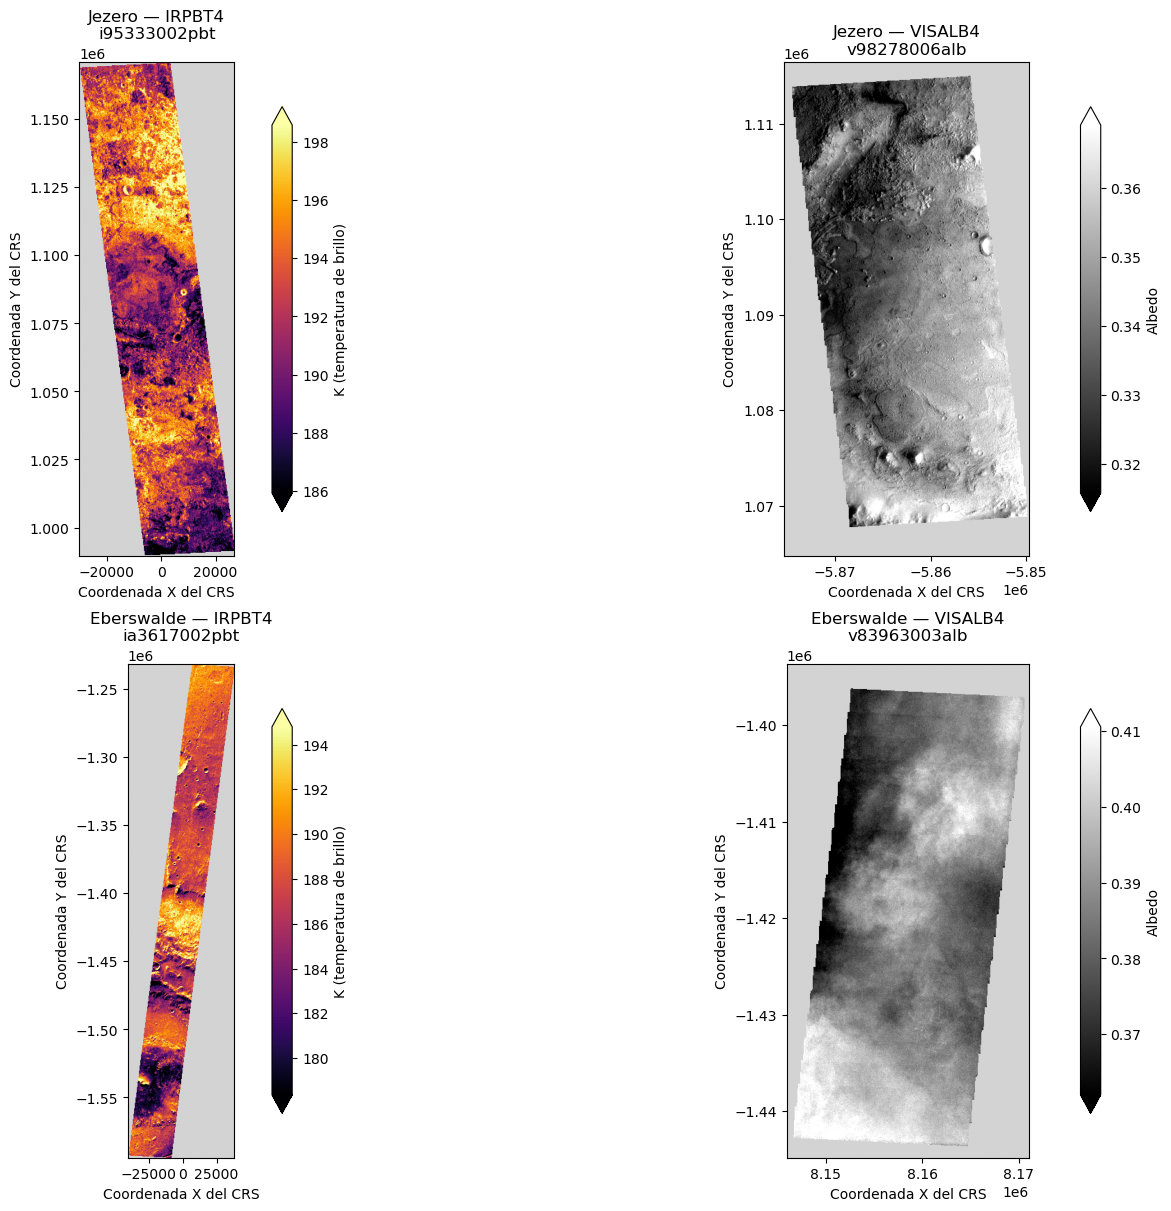

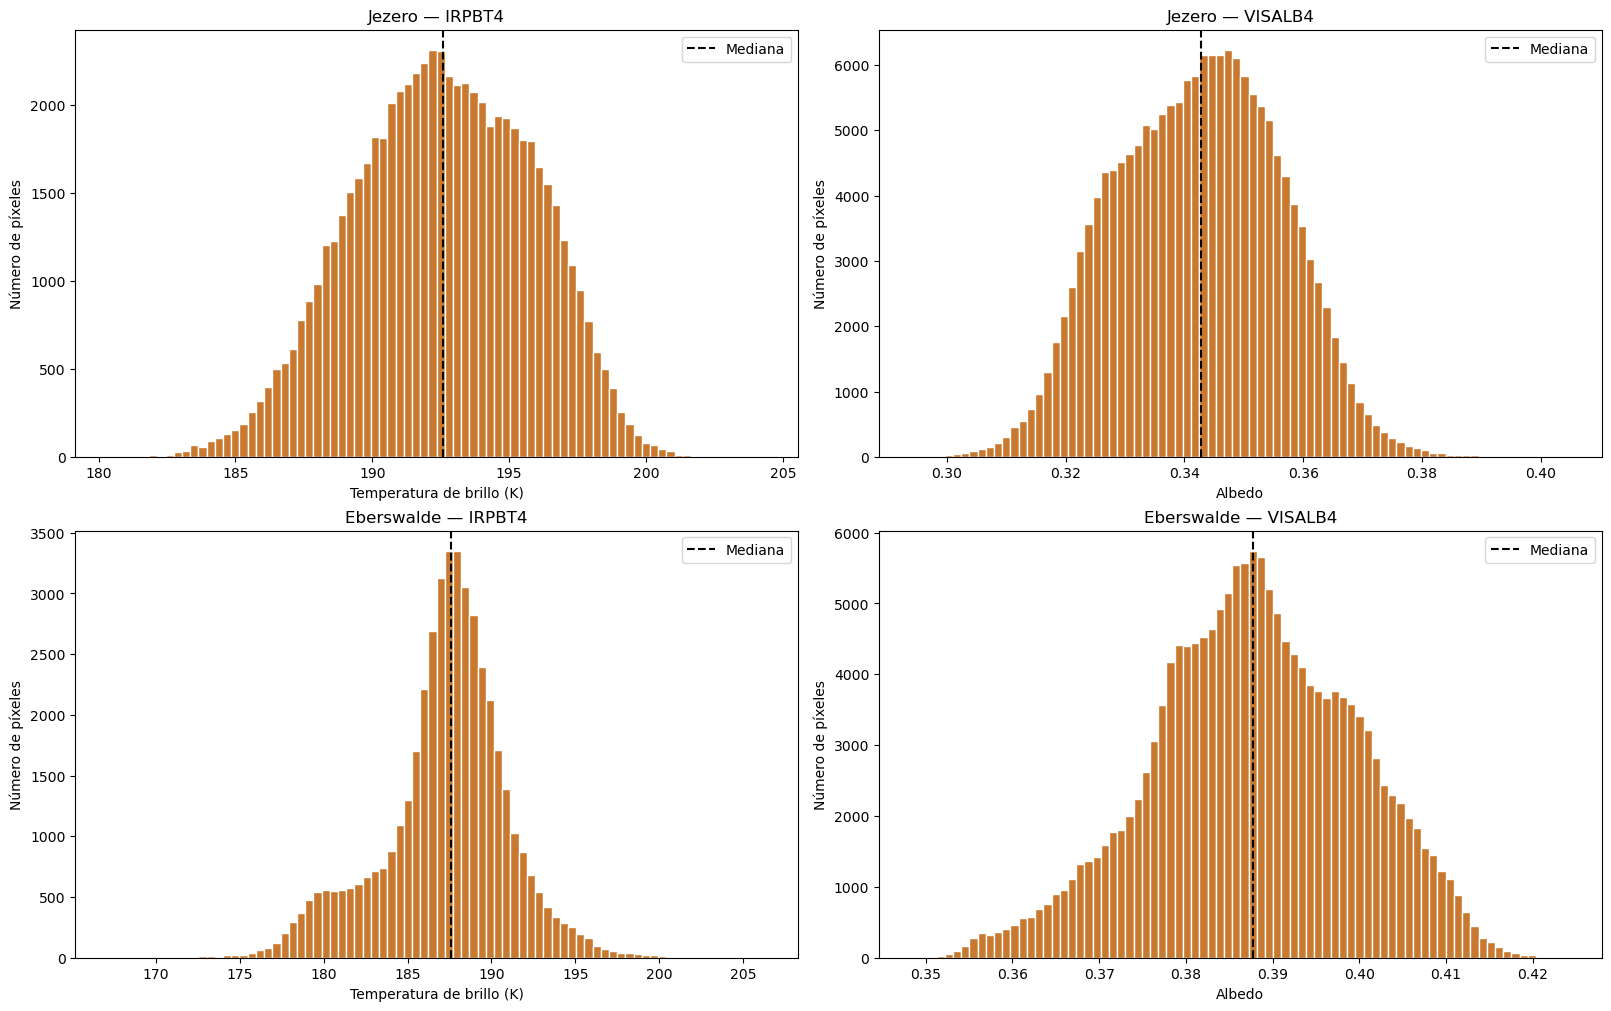

In [16]:
def read_themis_with_zero_mask(src):
    """
    THEMIS IRPBT4 and VISALB4 in this sample use 0 in the swath
    background to mean no observation.
    """
    raw = src.read(1, masked=True).astype(np.float32)

    raw_values = np.asarray(raw.filled(np.nan))
    zero_mask = raw_values == 0

    data = np.ma.masked_where(zero_mask | ~np.isfinite(raw_values), raw)
    return data, int(zero_mask.sum())


summaries_clean = []
previews_clean = []

for _, scene in scene_index.iterrows():
    src, opened_path = open_themis_scene(scene)

    with src:
        data, n_zeros_masked = read_themis_with_zero_mask(src)
        valid = data.compressed()

        if valid.size == 0:
            print(f"No valid data: {scene['pdsid']}")
            continue

        # These scenes are manageable; downsampled only if needed.
        step = max(1, int(np.ceil(max(src.height, src.width) / 900)))
        preview = data[::step, ::step]

        total_pixels = src.width * src.height

        summaries_clean.append({
            "site": scene["site"],
            "product_item": scene["product_item"],
            "pdsid": scene["pdsid"],
            "resolution_m_value": src.res[0],
            "total_pixel_count": total_pixels,
            "zero_pixels_masked": n_zeros_masked,
            "valid_coverage_pct": 100 * valid.size / total_pixels,
            "min": valid.min(),
            "p2": np.percentile(valid, 2),
            "median_value": np.median(valid),
            "mean_value": np.mean(valid),
            "p98": np.percentile(valid, 98),
            "max": valid.max(),
            "std": np.std(valid),
        })

        previews_clean.append({
            "site": scene["site"],
            "product_item": scene["product_item"],
            "pdsid": scene["pdsid"],
            "preview": preview,
            "bounds": src.bounds,
        })

eda_themis_clean = pd.DataFrame(summaries_clean)

print("=== THEMIS EDA: ZEROS TREATED AS NODATA ===")
display(eda_themis_clean.round(4))


# Mapas corregidos
fig, axes = plt.subplots(2, 2, figsize=(16, 12), constrained_layout=True)
axes = axes.ravel()

for ax, item in zip(axes, previews_clean):
    image = item["preview"]
    valid = image.compressed()
    bounds = item["bounds"]

    vmin, vmax = np.percentile(valid, [2, 98])

    cmap_name = "inferno" if item["product_item"] == "IRPBT4" else "gray"
    cmap = plt.colormaps[cmap_name].copy()
    cmap.set_bad("lightgray")  # Now: NoData only

    plotted = ax.imshow(
        image,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        extent=[bounds.left, bounds.right, bounds.bottom, bounds.top],
        origin="upper",
    )

    unit = "K (brightness temperature)" if item["product_item"] == "IRPBT4" else "Albedo"

    ax.set_title(
        f"{item['site'].capitalize()} — {item['product_item']}\n{item['pdsid']}"
    )
    ax.set_xlabel("CRS X coordinate")
    ax.set_ylabel("CRS Y coordinate")

    colorbar = fig.colorbar(plotted, ax=ax, shrink=0.82, extend="both")
    colorbar.set_label(unit)

for ax in axes[len(previews_clean):]:
    ax.axis("off")

plt.show()


# Histogramas corregidos
fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)
axes = axes.ravel()

for ax, item in zip(axes, previews_clean):
    values = item["preview"].compressed()

    ax.hist(values, bins=80, color="#c8792f", edgecolor="white")
    ax.axvline(np.median(values), color="black", linestyle="--", label="Median")
    ax.set_title(f"{item['site'].capitalize()} — {item['product_item']}")
    ax.set_xlabel("Brightness temperature (K)" if item["product_item"] == "IRPBT4" else "Albedo")
    ax.set_ylabel("Number of pixels")
    ax.legend()

for ax in axes[len(previews_clean):]:
    ax.axis("off")

plt.show()

## 6. Initial Martian Profiles: Jezero and Eberswalde


### 6.1 THEMIS Scene Clipping and ROI Statistics


In [25]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from pyproj import CRS, Transformer
from rasterio.errors import RasterioIOError
from rasterio.windows import Window, from_bounds
from rasterio.windows import WindowError


# ============================================================
# READ AND CLIP OF THE MARTIAN ROI
# ============================================================

def open_themis_scene(scene):
    """Opens the PDS4 label if available; otherwise the IMG."""
    candidates = [
        scene.get("pds4_label_path"),
        scene.get("raster_path"),
    ]

    errors = []

    for candidate in candidates:
        if candidate is None or pd.isna(candidate):
            continue

        path = Path(candidate)

        if not path.exists():
            continue

        try:
            return rasterio.open(path)
        except RasterioIOError as error:
            errors.append(f"{path.name}: {error}")

    raise RuntimeError(
        f"Could not open {scene['pdsid']}.\n" + "\n".join(errors)
    )


def mars_bounds_to_raster_bounds(src, geographic_bounds):
    """
    Converts the planetocentric bounding box from SITES
    to the THEMIS raster's own CRS.
    """
    projected_crs = CRS.from_wkt(src.crs.to_wkt())
    mars_geographic_crs = projected_crs.geodetic_crs

    transformer = Transformer.from_crs(
        mars_geographic_crs,
        projected_crs,
        always_xy=True,
    )

    west = geographic_bounds["westernlon"]
    east = geographic_bounds["easternlon"]
    south = geographic_bounds["minlat"]
    north = geographic_bounds["maxlat"]

    # Edge sampling: more robust than transforming only four corners.
    n_points = 25

    lons = np.concatenate([
        np.linspace(west, east, n_points),
        np.linspace(west, east, n_points),
        np.full(n_points, west),
        np.full(n_points, east),
    ])

    lats = np.concatenate([
        np.full(n_points, south),
        np.full(n_points, north),
        np.linspace(south, north, n_points),
        np.linspace(south, north, n_points),
    ])

    xs, ys = transformer.transform(lons, lats)

    return min(xs), min(ys), max(xs), max(ys)


def crop_to_crater_roi(src, geographic_bounds):
    """
    Clips the raster to the ROI and masks:
    - NoData recognised by Rasterio
    - 0 values, which in these THEMIS scenes are background with no observation
    """
    left, bottom, right, top = mars_bounds_to_raster_bounds(
        src,
        geographic_bounds,
    )

    requested_window = from_bounds(
        left,
        bottom,
        right,
        top,
        transform=src.transform,
    ).round_offsets().round_lengths()

    full_window = Window(0, 0, src.width, src.height)

    try:
        crop_window = requested_window.intersection(full_window)
    except WindowError:
        return None, None, None, None

    if crop_window.width <= 0 or crop_window.height <= 0:
        return None, None, None, None

    raw = src.read(1, window=crop_window, masked=True).astype(np.float32)
    raw_values = np.asarray(raw.filled(np.nan))

    # In these scenes we visually confirmed that zero = no observation.
    data = np.ma.masked_where(
        (raw_values == 0) | ~np.isfinite(raw_values),
        raw,
    )

    requested_pixels = requested_window.width * requested_window.height
    crop_pixels = crop_window.width * crop_window.height
    valid_pixels = data.count()

    coverage_scene_pct = 100 * crop_pixels / requested_pixels
    coverage_valid_pct = 100 * valid_pixels / requested_pixels

    return data, crop_window, coverage_scene_pct, coverage_valid_pct


def summarize_values(data):
    """Computes robust statistics of valid pixels."""
    values = data.compressed()

    if len(values) == 0:
        return None

    return {
        "p10": np.percentile(values, 10),
        "p50": np.percentile(values, 50),
        "p90": np.percentile(values, 90),
        "std": np.std(values),
        "n_pixels": len(values),
    }


# ============================================================
# FEATURE EXTRACTION: JEZERO AND EBERSWALDE
# ============================================================

crater_features = {}
roi_crops = []

for _, scene in scene_index.iterrows():
    site = scene["site"]
    product_item = scene["product_item"]

    if site not in SITES:
        print(f"No ROI in SITES for: {site}")
        continue

    with open_themis_scene(scene) as src:
        data, crop_window, coverage_scene, coverage_valid = crop_to_crater_roi(
            src,
            SITES[site],
        )

        if data is None:
            print(f"{site} | {product_item}: the scene does not intersect the ROI.")
            continue

        stats = summarize_values(data)

        if stats is None:
            print(f"{site} | {product_item}: no valid pixels inside the ROI.")
            continue

        if site not in crater_features:
            crater_features[site] = {"site": site}

        # Thermal columns keep the same schema as themis_features.
        if product_item == "IRPBT4":
            crater_features[site].update({
                "ir_temp_p10_k": stats["p10"],
                "ir_temp_p50_k": stats["p50"],
                "ir_temp_p90_k": stats["p90"],
                "ir_temp_std_k": stats["std"],
                "ir_temp_n_pixels": stats["n_pixels"],
                "ir_temp_roi_coverage_pct": coverage_valid,
                "ir_temp_scene_intersection_pct": coverage_scene,
                "ir_temp_pdsid": scene["pdsid"],
            })

        elif product_item == "VISALB4":
            crater_features[site].update({
                "vis_albedo_p50": stats["p50"],
                "vis_albedo_std": stats["std"],
                "vis_albedo_p10": stats["p10"],
                "vis_albedo_p90": stats["p90"],
                "vis_albedo_n_pixels": stats["n_pixels"],
                "vis_albedo_roi_coverage_pct": coverage_valid,
                "vis_albedo_scene_intersection_pct": coverage_scene,
                "vis_albedo_pdsid": scene["pdsid"],
            })

        roi_crops.append({
            "site": site,
            "product_item": product_item,
            "pdsid": scene["pdsid"],
            "data": data,
            "transform": rasterio.windows.transform(crop_window, src.transform),
        })

mars_crater_features = (
    pd.DataFrame(crater_features.values())
    .sort_values("site")
    .reset_index(drop=True)
)

print("=== THEMIS FEATURES CLIPPED TO THE ROI ===")
display(mars_crater_features.round(4))

=== THEMIS FEATURES CLIPPED TO THE ROI ===


,site,ir_temp_p10_k,ir_temp_p50_k,ir_temp_p90_k,ir_temp_std_k,ir_temp_n_pixels,ir_temp_roi_coverage_pct,ir_temp_scene_intersection_pct,ir_temp_pdsid,vis_albedo_p50,vis_albedo_std,vis_albedo_p10,vis_albedo_p90,vis_albedo_n_pixels,vis_albedo_roi_coverage_pct,vis_albedo_scene_intersection_pct,vis_albedo_pdsid
0,eberswalde,182.996506,187.418396,191.984802,3.6578,751178,11.9916,29.6366,ia3617002pbt,0.3878,0.0118,0.3725,0.4034,654600,1.3400,2.0303,v83963003alb
1,jezero,188.566895,192.725403,196.837708,3.1422,579071,14.9416,25.7529,i95333002pbt,0.3428,0.0138,0.3240,0.3602,670698,2.2344,3.4157,v98278006alb


### FINAL CRATER DATASET (MORE CRATERS TO BE ADDED USING THE SAME STRUCTURE)


### 6.2 DEM Feature Calculation and THEMIS Integration in `mars_craters_initial.csv`


In [26]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio

from pyproj import CRS, Transformer
from rasterio.enums import Resampling
from rasterio.windows import Window, from_bounds
from rasterio.windows import WindowError
from scipy.ndimage import uniform_filter


# ============================================================
# CONFIGURATION
# ============================================================

DEM_PATHS = {
    "jezero": Path("data/M20_JezeroCrater_CTXDEM_20m.tif"),
    "eberswalde": Path("data/eberswalde_dtm.tif"),
}

# Same analysis scale for both DEMs.
ANALYSIS_RESOLUTION_M = 50.0
ROUGHNESS_WINDOW_M = 250.0
MIN_VALID_FRACTION = 0.80

OUTPUT_CSV = Path("mars_craters_initial.csv")

assert {"site"}.issubset(mars_crater_features.columns), (
    "First run the block that created 'mars_crater_features'."
)


# ============================================================
# FUNCIONES ESPACIALES
# ============================================================

def mars_bounds_to_raster_bounds(src, geographic_bounds):
    """Converts planetocentric SITES bounds to the DEM CRS."""
    projected_crs = CRS.from_wkt(src.crs.to_wkt())
    mars_geographic_crs = projected_crs.geodetic_crs

    transformer = Transformer.from_crs(
        mars_geographic_crs,
        projected_crs,
        always_xy=True,
    )

    west = geographic_bounds["westernlon"]
    east = geographic_bounds["easternlon"]
    south = geographic_bounds["minlat"]
    north = geographic_bounds["maxlat"]

    n_points = 25

    lons = np.concatenate([
        np.linspace(west, east, n_points),
        np.linspace(west, east, n_points),
        np.full(n_points, west),
        np.full(n_points, east),
    ])

    lats = np.concatenate([
        np.full(n_points, south),
        np.full(n_points, north),
        np.linspace(south, north, n_points),
        np.linspace(south, north, n_points),
    ])

    xs, ys = transformer.transform(lons, lats)

    return min(xs), min(ys), max(xs), max(ys)


def read_dem_roi_at_common_resolution(dem_path, geographic_bounds):
    """
    Clips the DEM to the ROI and brings it to a common target resolution.
    Returns the matrix, effective resolution and valid coverage.
    """
    with rasterio.open(dem_path) as src:
        left, bottom, right, top = mars_bounds_to_raster_bounds(
            src,
            geographic_bounds,
        )

        requested_window = from_bounds(
            left, bottom, right, top, transform=src.transform
        ).round_offsets().round_lengths()

        full_window = Window(0, 0, src.width, src.height)

        try:
            crop_window = requested_window.intersection(full_window)
        except WindowError:
            raise ValueError(f"The ROI does not intersect the DEM: {dem_path}")

        if crop_window.width <= 0 or crop_window.height <= 0:
            raise ValueError(f"The ROI contains no DEM pixels: {dem_path}")

        res_x_original, res_y_original = src.res

        out_width = max(
            2,
            int(round(crop_window.width * res_x_original / ANALYSIS_RESOLUTION_M)),
        )
        out_height = max(
            2,
            int(round(crop_window.height * res_y_original / ANALYSIS_RESOLUTION_M)),
        )

        dem = src.read(
            1,
            window=crop_window,
            out_shape=(out_height, out_width),
            resampling=Resampling.average,
            masked=True,
        ).astype(np.float64)

        dem_values = np.asarray(dem.filled(np.nan))
        dem_values[~np.isfinite(dem_values)] = np.nan

        effective_res_x = crop_window.width * res_x_original / out_width
        effective_res_y = crop_window.height * res_y_original / out_height

        requested_pixels = requested_window.width * requested_window.height
        valid_coverage_pct = (
            100 * np.isfinite(dem_values).sum() / requested_pixels
        )

        return dem_values, effective_res_x, effective_res_y, valid_coverage_pct


def local_roughness(dem, window_pixels, min_valid_fraction=0.80):
    """
    Rugosidad local:
    sqrt(E[z²] - E[z]²)
    Ignora NoData mediante conteos ponderados.
    """
    valid = np.isfinite(dem)
    z = np.where(valid, dem, 0.0)

    kernel_area = window_pixels ** 2

    count = (
        uniform_filter(
            valid.astype(float),
            size=window_pixels,
            mode="constant",
            cval=0,
        )
        * kernel_area
    )

    sum_z = (
        uniform_filter(z, size=window_pixels, mode="constant", cval=0)
        * kernel_area
    )

    sum_z2 = (
        uniform_filter(z ** 2, size=window_pixels, mode="constant", cval=0)
        * kernel_area
    )

    with np.errstate(divide="ignore", invalid="ignore"):
        mean_z = sum_z / count
        mean_z2 = sum_z2 / count
        roughness = np.sqrt(np.maximum(mean_z2 - mean_z ** 2, 0))

    roughness[count < min_valid_fraction * kernel_area] = np.nan

    return roughness


def derive_dem_features(site, dem_path, geographic_bounds):
    """Derives comparable topographic features for a crater."""
    dem, res_x, res_y, roi_coverage = read_dem_roi_at_common_resolution(
        dem_path,
        geographic_bounds,
    )

    valid_elevation = dem[np.isfinite(dem)]

    # Slope in degrees.
    dz_dy, dz_dx = np.gradient(dem, res_y, res_x)
    slope_deg = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))
    slope_deg[~np.isfinite(dem)] = np.nan

    # Common physical roughness window.
    rough_window_px = max(
        3,
        int(round(ROUGHNESS_WINDOW_M / np.mean([res_x, res_y]))),
    )

    # Use an odd size so the window is centred.
    if rough_window_px % 2 == 0:
        rough_window_px += 1

    roughness = local_roughness(
        dem,
        window_pixels=rough_window_px,
        min_valid_fraction=MIN_VALID_FRACTION,
    )

    valid_slope = slope_deg[np.isfinite(slope_deg)]
    valid_roughness = roughness[np.isfinite(roughness)]

    return {
        "site": site,
        "dem_file": dem_path.name,
        "dem_analysis_resolution_m": np.mean([res_x, res_y]),
        "dem_roughness_window_px": rough_window_px,
        "dem_roughness_window_m": rough_window_px * np.mean([res_x, res_y]),
        "dem_roi_coverage_pct": roi_coverage,

        "elev_min_m": np.min(valid_elevation),
        "elev_p02_m": np.percentile(valid_elevation, 2),
        "elev_p50_m": np.percentile(valid_elevation, 50),
        "elev_mean_m": np.mean(valid_elevation),
        "elev_p98_m": np.percentile(valid_elevation, 98),
        "elev_max_m": np.max(valid_elevation),
        "elev_std_m": np.std(valid_elevation),
        "relief_m": np.max(valid_elevation) - np.min(valid_elevation),

        "slope_p50": np.percentile(valid_slope, 50),
        "slope_p95": np.percentile(valid_slope, 95),

        "rough_p50": np.percentile(valid_roughness, 50),
        "rough_p95": np.percentile(valid_roughness, 95),
    }


# ============================================================
# FINAL CSV CREATION
# ============================================================

dem_features = []

for site, dem_path in DEM_PATHS.items():
    if not dem_path.exists():
        raise FileNotFoundError(f"DEM not found for {site}: {dem_path}")

    print(f"Procesando DEM: {site}")
    dem_features.append(
        derive_dem_features(
            site=site,
            dem_path=dem_path,
            geographic_bounds=SITES[site],
        )
    )

dem_features = pd.DataFrame(dem_features)

# Joins DEM topography + THEMIS temperature/albedo.
mars_profile_final = dem_features.merge(
    mars_crater_features,
    on="site",
    how="left",
    validate="one_to_one",
)

# Useful order for inspection.
main_columns = [
    "site",
    "elev_std_m",
    "slope_p50",
    "slope_p95",
    "rough_p50",
    "rough_p95",
    "ir_temp_p10_k",
    "ir_temp_p50_k",
    "ir_temp_p90_k",
    "ir_temp_std_k",
    "vis_albedo_p50",
    "vis_albedo_std",
    "dem_roi_coverage_pct",
    "ir_temp_roi_coverage_pct",
    "vis_albedo_roi_coverage_pct",
]

existing_columns = [
    column for column in main_columns
    if column in mars_profile_final.columns
]

other_cols = [
    column for column in mars_profile_final.columns
    if column not in existing_columns
]

mars_profile_final = mars_profile_final[
    existing_columns + other_cols
]

mars_profile_final.to_csv(OUTPUT_CSV, index=False)

print(f"\nCSV created: {OUTPUT_CSV.resolve()}")
display(mars_profile_final.round(4))

Procesando DEM: jezero
Procesando DEM: eberswalde

CSV created: data/mars_craters_initial.csv


,site,elev_std_m,slope_p50,slope_p95,rough_p50,rough_p95,ir_temp_p10_k,ir_temp_p50_k,ir_temp_p90_k,ir_temp_std_k,...,elev_max_m,relief_m,ir_temp_n_pixels,ir_temp_scene_intersection_pct,ir_temp_pdsid,vis_albedo_p10,vis_albedo_p90,vis_albedo_n_pixels,vis_albedo_scene_intersection_pct,vis_albedo_pdsid
0,jezero,404.0503,4.3197,17.3123,5.2930,21.4606,188.566895,192.725403,196.837708,3.1422,...,-477.2242,3011.6584,579071,25.7529,i95333002pbt,0.3240,0.3602,670698,3.4157,v98278006alb
1,eberswalde,880.2380,3.6189,12.8458,4.4007,15.8591,182.996506,187.418396,191.984802,3.6578,...,1568.0000,4305.0000,751178,29.6366,ia3617002pbt,0.3725,0.4034,654600,2.0303,v83963003alb


### 6.3 Inspecting the Initial CSV Columns


In [27]:
MARS_DF = pd.read_csv("mars_craters_initial.csv")
MARS_DF.columns

Index(['site', 'elev_std_m', 'slope_p50', 'slope_p95', 'rough_p50',
       'rough_p95', 'ir_temp_p10_k', 'ir_temp_p50_k', 'ir_temp_p90_k',
       'ir_temp_std_k', 'vis_albedo_p50', 'vis_albedo_std',
       'dem_roi_coverage_pct', 'ir_temp_roi_coverage_pct',
       'vis_albedo_roi_coverage_pct', 'dem_file',
       'dem_analysis_resolution_m', 'dem_roughness_window_px',
       'dem_roughness_window_m', 'elev_min_m', 'elev_p02_m', 'elev_p50_m',
       'elev_mean_m', 'elev_p98_m', 'elev_max_m', 'relief_m',
       'ir_temp_n_pixels', 'ir_temp_scene_intersection_pct', 'ir_temp_pdsid',
       'vis_albedo_p10', 'vis_albedo_p90', 'vis_albedo_n_pixels',
       'vis_albedo_scene_intersection_pct', 'vis_albedo_pdsid'],
      dtype='object')

### 6.4 Statistical and Visual Validation of the Initial Dataset


=== EDA: FINAL CSV OF MARTIAN PROFILES ===
File: data/mars_craters_initial.csv
Dimensions: 2 rows × 34 columns
Craters: ['jezero', 'eberswalde']

=== FEATURES PRINCIPALES ===


,site,elev_std_m,slope_p50,slope_p95,rough_p50,rough_p95,ir_temp_p10_k,ir_temp_p50_k,ir_temp_p90_k,ir_temp_std_k,vis_albedo_p50,vis_albedo_std
0,jezero,404.0503,4.3197,17.3123,5.2930,21.4606,188.5669,192.7254,196.8377,3.1422,0.3428,0.0138
1,eberswalde,880.2380,3.6189,12.8458,4.4007,15.8591,182.9965,187.4184,191.9848,3.6578,0.3878,0.0118



=== DATA COVERAGE ===


,site,dem_roi_coverage_pct,ir_temp_roi_coverage_pct,vis_albedo_roi_coverage_pct
0,jezero,3.76,14.94,2.23
1,eberswalde,64.81,11.99,1.34



=== VALORES FALTANTES ===


,result_value
0,No missing values



=== NUMERIC SUMMARY ===


,0,1
elev_std_m,404.0503,880.2380
slope_p50,4.3197,3.6189
slope_p95,17.3123,12.8458
rough_p50,5.2930,4.4007
rough_p95,21.4606,15.8591
ir_temp_p10_k,188.5669,182.9965
ir_temp_p50_k,192.7254,187.4184
ir_temp_p90_k,196.8377,191.9848
ir_temp_std_k,3.1422,3.6578
vis_albedo_p50,0.3428,0.3878



--- JEZERO ---
dem_roi_coverage_pct: 3.8%  ⚠ low coverage
ir_temp_roi_coverage_pct: 14.9%  ⚠ low coverage
vis_albedo_roi_coverage_pct: 2.2%  ⚠ low coverage

--- EBERSWALDE ---
dem_roi_coverage_pct: 64.8%  ◐ partial coverage
ir_temp_roi_coverage_pct: 12.0%  ⚠ low coverage
vis_albedo_roi_coverage_pct: 1.3%  ⚠ low coverage


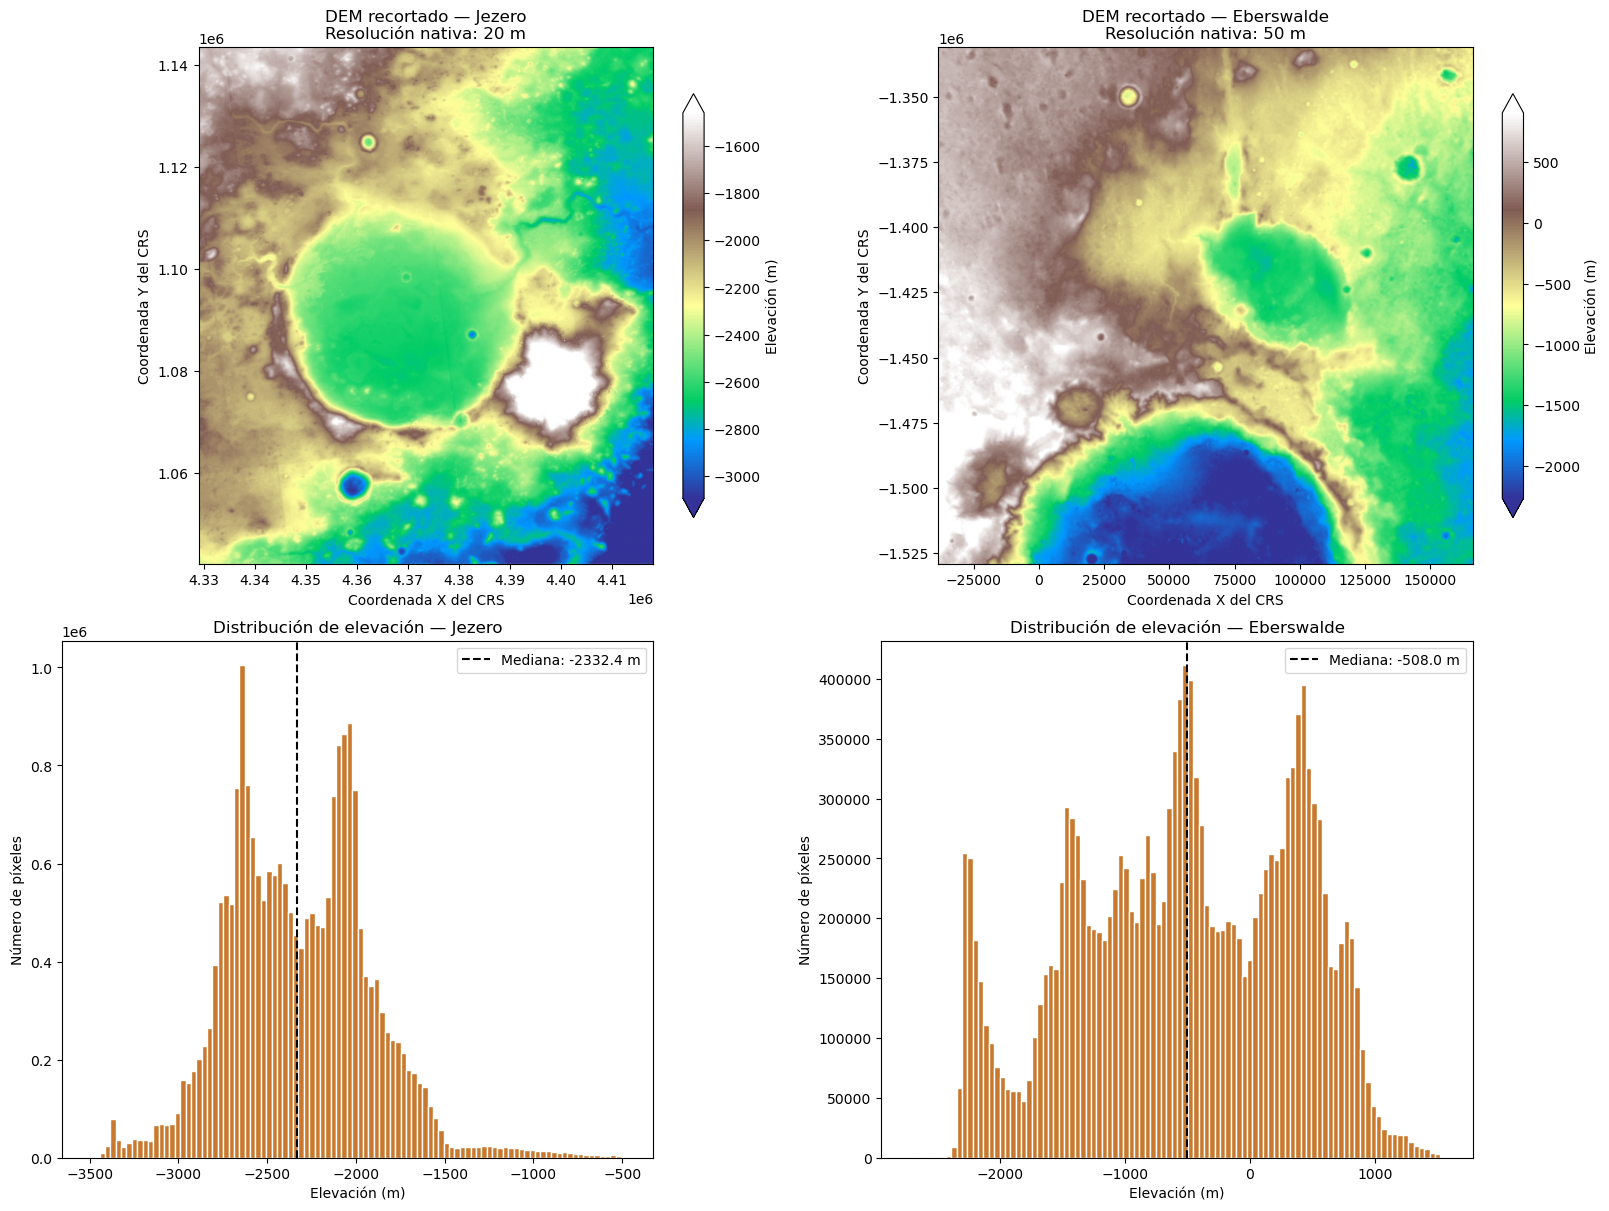

In [28]:
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from pathlib import Path
from rasterio.windows import Window, from_bounds
from rasterio.windows import WindowError


# ============================================================
# 1. EDA OF THE FINAL CSV
# ============================================================

csv_path = OUTPUT_CSV if "OUTPUT_CSV" in globals() else Path(
    "mars_craters_initial.csv"
)

mars_profile_final = pd.read_csv(csv_path)

print("=== EDA: FINAL CSV OF MARTIAN PROFILES ===")
print(f"File: {csv_path.resolve()}")
print(f"Dimensions: {mars_profile_final.shape[0]} rows × {mars_profile_final.shape[1]} columns")
print(f"Craters: {mars_profile_final['site'].tolist()}")

main_features = [
    "site",
    "elev_std_m",
    "slope_p50",
    "slope_p95",
    "rough_p50",
    "rough_p95",
    "ir_temp_p10_k",
    "ir_temp_p50_k",
    "ir_temp_p90_k",
    "ir_temp_std_k",
    "vis_albedo_p50",
    "vis_albedo_std",
]

coverage_columns = [
    "dem_roi_coverage_pct",
    "ir_temp_roi_coverage_pct",
    "vis_albedo_roi_coverage_pct",
]

print("\n=== FEATURES PRINCIPALES ===")
display(
    mars_profile_final[
        [col for col in main_features if col in mars_profile_final.columns]
    ].round(4)
)

print("\n=== DATA COVERAGE ===")
display(
    mars_profile_final[
        ["site"] + [col for col in coverage_columns if col in mars_profile_final.columns]
    ].round(2)
)

print("\n=== VALORES FALTANTES ===")
missing = mars_profile_final.isna().sum()
display(
    missing[missing > 0].to_frame("null_counts")
    if missing.sum() > 0
    else pd.DataFrame({"result_value": ["No missing values"]})
)

print("\n=== NUMERIC SUMMARY ===")
display(
    mars_profile_final.select_dtypes(include="number").T.round(4)
)

for _, row in mars_profile_final.iterrows():
    print(f"\n--- {row['site'].upper()} ---")

    for column in coverage_columns:
        if column in mars_profile_final.columns:
            coverage = row[column]

            if pd.isna(coverage):
                print(f"{column}: not available")
            elif coverage < 50:
                print(f"{column}: {coverage:.1f}%  ⚠ low coverage")
            elif coverage < 80:
                print(f"{column}: {coverage:.1f}%  ◐ partial coverage")
            else:
                print(f"{column}: {coverage:.1f}%  ✓ adequate coverage")


# ============================================================
# 2. NATIVE READ OF EACH DEM, CLIPPED TO THE ROI
# ============================================================

def read_dem_roi_native(dem_path, geographic_bounds):
    """Reads the DEM at native resolution, limited to the crater ROI."""
    with rasterio.open(dem_path) as src:
        left, bottom, right, top = mars_bounds_to_raster_bounds(
            src,
            geographic_bounds,
        )

        requested_window = from_bounds(
            left,
            bottom,
            right,
            top,
            transform=src.transform,
        ).round_offsets().round_lengths()

        full_window = Window(0, 0, src.width, src.height)

        try:
            crop_window = requested_window.intersection(full_window)
        except WindowError:
            raise ValueError(f"The ROI does not intersect: {dem_path}")

        data = src.read(1, window=crop_window, masked=True).astype(np.float64)
        data = np.ma.masked_invalid(data)

        transform = src.window_transform(crop_window)
        bounds = rasterio.transform.array_bounds(
            data.shape[0],
            data.shape[1],
            transform,
        )

        return {
            "data": data,
            "bounds": bounds,
            "resolution": src.res,
            "crs": src.crs,
            "width": src.width,
            "height": src.height,
        }


# ============================================================
# 3. MAPS AND HISTOGRAMS OF THE TWO TIFFs
# ============================================================

dem_rois = {}

for site, dem_path in DEM_PATHS.items():
    dem_rois[site] = read_dem_roi_native(
        dem_path,
        SITES[site],
    )

fig, axes = plt.subplots(2, 2, figsize=(16, 12), constrained_layout=True)

for column, site in enumerate(["jezero", "eberswalde"]):
    info = dem_rois[site]
    dem = info["data"]
    bounds = info["bounds"]
    valid = dem.compressed()

    vmin, vmax = np.percentile(valid, [2, 98])

    cmap = plt.colormaps["terrain"].copy()
    cmap.set_bad("lightgray")

    # DEM map
    ax_map = axes[0, column]

    image = ax_map.imshow(
        dem,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        extent=[bounds[0], bounds[2], bounds[1], bounds[3]],
        origin="upper",
    )

    ax_map.set_title(
        f"DEM recortado — {site.capitalize()}\n"
        f"Native resolution: {info['resolution'][0]:.0f} m"
    )
    ax_map.set_xlabel("CRS X coordinate")
    ax_map.set_ylabel("CRS Y coordinate")

    colorbar = fig.colorbar(image, ax=ax_map, shrink=0.82, extend="both")
    colorbar.set_label("Elevation (m)")

    # DEM histogram
    ax_hist = axes[1, column]

    ax_hist.hist(valid, bins=100, color="#c8792f", edgecolor="white")
    ax_hist.axvline(
        np.median(valid),
        color="black",
        linestyle="--",
        label=f"Median: {np.median(valid):.1f} m",
    )

    ax_hist.set_title(f"Elevation distribution — {site.capitalize()}")
    ax_hist.set_xlabel("Elevation (m)")
    ax_hist.set_ylabel("Number of pixels")
    ax_hist.legend()

plt.show()

## 7. Expanding the Analysis to Five Craters


### 7.1 Adding DEM/DTM Paths for Gale, Holden, and Saheki


In [ ]:
from pathlib import Path

# Paste the local paths of your new DEMs/DTMs here.
GALE_DEM_PATH = Path("data/gale_dtm.tif")
HOLDEN_DEM_PATH = Path("data/holden.tif")
SAHEKI_DEM_PATH = Path("PASTE_SAHEKI_PATH_HERE.tif")

# Add them to the existing dictionary without removing Jezero or Eberswalde.
DEM_PATHS.update({
    "gale": GALE_DEM_PATH,
    "holden": HOLDEN_DEM_PATH,
    "saheki": SAHEKI_DEM_PATH,
})

print("=== DEM DISPONIBLES ===")
for site, path_value in DEM_PATHS.items():
    print(f"{site}: {path_value}")

=== DEM DISPONIBLES ===
jezero: data/M20_JezeroCrater_CTXDEM_20m.tif
eberswalde: data/eberswalde_dtm.tif
gale: data/gale_dtm.tif
holden: data/holden.tif
saheki: data/PIA23380.tif


### 7.2 Exploring and Checking the New TIFF Files


/opt/anaconda3/lib/python3.13/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


=== EDA: NUEVOS TIFF MARCIANOS ===


,site,file_entry,dimensions_px,bands,dtype,is_dem_candidate,crs,resolution_x,resolution_y,nodata,...,valid_pixel_count,valid_coverage_pct,min,p2,median_value,mean_value,p98,max,std,relief_value
0,gale,gale_dtm.tif,4150 × 5500,1,int16,True,"PROJCS[""SINUSOIDAL MARS"",GEOGCS[""GCS_MARS"",DAT...",50.0,50.0,-32768.0,...,22825000,100.0,-4687.0,-4344.0,-1419.0,-1452.209844,590.0,1461.0,1394.386393,6148.0
1,holden,holden.tif,1510 × 2976,1,uint8,True,None,1.0,1.0,NaN,...,4493760,100.0,0.0,0.0,108.0,88.672537,195.0,255.0,62.737429,255.0
2,saheki,PIA23380.tif,3639 × 2535,3,uint8,False,None,1.0,1.0,NaN,...,9224865,100.0,0.0,50.0,152.0,142.205904,238.0,255.0,40.288919,255.0


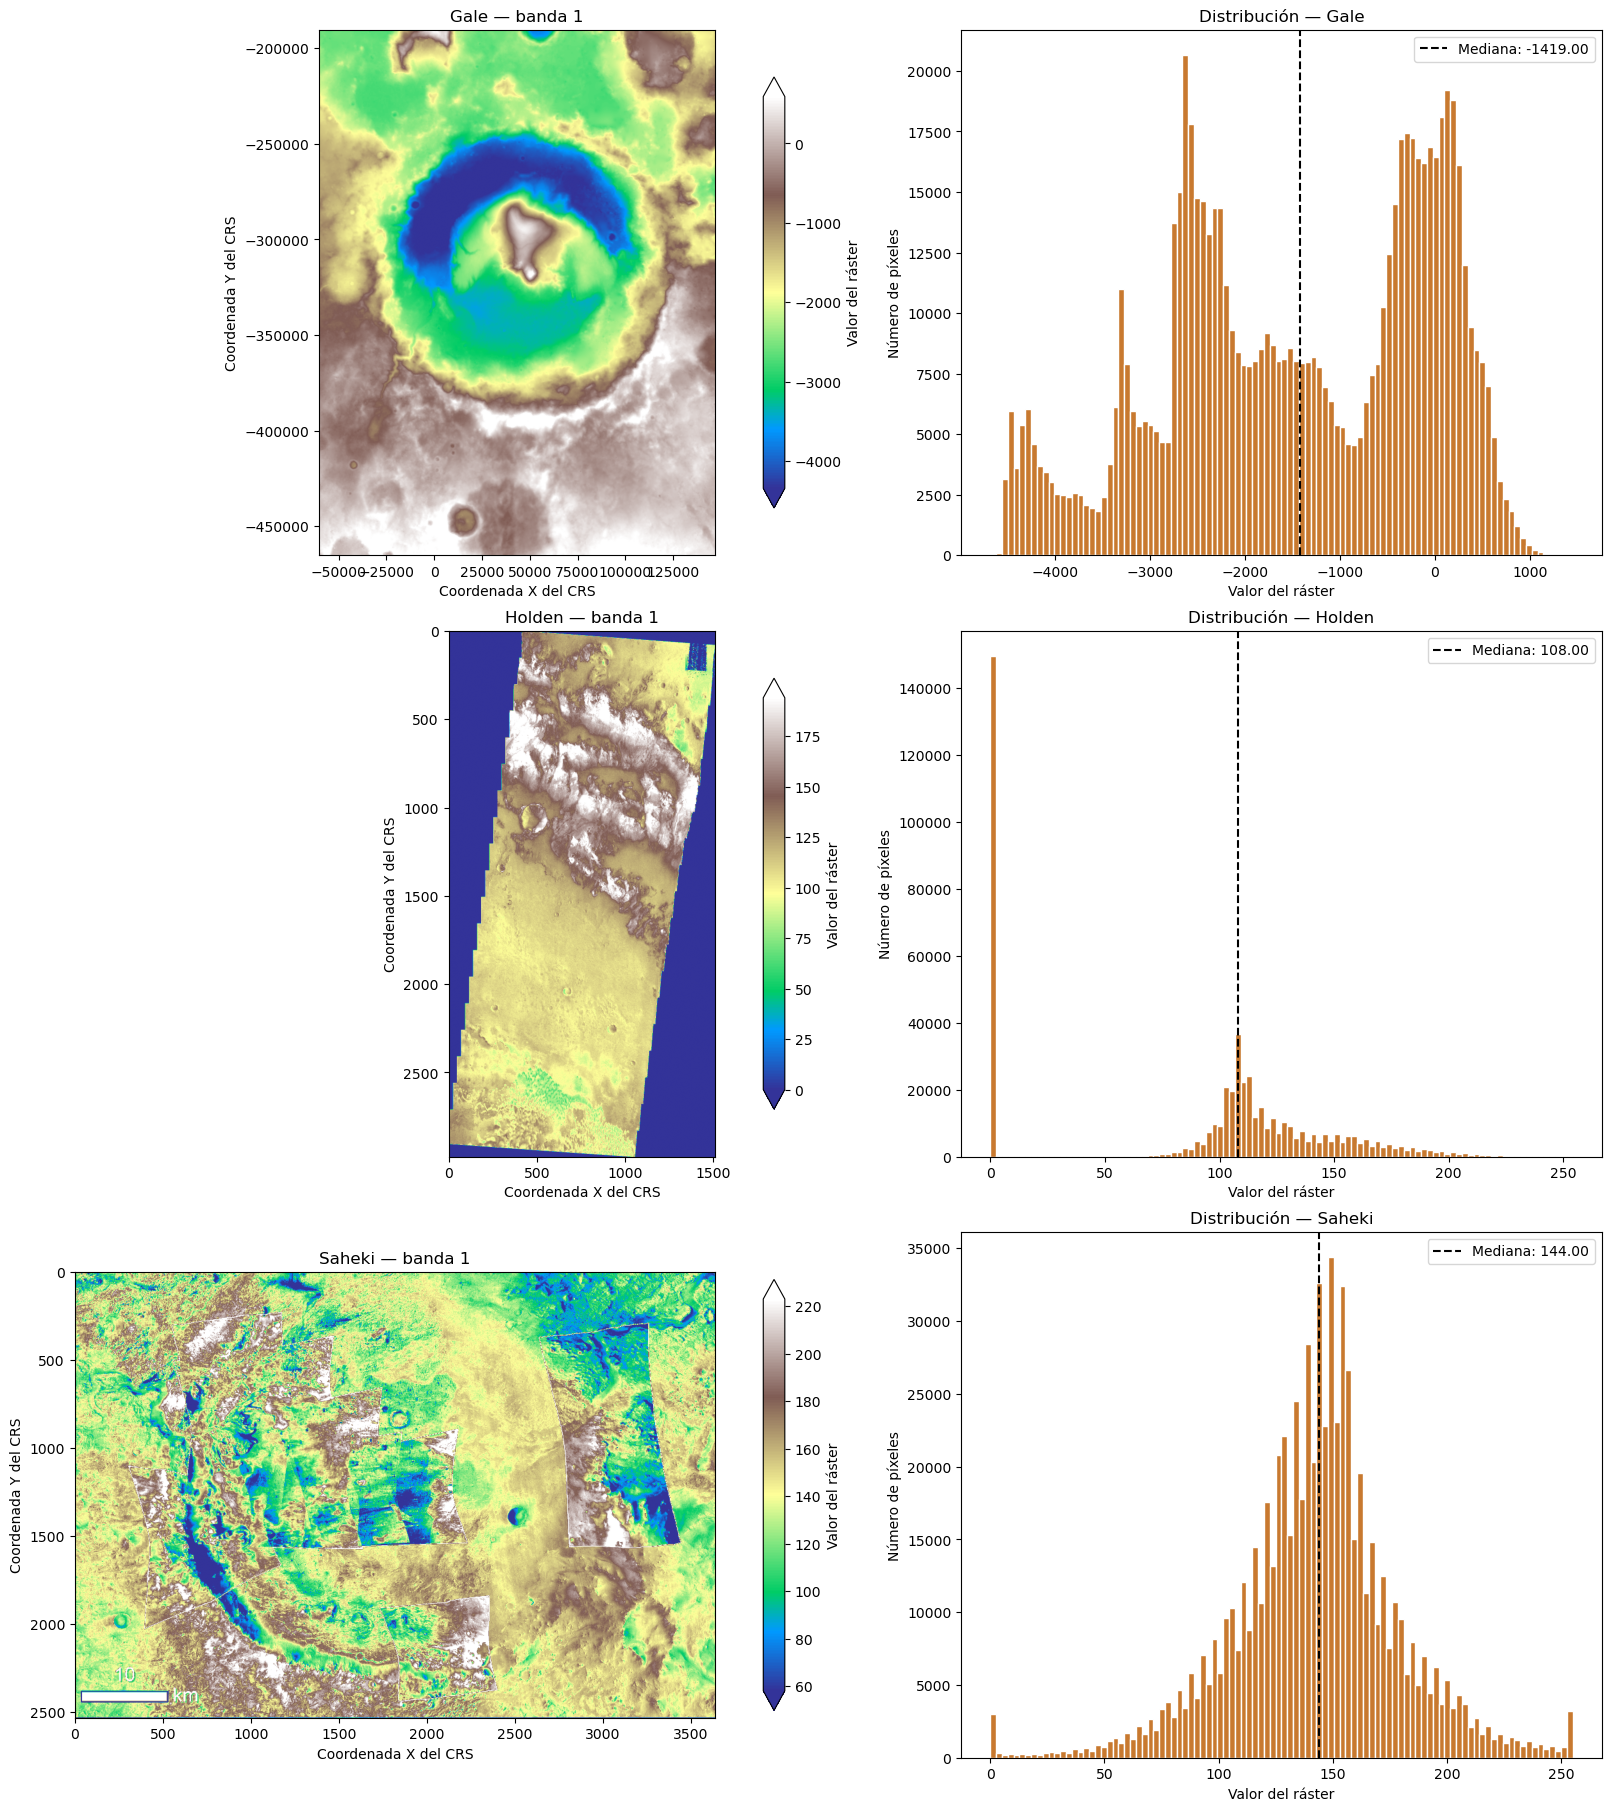

In [30]:
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from rasterio.enums import Resampling


NEW_SITES = ["gale", "holden", "saheki"]


def raster_preview(src, band=1, max_side=1000):
    scale = max(src.height / max_side, src.width / max_side, 1)

    out_height = max(1, int(src.height / scale))
    out_width = max(1, int(src.width / scale))

    return src.read(
        band,
        out_shape=(out_height, out_width),
        masked=True,
        resampling=Resampling.average,
    )


summaries = []
previews = {}

for site in NEW_SITES:
    path = DEM_PATHS[site]

    with rasterio.open(path) as src:
        data = src.read(1, masked=True).astype(np.float64)
        values = data.compressed()

        if values.size == 0:
            raise ValueError(f"{site}: band 1 has no valid pixels.")

        preview = raster_preview(src)
        previews[site] = {
            "data": preview,
            "bounds": src.bounds,
        }

        # This is an initial signal, not a final certification.
        dem_candidate = (
            src.count == 1
            and np.issubdtype(np.dtype(src.dtypes[0]), np.number)
        )

        summaries.append({
            "site": site,
            "file_entry": path.name,
            "dimensions_px": f"{src.width} × {src.height}",
            "bands": src.count,
            "dtype": src.dtypes[0],
            "is_dem_candidate": dem_candidate,
            "crs": str(src.crs),
            "resolution_x": src.res[0],
            "resolution_y": src.res[1],
            "nodata": src.nodata,
            "total_pixel_count": src.width * src.height,
            "valid_pixel_count": values.size,
            "valid_coverage_pct": 100 * values.size / (src.width * src.height),
            "min": np.min(values),
            "p2": np.percentile(values, 2),
            "median_value": np.median(values),
            "mean_value": np.mean(values),
            "p98": np.percentile(values, 98),
            "max": np.max(values),
            "std": np.std(values),
            "relief_value": np.max(values) - np.min(values),
        })

eda_new_dems = pd.DataFrame(summaries)

print("=== EDA: NUEVOS TIFF MARCIANOS ===")
display(eda_new_dems)


# Mapas e histogramas
fig, axes = plt.subplots(3, 2, figsize=(16, 18), constrained_layout=True)

for row, site in enumerate(NEW_SITES):
    data = previews[site]["data"]
    bounds = previews[site]["bounds"]
    values = data.compressed()

    vmin, vmax = np.percentile(values, [2, 98])

    cmap = plt.colormaps["terrain"].copy()
    cmap.set_bad("lightgray")

    image = axes[row, 0].imshow(
        data,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        extent=[bounds.left, bounds.right, bounds.bottom, bounds.top],
        origin="upper",
    )

    axes[row, 0].set_title(f"{site.capitalize()} — banda 1")
    axes[row, 0].set_xlabel("CRS X coordinate")
    axes[row, 0].set_ylabel("CRS Y coordinate")

    colorbar = fig.colorbar(image, ax=axes[row, 0], shrink=0.82, extend="both")
    colorbar.set_label("Raster value")

    axes[row, 1].hist(
        values,
        bins=100,
        color="#c8792f",
        edgecolor="white",
    )
    axes[row, 1].axvline(
        np.median(values),
        color="black",
        linestyle="--",
        label=f"Median: {np.median(values):.2f}",
    )

    axes[row, 1].set_title(f"Distribution — {site.capitalize()}")
    axes[row, 1].set_xlabel("Raster value")
    axes[row, 1].set_ylabel("Number of pixels")
    axes[row, 1].legend()

plt.show()

### 7.3 Reviewing Available HRSC and HiRISE Products


In [1]:
import requests
import pandas as pd


ODE_URL = "https://oderest.rsl.wustl.edu/live2/"

response = requests.get(
    ODE_URL,
    params={
        "query": "iipt",
        "odemetadb": "mars",
        "output": "JSON",
    },
    timeout=120,
)

response.raise_for_status()

payload = response.json()
ode_results = payload.get("ODEResults", payload)

status = str(
    ode_results.get("Status", ode_results.get("status", "UNKNOWN"))
).upper()

if status != "SUCCESS":
    error = ode_results.get("Error", ode_results.get("error", "No detail"))
    raise RuntimeError(f"ODE answered {status}: {error}")

iipt_sets = ode_results.get("IIPTSets", {}).get("IIPTSet", [])

if isinstance(iipt_sets, dict):
    iipt_sets = [iipt_sets]

iipt_catalog = pd.json_normalize(iipt_sets)

print("Available columns:")
print(iipt_catalog.columns.tolist())

# Normalise column names so case does not matter.
column_lookup = {column.lower(): column for column in iipt_catalog.columns}

ihid_col = column_lookup.get("ihid")
iid_col = column_lookup.get("iid")
pt_col = column_lookup.get("pt")
pt_name_col = column_lookup.get("ptname")

if not all([ihid_col, iid_col, pt_col]):
    raise KeyError(
        "ODE did not return the expected IHID, IID and PT columns. "
        f"Columns: {iipt_catalog.columns.tolist()}"
    )

# All available HRSC and HiRISE products.
relevant_iipt = iipt_catalog.loc[
    (
        iipt_catalog[ihid_col].astype(str).str.upper().isin(["MEX", "MRO"])
    )
    &
    (
        iipt_catalog[iid_col].astype(str).str.upper().isin(["HRSC", "HIRISE"])
    )
].copy()

columns_to_show = [ihid_col, iid_col, pt_col]

if pt_name_col:
    columns_to_show.append(pt_name_col)

print("\n=== AVAILABLE PRODUCTS: HRSC AND HIRISE ===")
display(
    relevant_iipt[columns_to_show]
    .sort_values([ihid_col, iid_col, pt_col])
    .reset_index(drop=True)
)

# Preliminary filter of products containing DTM or TERRAIN in type/name.
search_text = relevant_iipt[pt_col].astype(str)

if pt_name_col:
    search_text = (
        search_text
        + " "
        + relevant_iipt[pt_name_col].astype(str)
    )

dtm_iipt = relevant_iipt.loc[
    search_text.str.contains(
        r"DTM|DIGITAL.*TERRAIN|TERRAIN.*MODEL",
        case=False,
        regex=True,
        na=False,
    )
].copy()

print("\n=== CANDIDATOS DTM DETECTADOS ===")
display(
    dtm_iipt[columns_to_show]
    .sort_values([ihid_col, iid_col, pt_col])
    .reset_index(drop=True)
)

Available columns:
['DataSetId', 'IHID', 'IHName', 'IID', 'IName', 'ODEMetaDB', 'PT', 'PTName', 'ValidEmissionAngles', 'ValidFootprints', 'ValidIncidenceAngles', 'ValidObservationTimes', 'ValidPhaseAngles', 'ValidSolLongs', 'ValidTargets.ValidTarget', 'MaxObservationTime', 'MaxOrbit', 'MaxProductId', 'MinObservationTime', 'MinProductId', 'NumberProducts', 'MinOrbit', 'NumberObservations']

=== AVAILABLE PRODUCTS: HRSC AND HIRISE ===


,IHID,IID,PT,PTName
0,MEX,HRSC,DTMRDR,PDS3 Orthophoto and Digital Terrain Map
1,MEX,HRSC,PHOBOS,"PDS3 High Resolution Images, DTMs, and Mosaics..."
2,MEX,HRSC,RDRV4,PDS3 Version 4 Reduced Data Record
3,MEX,HRSC,REFDR3,PDS3 Version 3 Map Projected Reduced Data Record
4,MEX,HRSC,REFDR4,PDS3 Version 4 Map Projected Reduced Data Record
5,MRO,HIRISE,ANAGLY,PDS4 Anaglyph Image
6,MRO,HIRISE,DTM,PDS3 Digital Terrain Model
7,MRO,HIRISE,EDR,PDS3 Experiment Data Record
8,MRO,HIRISE,EDR4,PDS4 Experiment Data Record - Raw Image
9,MRO,HIRISE,RDR,PDS3 Reduced Data Record w/o Embedded Map Proj...



=== CANDIDATOS DTM DETECTADOS ===


,IHID,IID,PT,PTName
0,MEX,HRSC,DTMRDR,PDS3 Orthophoto and Digital Terrain Map
1,MEX,HRSC,PHOBOS,"PDS3 High Resolution Images, DTMs, and Mosaics..."
2,MRO,HIRISE,DTM,PDS3 Digital Terrain Model


### 7.4 Searching for DTM Candidates in PDS/ODE for Holden and Saheki


In [5]:
import requests
import pandas as pd


# ============================================================
# 1. OFFICIAL ROIs OF THE TWO CRATERS
# ============================================================

SITES = {
    "holden": {
        "minlat": -27.33,
        "maxlat": -24.75,
        "westernlon": 324.55,
        "easternlon": 327.42,
    },
    "saheki": {
        "minlat": -22.44,
        "maxlat": -21.05,
        "westernlon": 72.39,
        "easternlon": 73.88,
    },
}

display(pd.DataFrame(SITES).T)

print("=== ROI FOR PDS SEARCH ===")
display(pd.DataFrame(SITES).T.loc[["holden", "saheki"]])


# ============================================================
# 2. CONSULTA PDS / ODE
# ============================================================

ODE_URL = "https://oderest.rsl.wustl.edu/live2/"

DTM_SOURCES = [
    {
        "dtm_source": "HRSC_DTMRDR",
        "ihid": "MEX",
        "iid": "HRSC",
        "pt": "DTMRDR",
    },
    {
        "dtm_source": "HiRISE_DTM",
        "ihid": "MRO",
        "iid": "HIRISE",
        "pt": "DTM",
    },
]


def ode_request(params):
    response = requests.get(ODE_URL, params=params, timeout=120)
    response.raise_for_status()

    payload = response.json()
    ode_results = payload.get("ODEResults", payload)

    status = str(
        ode_results.get("Status", ode_results.get("status", "UNKNOWN"))
    ).upper()

    if status != "SUCCESS":
        error = ode_results.get("Error", ode_results.get("error", "No detail"))
        raise RuntimeError(f"ODE answered {status}: {error}")

    return ode_results


def ode_count(bounds, source):
    """Counts candidates before fetching their metadata."""
    params = {
        "target": "mars",
        "query": "product",
        "results": "c",
        "output": "JSON",
        "ihid": source["ihid"],
        "iid": source["iid"],
        "pt": source["pt"],
        "minlat": bounds["minlat"],
        "maxlat": bounds["maxlat"],
        "westernlon": bounds["westernlon"],
        "easternlon": bounds["easternlon"],
        "loc": "f",
    }

    result = ode_request(params)

    return int(result.get("Count", 0))


def ode_search_dtm(site_name, bounds, source, limit=100):
    """Fetches metadata and file URLs, without downloading."""
    params = {
        "target": "mars",
        "query": "product",
        "results": "copmf",
        "output": "JSON",
        "ihid": source["ihid"],
        "iid": source["iid"],
        "pt": source["pt"],
        "minlat": bounds["minlat"],
        "maxlat": bounds["maxlat"],
        "westernlon": bounds["westernlon"],
        "easternlon": bounds["easternlon"],
        "loc": "f",
        "limit": limit,
        "offset": 0,
    }

    result = ode_request(params)

    products = result.get("Products", {}).get("Product", [])

    if isinstance(products, dict):
        products = [products]

    df = pd.json_normalize(products)

    if df.empty:
        return df

    df["site"] = site_name
    df["dtm_source"] = source["dtm_source"]

    return df


# ============================================================
# 3. SEARCH AND MANIFEST
# ============================================================

frames = []

for site_name in ["holden", "saheki"]:
    bounds = SITES[site_name]

    for source in DTM_SOURCES:
        count = ode_count(bounds, source)

        print(
            f"{site_name.capitalize()} | {source['dtm_source']}: "
            f"{count} candidate_rows encontrados"
        )

        if count == 0:
            continue

        result = ode_search_dtm(
            site_name=site_name,
            bounds=bounds,
            source=source,
            limit=min(count, 100),
        )

        if not result.empty:
            frames.append(result)

dtm_candidates = (
    pd.concat(frames, ignore_index=True)
    if frames
    else pd.DataFrame()
)

print(f"\n=== TOTAL DTM CANDIDATES: {len(dtm_candidates)} ===")

columns_to_show = [
    "site",
    "dtm_source",
    "pdsid",
    "Map_resolution",
    "Center_latitude",
    "Center_longitude",
    "Minimum_latitude",
    "Maximum_latitude",
    "Westernmost_longitude",
    "Easternmost_longitude",
    "ProductURL",
    "LabelURL",
    "Product_files.Product_file",
]

display(
    dtm_candidates[
        [col for col in columns_to_show if col in dtm_candidates.columns]
    ]
)

dtm_candidates.to_csv(
    "dtm_candidates_holden_saheki.csv",
    index=False,
)

print("\nFile created: dtm_candidates_holden_saheki.csv")

,minlat,maxlat,westernlon,easternlon
holden,-27.33,-24.75,324.55,327.42
saheki,-22.44,-21.05,72.39,73.88


=== ROI FOR PDS SEARCH ===


,minlat,maxlat,westernlon,easternlon
holden,-27.33,-24.75,324.55,327.42
saheki,-22.44,-21.05,72.39,73.88


Holden | HRSC_DTMRDR: 43 candidate_rows encontrados
Holden | HiRISE_DTM: 9 candidate_rows encontrados
Saheki | HRSC_DTMRDR: 7 candidate_rows encontrados
Saheki | HiRISE_DTM: 0 candidate_rows encontrados

=== TOTAL DTM CANDIDATES: 59 ===


,site,dtm_source,pdsid,Map_resolution,Center_latitude,Center_longitude,Minimum_latitude,Maximum_latitude,Westernmost_longitude,Easternmost_longitude,ProductURL,LabelURL,Product_files.Product_file
0,holden,HRSC_DTMRDR,H2002_0000_BL4.IMG,1185.42760773333,-24.6995,326.8649,-27.7312,-21.6598,325.921,327.928,https://ode.rsl.wustl.edu/mars/indexproductpag...,https://pds-geosciences.wustl.edu/mex/mex-m-hr...,"[{'Creation_date': '2014-06-05T08:35:38.180', ..."
1,holden,HRSC_DTMRDR,H2002_0000_DA4.IMG,592.713803866667,-24.6988,326.8649,-27.7314,-21.6582,325.921,327.931,https://ode.rsl.wustl.edu/mars/indexproductpag...,https://pds-geosciences.wustl.edu/mex/mex-m-hr...,"[{'Creation_date': '2014-06-05T08:35:38.180', ..."
2,holden,HRSC_DTMRDR,H2002_0000_DT4.IMG,592.713803866667,-24.6988,326.8649,-27.7314,-21.6582,325.921,327.931,https://ode.rsl.wustl.edu/mars/indexproductpag...,https://pds-geosciences.wustl.edu/mex/mex-m-hr...,"[{'Creation_date': '2014-06-05T08:35:38.180', ..."
3,holden,HRSC_DTMRDR,H2002_0000_GR4.IMG,1185.42760773333,-24.699,326.8664,-27.7301,-21.6581,325.92,327.929,https://ode.rsl.wustl.edu/mars/indexproductpag...,https://pds-geosciences.wustl.edu/mex/mex-m-hr...,"[{'Creation_date': '2014-06-05T08:35:38.180', ..."
4,holden,HRSC_DTMRDR,H2002_0000_IR4.IMG,1185.42760773333,-24.6982,326.8659,-27.73,-21.6581,325.92,327.93,https://ode.rsl.wustl.edu/mars/indexproductpag...,https://pds-geosciences.wustl.edu/mex/mex-m-hr...,"[{'Creation_date': '2014-06-05T08:35:38.180', ..."
5,holden,HRSC_DTMRDR,H2002_0000_ND4.IMG,4741.71043093333,-24.6988,326.8649,-27.7314,-21.6582,325.921,327.931,https://ode.rsl.wustl.edu/mars/indexproductpag...,https://pds-geosciences.wustl.edu/mex/mex-m-hr...,"[{'Creation_date': '2014-06-05T08:35:38.180', ..."
6,holden,HRSC_DTMRDR,H2002_0000_RE4.IMG,1185.42760773333,-24.6999,326.8659,-27.7312,-21.6581,325.922,327.932,https://ode.rsl.wustl.edu/mars/indexproductpag...,https://pds-geosciences.wustl.edu/mex/mex-m-hr...,"[{'Creation_date': '2014-06-05T08:35:38.180', ..."
7,holden,HRSC_DTMRDR,H2013_0000_DA4.IMG,790.285071822222,-24.6006,326.4788,-27.4851,-21.7158,325.465,327.375,https://ode.rsl.wustl.edu/mars/indexproductpag...,https://pds-geosciences.wustl.edu/mex/mex-m-hr...,"[{'Creation_date': '2014-06-05T08:35:38.180', ..."
8,holden,HRSC_DTMRDR,H2013_0000_DT4.IMG,790.285071822222,-24.6006,326.4788,-27.4851,-21.7158,325.465,327.375,https://ode.rsl.wustl.edu/mars/indexproductpag...,https://pds-geosciences.wustl.edu/mex/mex-m-hr...,"[{'Creation_date': '2014-06-05T08:35:38.180', ..."
9,holden,HRSC_DTMRDR,H2013_0000_ND4.IMG,4741.71043093333,-24.6006,326.4788,-27.4851,-21.7158,325.465,327.375,https://ode.rsl.wustl.edu/mars/indexproductpag...,https://pds-geosciences.wustl.edu/mex/mex-m-hr...,"[{'Creation_date': '2014-06-05T08:35:38.180', ..."



File created: dtm_candidates_holden_saheki.csv


### 7.5 Downloading Regional DTMs for Validation


In [6]:
ANALYSIS_RESOLUTION_M = 500.0
ROUGHNESS_WINDOW_M = 2500.0 

from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import requests


# Regional DTM for each crater.
SELECTED_DTMS = {
    "holden": "H0511_0000_DT4.IMG",
    "saheki": "H6491_0000_DT4.IMG",
}

DOWNLOAD_DIR = Path("pds_dtms")
DOWNLOAD_DIR.mkdir(exist_ok=True)


def product_files_as_list(value):
    """Converts Product_files.Product_file to a list of dictionaries."""
    if isinstance(value, dict):
        return [value]

    if isinstance(value, list):
        return [item for item in value if isinstance(item, dict)]

    return []


def get_file_url(file_record):
    for key in ("URL", "Url", "url"):
        value = file_record.get(key)

        if value:
            return str(value)

    return None


def get_filename(file_record):
    url = get_file_url(file_record)

    if url is None:
        return None

    return Path(urlparse(url).path).name


def download_if_missing(url, destination):
    """Downloads a file without overwriting previous downloads."""
    if destination.exists():
        print(f"Ya existe: {destination.name}")
        return destination

    with requests.get(url, stream=True, timeout=180) as response:
        response.raise_for_status()

        with open(destination, "wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    output.write(chunk)

    print(f"Descargado: {destination.name}")
    return destination


downloads = []

for site, pdsid in SELECTED_DTMS.items():
    matches = dtm_candidates.loc[
        (dtm_candidates["site"] == site)
        & (dtm_candidates["pdsid"].astype(str).str.upper() == pdsid.upper())
    ]

    if matches.empty:
        raise ValueError(f"Not found: {pdsid} in dtm_candidates.")

    row = matches.iloc[0]
    files = product_files_as_list(row["Product_files.Product_file"])

    # Pick specifically the IMG whose name matches the PDS ID.
    raster_record = next(
        (
            item for item in files
            if get_filename(item)
            and get_filename(item).upper() == pdsid.upper()
        ),
        None,
    )

    if raster_record is None:
        raise ValueError(
            f"Main IMG not found for {pdsid}. "
            "Revisa Product_files.Product_file."
        )

    raster_url = get_file_url(raster_record)
    scene_dir = DOWNLOAD_DIR / site / Path(pdsid).stem
    scene_dir.mkdir(parents=True, exist_ok=True)

    raster_path = download_if_missing(
        raster_url,
        scene_dir / get_filename(raster_record),
    )

    # The PDS label is needed to read the IMG correctly.
    label_path = None
    label_url = row.get("LabelURL")

    if pd.notna(label_url) and str(label_url).startswith(("http://", "https://")):
        label_name = Path(urlparse(str(label_url)).path).name

        label_path = download_if_missing(
            str(label_url),
            scene_dir / label_name,
        )

    downloads.append({
        "site": site,
        "pdsid": pdsid,
        "raster_path": str(raster_path),
        "label_path": str(label_path) if label_path else None,
        "map_resolution_m": row.get("Map_resolution"),
        "minlat": row.get("Minimum_latitude"),
        "maxlat": row.get("Maximum_latitude"),
        "westernlon": row.get("Westernmost_longitude"),
        "easternlon": row.get("Easternmost_longitude"),
    })

downloaded_dtms = pd.DataFrame(downloads)

print("=== DTMs DOWNLOADED FOR VALIDATION ===")
display(downloaded_dtms)

Descargado: h0511_0000_dt4.img
Ya existe: h0511_0000_dt4.img
Descargado: h6491_0000_dt4.img
Ya existe: h6491_0000_dt4.img
=== DTMs DOWNLOADED FOR VALIDATION ===


,site,pdsid,raster_path,label_path,map_resolution_m,minlat,maxlat,westernlon,easternlon
0,holden,H0511_0000_DT4.IMG,pds_dtms/holden/H0511_0000_DT4/h0511_0000_dt4.img,pds_dtms/holden/H0511_0000_DT4/h0511_0000_dt4.img,474.171043093333,-44.6191,-19.6007,323.371,327.458
1,saheki,H6491_0000_DT4.IMG,pds_dtms/saheki/H6491_0000_DT4/h6491_0000_dt4.img,pds_dtms/saheki/H6491_0000_DT4/h6491_0000_dt4.img,474.171043093333,-22.1003,-13.6915,71.3976,74.3023


### 7.6 Exploring the Downloaded HRSC DTMs


=== EDA: DTM HRSC DESCARGADOS ===


,site,pdsid,opened_file,dimensions_px,bands,dtype,crs,resolution_x_m,resolution_y_m,nodata,...,valid_pixel_count,valid_coverage_pct,min,p2,median_value,mean_value,p98,max,std,relief_m
0,holden,H0511_0000_DT4.IMG,pds_dtms/holden/H0511_0000_DT4/h0511_0000_dt4.img,1834 × 11860,1,int16,"PROJCS[""SINUSOIDAL MARS"",GEOGCS[""GCS_MARS"",DAT...",125.0,125.0,-32768.0,...,16491034,75.8165,-12087.0,-10412.0,-4872.0,-5340.8350,-1740.0,-437.0,2309.4385,11650.0
1,saheki,H6491_0000_DT4.IMG,pds_dtms/saheki/H6491_0000_DT4/h6491_0000_dt4.img,1373 × 3988,1,int16,"PROJCS[""SINUSOIDAL MARS"",GEOGCS[""GCS_MARS"",DAT...",125.0,125.0,-32768.0,...,4805588,87.7649,-5439.0,-4700.0,-714.0,-1006.9684,478.0,1411.0,1100.0902,6850.0


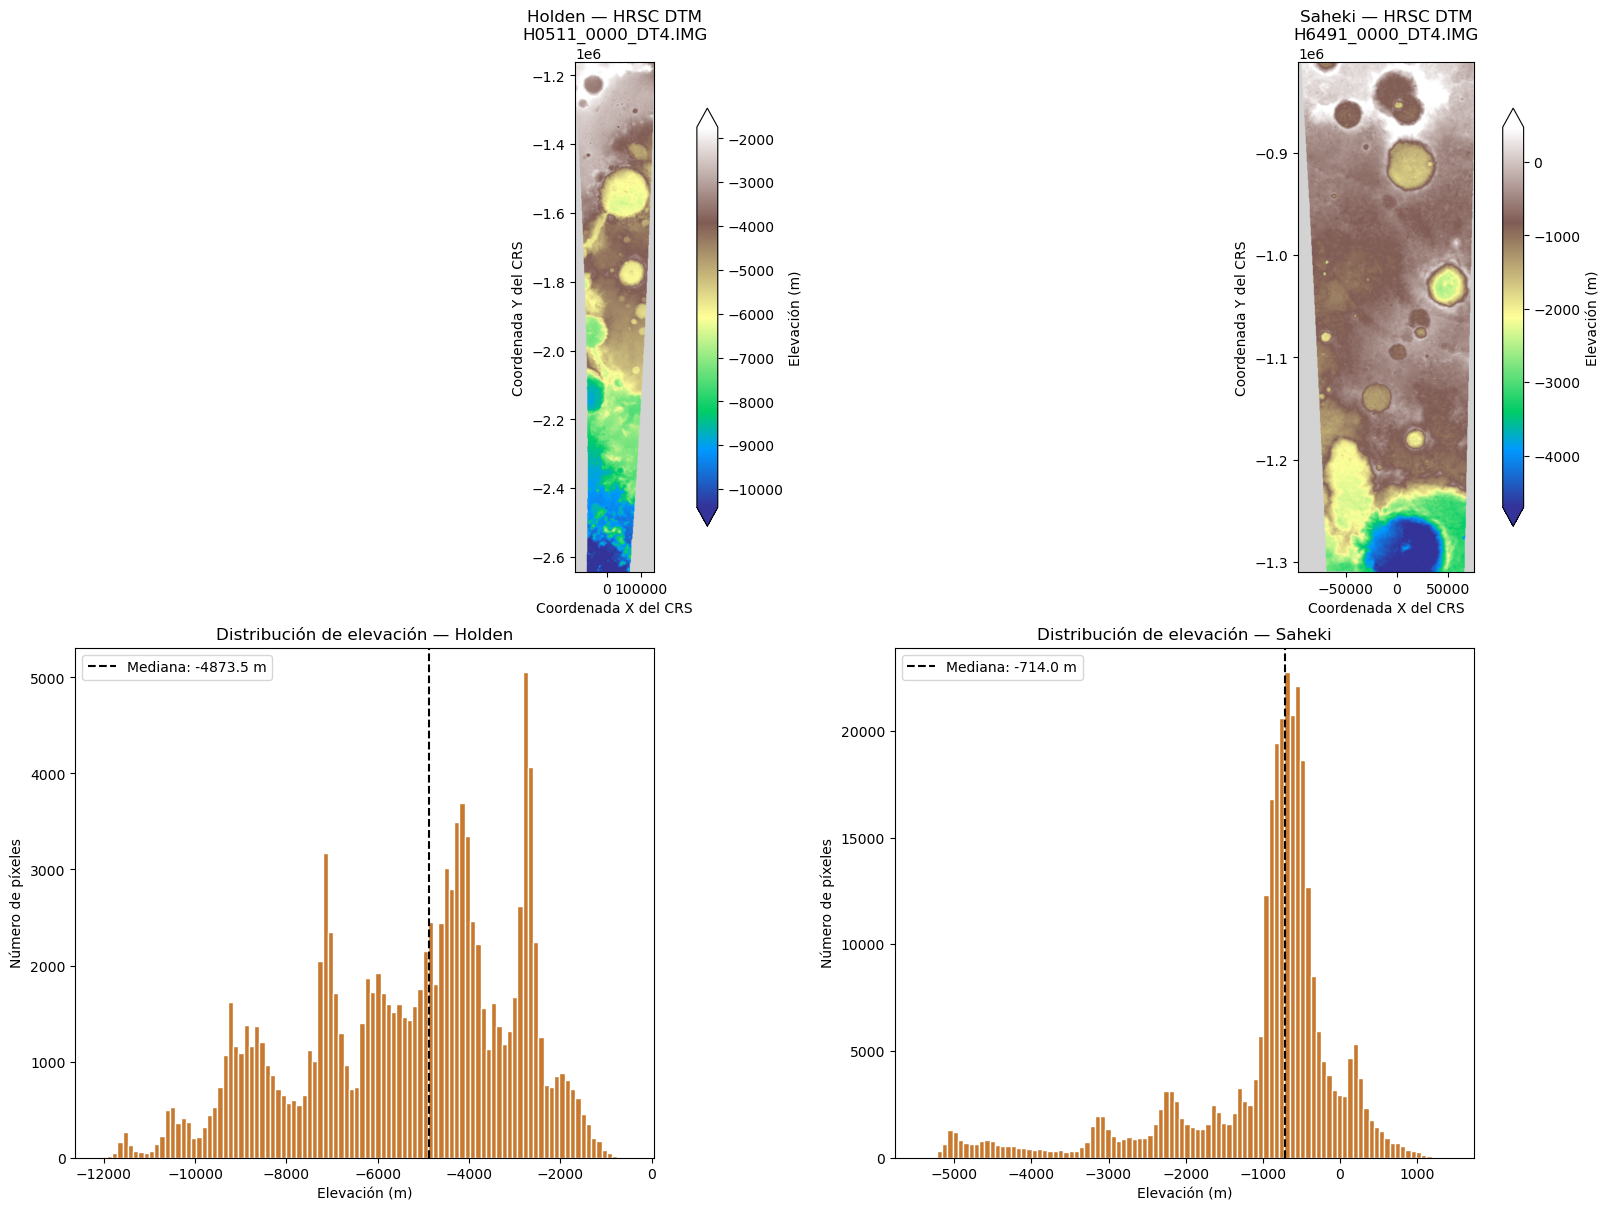

In [7]:
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from pathlib import Path
from rasterio.enums import Resampling
from rasterio.errors import RasterioIOError


def open_pds_dtm(row):
    """Tries the PDS label first and then the IMG."""
    candidates = [
        row.get("label_path"),
        row.get("raster_path"),
    ]

    errors = []

    for candidate in candidates:
        if candidate is None or pd.isna(candidate):
            continue

        path = Path(candidate)

        if not path.exists():
            continue

        try:
            return rasterio.open(path), path
        except RasterioIOError as error:
            errors.append(f"{path.name}: {error}")

    raise RuntimeError(
        f"Could not open {row['pdsid']}.\n" + "\n".join(errors)
    )


def preview_raster(src, max_side=1000):
    scale = max(src.width / max_side, src.height / max_side, 1)

    return src.read(
        1,
        out_shape=(
            max(1, int(src.height / scale)),
            max(1, int(src.width / scale)),
        ),
        masked=True,
        resampling=Resampling.average,
    )


summaries = []
previews = []

for _, row in downloaded_dtms.iterrows():
    with open_pds_dtm(row)[0] as src:
        data = src.read(1, masked=True).astype(np.float64)
        values = data.compressed()

        if values.size == 0:
            raise ValueError(f"{row['site']}: no valid pixels.")

        preview = preview_raster(src)

        summaries.append({
            "site": row["site"],
            "pdsid": row["pdsid"],
            "opened_file": src.name,
            "dimensions_px": f"{src.width} × {src.height}",
            "bands": src.count,
            "dtype": src.dtypes[0],
            "crs": str(src.crs),
            "resolution_x_m": src.res[0],
            "resolution_y_m": src.res[1],
            "nodata": src.nodata,
            "total_pixel_count": src.width * src.height,
            "valid_pixel_count": values.size,
            "valid_coverage_pct": (
                100 * values.size / (src.width * src.height)
            ),
            "min": np.min(values),
            "p2": np.percentile(values, 2),
            "median_value": np.median(values),
            "mean_value": np.mean(values),
            "p98": np.percentile(values, 98),
            "max": np.max(values),
            "std": np.std(values),
            "relief_m": np.max(values) - np.min(values),
        })

        previews.append({
            "site": row["site"],
            "pdsid": row["pdsid"],
            "data": preview,
            "bounds": src.bounds,
        })

eda_hrsc_dtms = pd.DataFrame(summaries)

print("=== EDA: DTM HRSC DESCARGADOS ===")
display(eda_hrsc_dtms.round(4))


# Mapas e histogramas
fig, axes = plt.subplots(2, 2, figsize=(16, 12), constrained_layout=True)

for column, item in enumerate(previews):
    data = item["data"]
    values = data.compressed()
    bounds = item["bounds"]

    vmin, vmax = np.percentile(values, [2, 98])

    cmap = plt.colormaps["terrain"].copy()
    cmap.set_bad("lightgray")

    image = axes[0, column].imshow(
        data,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        extent=[bounds.left, bounds.right, bounds.bottom, bounds.top],
        origin="upper",
    )

    axes[0, column].set_title(
        f"{item['site'].capitalize()} — HRSC DTM\n{item['pdsid']}"
    )
    axes[0, column].set_xlabel("CRS X coordinate")
    axes[0, column].set_ylabel("CRS Y coordinate")

    colorbar = fig.colorbar(
        image,
        ax=axes[0, column],
        shrink=0.82,
        extend="both",
    )
    colorbar.set_label("Elevation (m)")

    axes[1, column].hist(
        values,
        bins=100,
        color="#c8792f",
        edgecolor="white",
    )
    axes[1, column].axvline(
        np.median(values),
        color="black",
        linestyle="--",
        label=f"Median: {np.median(values):.1f} m",
    )

    axes[1, column].set_title(
        f"Elevation distribution — {item['site'].capitalize()}"
    )
    axes[1, column].set_xlabel("Elevation (m)")
    axes[1, column].set_ylabel("Number of pixels")
    axes[1, column].legend()

plt.show()

### 7.7 Updating Regions of Interest and Topographic Data Sources


In [9]:
from pathlib import Path
import pandas as pd
GALE_DEM_PATH = Path("data/gale_dtm.tif")
HOLDEN_DEM_PATH = Path("data/holden.tif")
SAHEKI_DEM_PATH = Path("data/saheki.tif")
DEM_PATHS = {
    "jezero": Path("data/M20_JezeroCrater_CTXDEM_20m.tif"),
    "eberswalde": Path("data/eberswalde_dtm.tif"),
    "gale": GALE_DEM_PATH,
    "holden": HOLDEN_DEM_PATH,
    "saheki": SAHEKI_DEM_PATH,
}

# Official ROIs: planetocentric, east longitude 0–360.
# Redefining them makes the final CSV recompute consistently.
SITES = {
    "jezero": {
        "minlat": 18.01,
        "maxlat": 18.81,
        "westernlon": 77.27,
        "easternlon": 78.11,
    },
    "eberswalde": {
        "minlat": -24.44,
        "maxlat": -23.52,
        "westernlon": 326.19,
        "easternlon": 327.21,
    },
    "gale": {
        "minlat": -6.62,
        "maxlat": -4.05,
        "westernlon": 136.40,
        "easternlon": 138.90,
    },
    "holden": {
        "minlat": -27.33,
        "maxlat": -24.75,
        "westernlon": 324.55,
        "easternlon": 327.42,
    },
    "saheki": {
        "minlat": -22.44,
        "maxlat": -21.05,
        "westernlon": 72.39,
        "easternlon": 73.88,
    },
}

# Replace the TIFFs that were not DEMs with the validated HRSC DTMs.
for site in ["holden", "saheki"]:
    dem_path = downloaded_dtms.loc[
        downloaded_dtms["site"] == site,
        "raster_path",
    ].iloc[0]

    DEM_PATHS[site] = Path(dem_path)

ANALYSIS_RESOLUTION_M = 125.0
ROUGHNESS_WINDOW_M = 625.0

print("=== ROI OFICIALES ===")
display(pd.DataFrame(SITES).T)

print("\n=== DEM UTILIZADOS ===")
for site, path in DEM_PATHS.items():
    print(f"{site}: {path}")

=== ROI OFICIALES ===


,minlat,maxlat,westernlon,easternlon
jezero,18.01,18.81,77.27,78.11
eberswalde,-24.44,-23.52,326.19,327.21
gale,-6.62,-4.05,136.40,138.90
holden,-27.33,-24.75,324.55,327.42
saheki,-22.44,-21.05,72.39,73.88



=== DEM UTILIZADOS ===
jezero: data/M20_JezeroCrater_CTXDEM_20m.tif
eberswalde: data/eberswalde_dtm.tif
gale: data/gale_dtm.tif
holden: pds_dtms/holden/H0511_0000_DT4/h0511_0000_dt4.img
saheki: pds_dtms/saheki/H6491_0000_DT4/h6491_0000_dt4.img


### 7.8 Preliminary THEMIS Search and Selection for Five Craters


In [10]:
import numpy as np
import pandas as pd
import requests


ODE_URL = "https://oderest.rsl.wustl.edu/live2/"
THEMIS_PRODUCTS = ["IRPBT4", "VISALB4"]


def ode_themis_search(site_name, bounds, product_type, limit=200):
    params = {
        "target": "mars",
        "query": "product",
        "results": "copmf",
        "output": "JSON",
        "ihid": "ODY",
        "iid": "THEMIS",
        "pt": product_type,
        "minlat": bounds["minlat"],
        "maxlat": bounds["maxlat"],
        "westernlon": bounds["westernlon"],
        "easternlon": bounds["easternlon"],
        "loc": "f",
        "limit": limit,
        "offset": 0,
    }

    response = requests.get(ODE_URL, params=params, timeout=120)
    response.raise_for_status()

    payload = response.json()
    ode_results = payload.get("ODEResults", payload)

    status = str(
        ode_results.get("Status", ode_results.get("status", "UNKNOWN"))
    ).upper()

    if status != "SUCCESS":
        error = ode_results.get("Error", ode_results.get("error", "No detail"))
        raise RuntimeError(f"{site_name} | {product_type}: {error}")

    products = ode_results.get("Products", {}).get("Product", [])

    if isinstance(products, dict):
        products = [products]

    df = pd.json_normalize(products)

    if not df.empty:
        df["site"] = site_name
        df["product_item"] = product_type

    return df


def distance_to_roi_center(row, bounds):
    """Approximate angular distance between scene and crater center."""
    lat = pd.to_numeric(row.get("Center_latitude"), errors="coerce")
    lon = pd.to_numeric(row.get("Center_longitude"), errors="coerce")

    if not np.isfinite(lat) or not np.isfinite(lon):
        return np.inf

    roi_lat = (bounds["minlat"] + bounds["maxlat"]) / 2
    roi_lon = (bounds["westernlon"] + bounds["easternlon"]) / 2

    delta_lon = ((lon - roi_lon + 180) % 360) - 180

    return np.hypot(
        lat - roi_lat,
        delta_lon * np.cos(np.deg2rad(roi_lat)),
    )


# Search candidates for the five craters.
frames = []

for site, bounds in SITES.items():
    for product_item in THEMIS_PRODUCTS:
        result = ode_themis_search(site, bounds, product_item)

        print(
            f"{site.capitalize()} | {product_item}: "
            f"{len(result)} products retrieved"
        )

        if not result.empty:
            frames.append(result)

themis_manifest_all = (
    pd.concat(frames, ignore_index=True)
    if frames
    else pd.DataFrame()
)

# Pick one initial scene per crater and product:
# the one whose center is closest to the ROI center.
selected_themis_rows = []

for site, bounds in SITES.items():
    for product_item in THEMIS_PRODUCTS:
        candidates = themis_manifest_all.loc[
            (themis_manifest_all["site"] == site)
            & (themis_manifest_all["product_item"] == product_item)
        ].copy()

        if candidates.empty:
            print(f"No candidates: {site} | {product_item}")
            continue

        candidates["distance_to_roi_center_val"] = candidates.apply(
            distance_to_roi_center,
            axis=1,
            bounds=bounds,
        )

        selected_themis_rows.append(
            candidates.sort_values("distance_to_roi_center_val").iloc[0]
        )

selected_themis = pd.DataFrame(selected_themis_rows).reset_index(drop=True)

print("\n=== INITIAL SELECTED THEMIS SCENES ===")

columns_to_show = [
    "site",
    "product_item",
    "pdsid",
    "Center_latitude",
    "Center_longitude",
    "Map_resolution",
    "UTC_start_time",
    "UTC_stop_time",
    "distance_to_roi_center_val",
    "LabelURL",
]

display(
    selected_themis[
        [col for col in columns_to_show if col in selected_themis.columns]
    ]
)

themis_manifest_all.to_csv(
    "themis_manifest_5_craters.csv",
    index=False,
)

print("\nManifest created: themis_manifest_5_craters.csv")

Jezero | IRPBT4: 191 products retrieved
Jezero | VISALB4: 33 products retrieved
Eberswalde | IRPBT4: 71 products retrieved
Eberswalde | VISALB4: 19 products retrieved
Gale | IRPBT4: 200 products retrieved
Gale | VISALB4: 42 products retrieved
Holden | IRPBT4: 109 products retrieved
Holden | VISALB4: 19 products retrieved
Saheki | IRPBT4: 30 products retrieved
Saheki | VISALB4: 7 products retrieved

=== INITIAL SELECTED THEMIS SCENES ===


,site,product_item,pdsid,Center_latitude,Center_longitude,Map_resolution,UTC_start_time,UTC_stop_time,distance_to_roi_center_val,LabelURL
0,jezero,IRPBT4,ia4985002pbt,18.4795,77.81,100,2025-08-14T18:51:39.862Z,2025-08-14T18:53:39.862Z,0.133394,https://static.mars.asu.edu/pds/ODTGEO_v2/data...
1,jezero,VISALB4,va4742007alb,18.4805,77.6895,36,2025-07-25T17:53:11.532Z,2025-07-25T17:53:29.137Z,0.070502,https://static.mars.asu.edu/pds/ODTGEO_v2/data...
2,eberswalde,IRPBT4,i91575002pbt,-23.98,326.585,100,2022-08-06T13:20:22.969Z,2022-08-06T13:24:22.433Z,0.105074,https://static.mars.asu.edu/pds/ODTGEO_v2/data...
3,eberswalde,VISALB4,v99480016alb,-24.033,326.785,36,2024-05-18T11:20:06.152Z,2024-05-18T11:20:23.758Z,0.094025,https://static.mars.asu.edu/pds/ODTGEO_v2/data...
4,gale,IRPBT4,i89635001pbt,-5.296,137.5505,100,2022-02-27T19:29:39.398Z,2022-02-27T19:30:39.664Z,0.106469,https://static.mars.asu.edu/pds/ODTGEO_v2/data...
5,gale,VISALB4,v01132001alb,-5.294,137.84,18,2002-03-17T17:34:26.024Z,2002-03-17T17:34:45.024Z,0.193569,https://static.mars.asu.edu/pds/ODTGEO_v2/data...
6,holden,IRPBT4,ia0391010pbt,-26.061,325.651,100,2024-08-01T11:32:57.821Z,2024-08-01T11:34:57.821Z,0.300829,https://static.mars.asu.edu/pds/ODTGEO_v2/data...
7,holden,VISALB4,va7142006alb,-25.996,326.314,36,2026-02-08T08:18:10.883Z,2026-02-08T08:18:28.481Z,0.298859,https://static.mars.asu.edu/pds/ODTGEO_v2/data...
8,saheki,IRPBT4,i90292005pbt,-21.935,72.7305,100,2022-04-22T22:39:27.394Z,2022-04-22T22:41:27.394Z,0.421026,https://static.mars.asu.edu/pds/ODTGEO_v2/data...
9,saheki,VISALB4,va0868003alb,-21.454,72.61,36,2024-09-09T17:26:48.580Z,2024-09-09T17:27:06.186Z,0.567869,https://static.mars.asu.edu/pds/ODTGEO_v2/data...



Manifest created: themis_manifest_5_craters.csv


### 7.9 Downloading Selected THEMIS Scenes


In [11]:
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import requests


THEMIS_DOWNLOAD_DIR = Path("themis_5_craters")
THEMIS_DOWNLOAD_DIR.mkdir(exist_ok=True)


def as_file_list(value):
    if isinstance(value, dict):
        return [value]

    if isinstance(value, list):
        return [item for item in value if isinstance(item, dict)]

    return []


def file_url(record):
    for key in ("URL", "Url", "url"):
        value = record.get(key)

        if value:
            return str(value)

    return None


def file_name(record):
    url = file_url(record)
    return Path(urlparse(url).path).name if url else None


def download_if_missing(url, destination):
    if destination.exists():
        print(f"Ya existe: {destination.name}")
        return destination

    with requests.get(url, stream=True, timeout=180) as response:
        response.raise_for_status()

        with open(destination, "wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    output.write(chunk)

    print(f"Descargado: {destination.name}")
    return destination


downloads = []

for _, scene in selected_themis.iterrows():
    site = scene["site"]
    product_item = scene["product_item"]
    pdsid = str(scene["pdsid"])

    files = as_file_list(scene["Product_files.Product_file"])

    # Pick the main raster file.
    raster_candidates = [
        item for item in files
        if file_name(item)
        and file_name(item).lower().endswith((".img", ".tif", ".tiff", ".jp2"))
    ]

    raster_record = next(
        (
            item for item in raster_candidates
            if file_name(item).lower() == pdsid.lower()
        ),
        raster_candidates[0] if raster_candidates else None,
    )

    if raster_record is None:
        print(f"Raster not found: {site} | {product_item} | {pdsid}")
        continue

    scene_dir = THEMIS_DOWNLOAD_DIR / site / product_item / Path(pdsid).stem
    scene_dir.mkdir(parents=True, exist_ok=True)

    raster_path = download_if_missing(
        file_url(raster_record),
        scene_dir / file_name(raster_record),
    )

    # LabelURL is the product's own label, not an auxiliary XML.
    label_path = None
    label_url = scene.get("LabelURL")

    if pd.notna(label_url) and str(label_url).startswith(("http://", "https://")):
        label_name = Path(urlparse(str(label_url)).path).name

        label_path = download_if_missing(
            str(label_url),
            scene_dir / label_name,
        )

    downloads.append({
        "site": site,
        "product_item": product_item,
        "pdsid": pdsid,
        "raster_path": str(raster_path),
        "label_path": str(label_path) if label_path else None,
        "utc_start": scene.get("UTC_start_time"),
        "utc_end": scene.get("UTC_stop_time"),
        "emission_angle": scene.get("Emission_angle"),
        "distance_to_roi_center_val": scene.get("distance_to_roi_center_val"),
    })

downloaded_themis = pd.DataFrame(downloads)

print("\n=== DOWNLOADED THEMIS SCENES ===")
display(downloaded_themis)

Descargado: IA4985002PBT.IMG
Descargado: IA4985002PBT.xml
Descargado: VA4742007ALB.IMG
Descargado: VA4742007ALB.xml
Descargado: I91575002PBT.IMG
Descargado: I91575002PBT.xml
Descargado: V99480016ALB.IMG
Descargado: V99480016ALB.xml
Descargado: I89635001PBT.IMG
Descargado: I89635001PBT.xml
Descargado: V01132001ALB.IMG
Descargado: V01132001ALB.xml
Descargado: IA0391010PBT.IMG
Descargado: IA0391010PBT.xml
Descargado: VA7142006ALB.IMG
Descargado: VA7142006ALB.xml
Descargado: I90292005PBT.IMG
Descargado: I90292005PBT.xml
Descargado: VA0868003ALB.IMG
Descargado: VA0868003ALB.xml

=== DOWNLOADED THEMIS SCENES ===


,site,product_item,pdsid,raster_path,label_path,utc_start,utc_end,emission_angle,distance_to_roi_center_val
0,jezero,IRPBT4,ia4985002pbt,themis_5_craters/jezero/IRPBT4/ia4985002pbt/I...,themis_5_craters/jezero/IRPBT4/ia4985002pbt/I...,2025-08-14T18:51:39.862Z,2025-08-14T18:53:39.862Z,1.866,0.133394
1,jezero,VISALB4,va4742007alb,themis_5_craters/jezero/VISALB4/va4742007alb/...,themis_5_craters/jezero/VISALB4/va4742007alb/...,2025-07-25T17:53:11.532Z,2025-07-25T17:53:29.137Z,0.337,0.070502
2,eberswalde,IRPBT4,i91575002pbt,themis_5_craters/eberswalde/IRPBT4/i91575002p...,themis_5_craters/eberswalde/IRPBT4/i91575002p...,2022-08-06T13:20:22.969Z,2022-08-06T13:24:22.433Z,1.452,0.105074
3,eberswalde,VISALB4,v99480016alb,themis_5_craters/eberswalde/VISALB4/v99480016...,themis_5_craters/eberswalde/VISALB4/v99480016...,2024-05-18T11:20:06.152Z,2024-05-18T11:20:23.758Z,0.815,0.094025
4,gale,IRPBT4,i89635001pbt,themis_5_craters/gale/IRPBT4/i89635001pbt/I89...,themis_5_craters/gale/IRPBT4/i89635001pbt/I89...,2022-02-27T19:29:39.398Z,2022-02-27T19:30:39.664Z,1.616,0.106469
5,gale,VISALB4,v01132001alb,themis_5_craters/gale/VISALB4/v01132001alb/V0...,themis_5_craters/gale/VISALB4/v01132001alb/V0...,2002-03-17T17:34:26.024Z,2002-03-17T17:34:45.024Z,0.007,0.193569
6,holden,IRPBT4,ia0391010pbt,themis_5_craters/holden/IRPBT4/ia0391010pbt/I...,themis_5_craters/holden/IRPBT4/ia0391010pbt/I...,2024-08-01T11:32:57.821Z,2024-08-01T11:34:57.821Z,1.905,0.300829
7,holden,VISALB4,va7142006alb,themis_5_craters/holden/VISALB4/va7142006alb/...,themis_5_craters/holden/VISALB4/va7142006alb/...,2026-02-08T08:18:10.883Z,2026-02-08T08:18:28.481Z,0.71,0.298859
8,saheki,IRPBT4,i90292005pbt,themis_5_craters/saheki/IRPBT4/i90292005pbt/I...,themis_5_craters/saheki/IRPBT4/i90292005pbt/I...,2022-04-22T22:39:27.394Z,2022-04-22T22:41:27.394Z,1.644,0.421026
9,saheki,VISALB4,va0868003alb,themis_5_craters/saheki/VISALB4/va0868003alb/...,themis_5_craters/saheki/VISALB4/va0868003alb/...,2024-09-09T17:26:48.580Z,2024-09-09T17:27:06.186Z,0.281,0.567869


### EDA V2 WITH FIVE CRATERS


### 7.10 THEMIS Exploratory Analysis and Feature Extraction by Crater


In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from pyproj import CRS, Transformer
from rasterio.errors import RasterioIOError
from rasterio.windows import Window, from_bounds
from rasterio.windows import WindowError


# ============================================================
# MARTIAN OPEN AND TRANSFORM FUNCTIONS
# ============================================================

def open_themis_scene(scene):
    """Opens the PDS label first; if that fails, tries the raster."""
    candidates = [
        scene.get("label_path"),
        scene.get("raster_path"),
    ]

    errors = []

    for candidate in candidates:
        if candidate is None or pd.isna(candidate):
            continue

        path = Path(candidate)

        if not path.exists():
            continue

        try:
            return rasterio.open(path)
        except RasterioIOError as error:
            errors.append(f"{path.name}: {error}")

    raise RuntimeError(
        f"Could not open {scene['pdsid']}.\n" + "\n".join(errors)
    )


def mars_bounds_to_raster_bounds(src, bounds):
    """Transforms a planetocentric ROI to the raster's own CRS."""
    projected_crs = CRS.from_wkt(src.crs.to_wkt())
    mars_geographic_crs = projected_crs.geodetic_crs

    transformer = Transformer.from_crs(
        mars_geographic_crs,
        projected_crs,
        always_xy=True,
    )

    west, east = bounds["westernlon"], bounds["easternlon"]
    south, north = bounds["minlat"], bounds["maxlat"]

    n = 25

    lons = np.concatenate([
        np.linspace(west, east, n),
        np.linspace(west, east, n),
        np.full(n, west),
        np.full(n, east),
    ])

    lats = np.concatenate([
        np.full(n, south),
        np.full(n, north),
        np.linspace(south, north, n),
        np.linspace(south, north, n),
    ])

    xs, ys = transformer.transform(lons, lats)

    return min(xs), min(ys), max(xs), max(ys)


def crop_themis_to_roi(src, bounds):
    """
    Clips to the ROI and treats 0 as NoData,
    as validated earlier for IRPBT4 and VISALB4.
    """
    left, bottom, right, top = mars_bounds_to_raster_bounds(src, bounds)

    requested_window = from_bounds(
        left,
        bottom,
        right,
        top,
        transform=src.transform,
    ).round_offsets().round_lengths()

    full_window = Window(0, 0, src.width, src.height)

    try:
        crop_window = requested_window.intersection(full_window)
    except WindowError:
        return None, None, None, None

    if crop_window.width <= 0 or crop_window.height <= 0:
        return None, None, None, None

    raw = src.read(1, window=crop_window, masked=True).astype(np.float32)
    raw_values = np.asarray(raw.filled(np.nan))

    data = np.ma.masked_where(
        (raw_values == 0) | ~np.isfinite(raw_values),
        raw,
    )

    requested_pixels = requested_window.width * requested_window.height
    crop_pixels = crop_window.width * crop_window.height
    valid_pixels = data.count()

    scene_intersection_pct = 100 * crop_pixels / requested_pixels
    valid_coverage_pct = 100 * valid_pixels / requested_pixels

    return data, crop_window, scene_intersection_pct, valid_coverage_pct


def summarize_values(data):
    values = data.compressed()

    if values.size == 0:
        return None

    return {
        "min": np.min(values),
        "p10": np.percentile(values, 10),
        "p50": np.percentile(values, 50),
        "mean_value": np.mean(values),
        "p90": np.percentile(values, 90),
        "max": np.max(values),
        "std": np.std(values),
        "n_pixels": values.size,
    }


# ============================================================
# THEMIS EDA AND FEATURES PER CRATER
# ============================================================

eda_rows = []
features_by_site = {}
roi_images = {}

for _, scene in downloaded_themis.iterrows():
    site = scene["site"]
    product_item = scene["product_item"]

    if site not in SITES:
        print(f"ROI not defined for: {site}")
        continue

    with open_themis_scene(scene) as src:
        data, crop_window, scene_intersection, valid_coverage = crop_themis_to_roi(
            src,
            SITES[site],
        )

        if data is None:
            print(f"{site} | {product_item}: does not intersect the ROI.")
            continue

        stats = summarize_values(data)

        if stats is None:
            print(f"{site} | {product_item}: no valid pixels in the ROI.")
            continue

        if site not in features_by_site:
            features_by_site[site] = {"site": site}

        common_metadata = {
            "pdsid": scene["pdsid"],
            "resolution_m": src.res[0],
            "scene_intersection_pct": scene_intersection,
            "roi_coverage_pct": valid_coverage,
            "n_pixels": stats["n_pixels"],
        }

        if product_item == "IRPBT4":
            features_by_site[site].update({
                "ir_temp_p10_k": stats["p10"],
                "ir_temp_p50_k": stats["p50"],
                "ir_temp_p90_k": stats["p90"],
                "ir_temp_std_k": stats["std"],
                "ir_temp_mean_k": stats["mean_value"],
                "ir_temp_n_pixels": common_metadata["n_pixels"],
                "ir_temp_resolution_m": common_metadata["resolution_m"],
                "ir_temp_scene_intersection_pct": common_metadata["scene_intersection_pct"],
                "ir_temp_roi_coverage_pct": common_metadata["roi_coverage_pct"],
                "ir_temp_pdsid": common_metadata["pdsid"],
            })

        elif product_item == "VISALB4":
            features_by_site[site].update({
                "vis_albedo_p10": stats["p10"],
                "vis_albedo_p50": stats["p50"],
                "vis_albedo_p90": stats["p90"],
                "vis_albedo_std": stats["std"],
                "vis_albedo_mean": stats["mean_value"],
                "vis_albedo_n_pixels": common_metadata["n_pixels"],
                "vis_albedo_resolution_m": common_metadata["resolution_m"],
                "vis_albedo_scene_intersection_pct": common_metadata["scene_intersection_pct"],
                "vis_albedo_roi_coverage_pct": common_metadata["roi_coverage_pct"],
                "vis_albedo_pdsid": common_metadata["pdsid"],
            })

        eda_rows.append({
            "site": site,
            "product_item": product_item,
            **common_metadata,
            **stats,
        })

        roi_images[(site, product_item)] = {
            "data": data,
            "bounds": rasterio.windows.bounds(crop_window, src.transform),
        }

themis_roi_eda = pd.DataFrame(eda_rows)
mars_themis_features_5 = (
    pd.DataFrame(features_by_site.values())
    .sort_values("site")
    .reset_index(drop=True)
)

print("=== EDA THEMIS RECORTADO A ROI ===")
display(themis_roi_eda.round(4))

print("\n=== THEMIS FEATURES: FIVE CRATERS ===")
display(mars_themis_features_5.round(4))

=== EDA THEMIS RECORTADO A ROI ===


,site,product_item,pdsid,resolution_m,scene_intersection_pct,roi_coverage_pct,n_pixels,min,p10,p50,mean_value,p90,max,std
0,jezero,IRPBT4,ia4985002pbt,100.0,100.0000,69.5606,156286,202.284393,208.690994,211.545807,211.561005,214.437393,227.845795,2.3086
1,jezero,VISALB4,va4742007alb,36.0,51.4550,34.9825,615061,0.233300,0.303500,0.322600,0.322200,0.340400,0.430200,0.0157
2,eberswalde,IRPBT4,i91575002pbt,100.0,100.0000,56.9119,171834,238.115707,245.995605,250.438705,249.779800,252.506302,261.141693,2.6968
3,eberswalde,VISALB4,v99480016alb,36.0,39.7920,27.5490,657753,0.287700,0.308600,0.314700,0.315600,0.324500,0.350600,0.0062
4,gale,IRPBT4,i89635001pbt,100.0,37.8890,21.8793,492502,178.259003,193.734406,204.095200,202.977493,209.980606,216.648804,6.4347
5,gale,VISALB4,v01132001alb,18.0,6.8759,4.3942,3016927,0.203100,0.260100,0.331500,0.321200,0.373900,0.426800,0.0435
6,holden,IRPBT4,ia0391010pbt,100.0,50.6149,20.5811,486189,194.051193,200.593399,205.846603,205.769196,210.767593,222.209793,3.8937
7,holden,VISALB4,va7142006alb,36.0,5.3252,3.5106,637381,0.306500,0.327100,0.333000,0.332700,0.338300,0.367100,0.0050
8,saheki,IRPBT4,i90292005pbt,100.0,69.7816,37.1377,252156,204.939499,212.408707,216.035202,215.778595,218.697800,227.882202,2.5154
9,saheki,VISALB4,va0868003alb,36.0,16.9607,12.0042,632532,0.286500,0.306300,0.316100,0.317600,0.331300,0.383300,0.0109



=== THEMIS FEATURES: FIVE CRATERS ===


,site,ir_temp_p10_k,ir_temp_p50_k,ir_temp_p90_k,ir_temp_std_k,ir_temp_mean_k,ir_temp_n_pixels,ir_temp_resolution_m,ir_temp_scene_intersection_pct,ir_temp_roi_coverage_pct,...,vis_albedo_p10,vis_albedo_p50,vis_albedo_p90,vis_albedo_std,vis_albedo_mean,vis_albedo_n_pixels,vis_albedo_resolution_m,vis_albedo_scene_intersection_pct,vis_albedo_roi_coverage_pct,vis_albedo_pdsid
0,eberswalde,245.995605,250.438705,252.506302,2.6968,249.779800,171834,100.0,100.0000,56.9119,...,0.3086,0.3147,0.3245,0.0062,0.3156,657753,36.0,39.7920,27.5490,v99480016alb
1,gale,193.734406,204.095200,209.980606,6.4347,202.977493,492502,100.0,37.8890,21.8793,...,0.2601,0.3315,0.3739,0.0435,0.3212,3016927,18.0,6.8759,4.3942,v01132001alb
2,holden,200.593399,205.846603,210.767593,3.8937,205.769196,486189,100.0,50.6149,20.5811,...,0.3271,0.3330,0.3383,0.0050,0.3327,637381,36.0,5.3252,3.5106,va7142006alb
3,jezero,208.690994,211.545807,214.437393,2.3086,211.561005,156286,100.0,100.0000,69.5606,...,0.3035,0.3226,0.3404,0.0157,0.3222,615061,36.0,51.4550,34.9825,va4742007alb
4,saheki,212.408707,216.035202,218.697800,2.5154,215.778595,252156,100.0,69.7816,37.1377,...,0.3063,0.3161,0.3313,0.0109,0.3176,632532,36.0,16.9607,12.0042,va0868003alb


### 7.11 Comparative Visualization of THEMIS Products


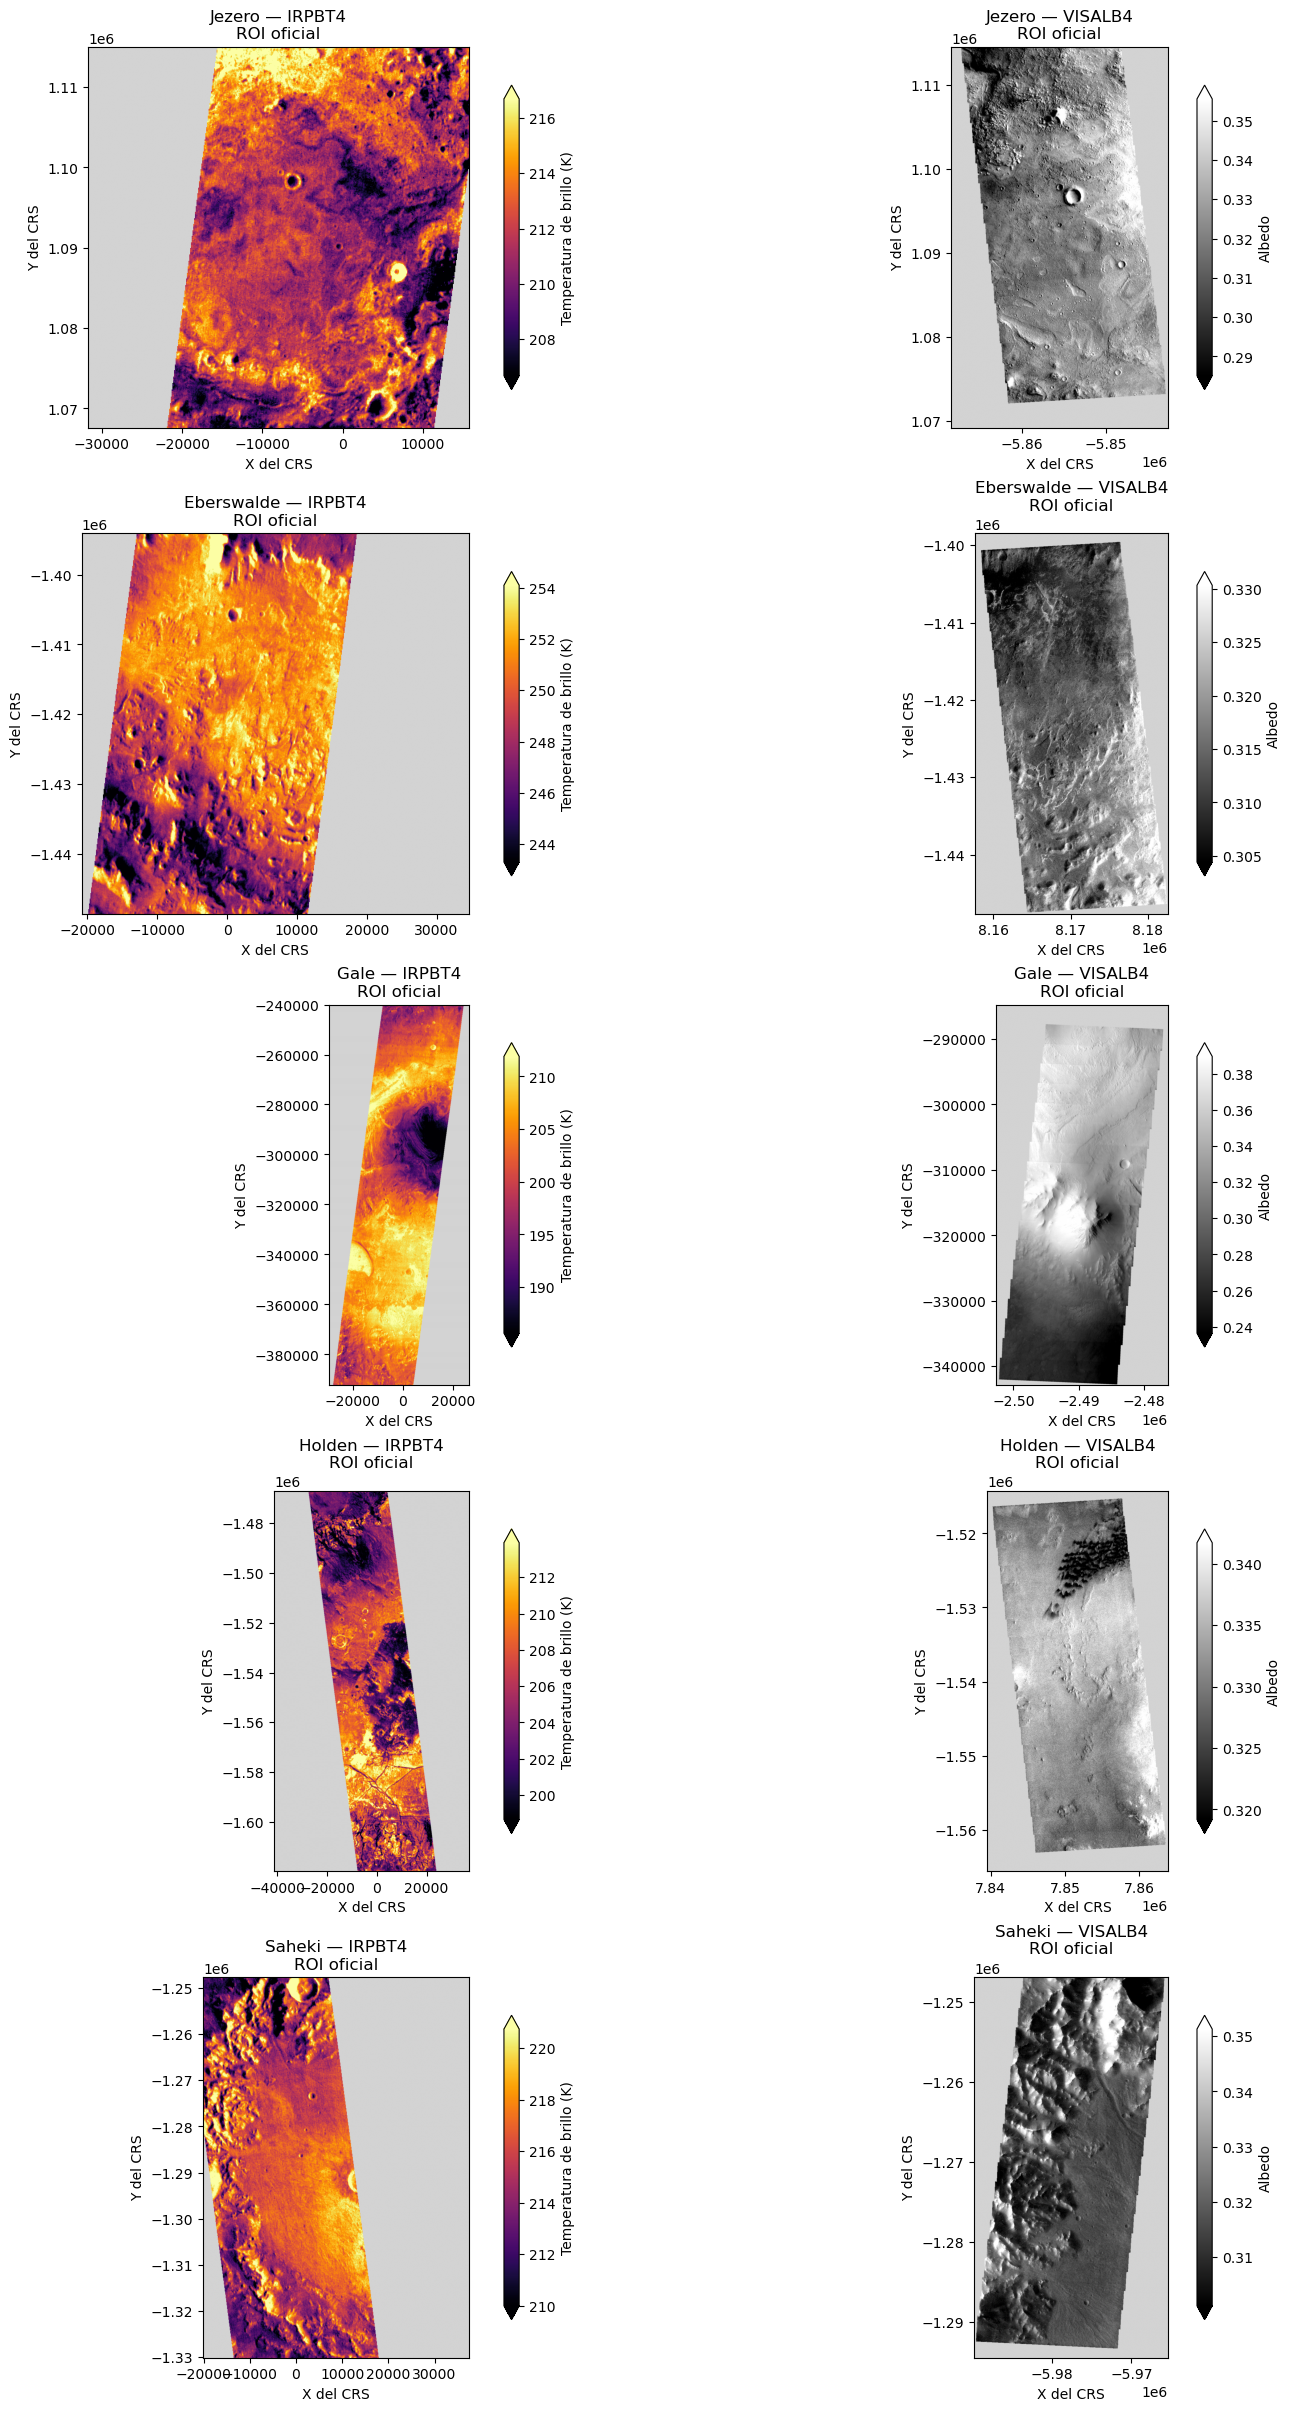

In [15]:
sites_order = ["jezero", "eberswalde", "gale", "holden", "saheki"]
products_order = ["IRPBT4", "VISALB4"]

fig, axes = plt.subplots(
    len(sites_order),
    len(products_order),
    figsize=(14, 24),
    constrained_layout=True,
)

for row, site in enumerate(sites_order):
    for col, product_item in enumerate(products_order):
        ax = axes[row, col]
        item = roi_images.get((site, product_item))

        if item is None:
            ax.set_title(f"{site} — {product_item}\nNo coverage")
            ax.axis("off")
            continue

        data = item["data"]
        bounds = item["bounds"]
        values = data.compressed()

        vmin, vmax = np.percentile(values, [2, 98])

        cmap_name = "inferno" if product_item == "IRPBT4" else "gray"
        cmap = plt.colormaps[cmap_name].copy()
        cmap.set_bad("lightgray")

        image = ax.imshow(
            data,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            extent=[bounds[0], bounds[2], bounds[1], bounds[3]],
            origin="upper",
        )

        label = "Brightness temperature (K)" if product_item == "IRPBT4" else "Albedo"

        ax.set_title(f"{site.capitalize()} — {product_item}\nROI oficial")
        ax.set_xlabel("CRS X")
        ax.set_ylabel("CRS Y")

        colorbar = fig.colorbar(image, ax=ax, shrink=0.80, extend="both")
        colorbar.set_label(label)

plt.show()

## 8. Integration and Validation of the Five-Crater Dataset


### 8.1 Common Analysis Resolution, Topographic Features, and Export to `mars_profiles_5_craters.csv`


In [16]:
import math

import numpy as np
import pandas as pd
import rasterio

from rasterio.enums import Resampling
from rasterio.windows import Window, from_bounds
from rasterio.windows import WindowError
from scipy.ndimage import uniform_filter


# ============================================================
# 1. COMMON RESOLUTION: NEVER ADD DETAIL ARTIFICIALLY
# ============================================================

native_resolutions = []

for site, dem_path in DEM_PATHS.items():
    with rasterio.open(dem_path) as src:
        native_resolution = max(src.res)
        native_resolutions.append({
            "site": site,
            "native_resolution_m": native_resolution,
            "file_entry": dem_path.name,
        })

native_resolutions = pd.DataFrame(native_resolutions)

# Use the coarsest resolution among the available DEMs.
ANALYSIS_RESOLUTION_M = float(
    math.ceil(native_resolutions["native_resolution_m"].max())
)

ROUGHNESS_WINDOW_PX = 5
ROUGHNESS_WINDOW_M = ROUGHNESS_WINDOW_PX * ANALYSIS_RESOLUTION_M

print("=== RESOLUCIONES NATIVAS ===")
display(native_resolutions)

print(
    f"\nCommon analysis resolution: {ANALYSIS_RESOLUTION_M:.0f} m"
    f"\nRoughness window: {ROUGHNESS_WINDOW_M:.0f} m "
    f"({ROUGHNESS_WINDOW_PX} × {ROUGHNESS_WINDOW_PX} pixels)"
)


# ============================================================
# 2. DEM FEATURE FUNCTIONS
# ============================================================

def read_dem_roi_common_resolution(dem_path, geographic_bounds):
    """Clips the DEM to the ROI and downsamples it to the common resolution."""
    with rasterio.open(dem_path) as src:
        left, bottom, right, top = mars_bounds_to_raster_bounds(
            src,
            geographic_bounds,
        )

        requested_window = from_bounds(
            left,
            bottom,
            right,
            top,
            transform=src.transform,
        ).round_offsets().round_lengths()

        full_window = Window(0, 0, src.width, src.height)

        try:
            crop_window = requested_window.intersection(full_window)
        except WindowError:
            raise ValueError(f"ROI with no intersection: {dem_path}")

        if crop_window.width <= 0 or crop_window.height <= 0:
            raise ValueError(f"ROI with no pixels: {dem_path}")

        source_res_x, source_res_y = src.res

        out_width = max(
            2,
            int(round(
                crop_window.width
                * source_res_x
                / ANALYSIS_RESOLUTION_M
            )),
        )

        out_height = max(
            2,
            int(round(
                crop_window.height
                * source_res_y
                / ANALYSIS_RESOLUTION_M
            )),
        )

        dem = src.read(
            1,
            window=crop_window,
            out_shape=(out_height, out_width),
            resampling=Resampling.average,
            masked=True,
        ).astype(np.float64)

        dem_values = np.asarray(dem.filled(np.nan))
        dem_values[~np.isfinite(dem_values)] = np.nan

        effective_res_x = crop_window.width * source_res_x / out_width
        effective_res_y = crop_window.height * source_res_y / out_height

        requested_pixels = requested_window.width * requested_window.height
        valid_coverage_pct = (
            100 * np.isfinite(dem_values).sum() / requested_pixels
        )

        return dem_values, effective_res_x, effective_res_y, valid_coverage_pct


def local_roughness(dem, window_pixels=5, min_valid_fraction=0.80):
    """sqrt(E[z²] − E[z]²), ignorando NoData."""
    valid = np.isfinite(dem)
    filled = np.where(valid, dem, 0.0)
    area = window_pixels ** 2

    count = (
        uniform_filter(
            valid.astype(float),
            size=window_pixels,
            mode="constant",
            cval=0,
        )
        * area
    )

    sum_z = (
        uniform_filter(
            filled,
            size=window_pixels,
            mode="constant",
            cval=0,
        )
        * area
    )

    sum_z2 = (
        uniform_filter(
            filled ** 2,
            size=window_pixels,
            mode="constant",
            cval=0,
        )
        * area
    )

    with np.errstate(divide="ignore", invalid="ignore"):
        mean_z = sum_z / count
        mean_z2 = sum_z2 / count
        roughness = np.sqrt(np.maximum(mean_z2 - mean_z ** 2, 0))

    roughness[count < min_valid_fraction * area] = np.nan

    return roughness


def dem_features_for_site(site, dem_path, bounds):
    """Computes the topographic profile of a crater."""
    dem, res_x, res_y, coverage = read_dem_roi_common_resolution(
        dem_path,
        bounds,
    )

    elevation = dem[np.isfinite(dem)]

    if elevation.size == 0:
        raise ValueError(f"{site}: no valid elevations.")

    dz_dy, dz_dx = np.gradient(dem, res_y, res_x)

    slope = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))
    slope[~np.isfinite(dem)] = np.nan

    roughness = local_roughness(
        dem,
        window_pixels=ROUGHNESS_WINDOW_PX,
    )

    valid_slope = slope[np.isfinite(slope)]
    valid_roughness = roughness[np.isfinite(roughness)]

    return {
        "site": site,
        "dem_file": dem_path.name,
        "dem_analysis_resolution_m": np.mean([res_x, res_y]),
        "dem_roughness_window_m": ROUGHNESS_WINDOW_M,
        "dem_roi_coverage_pct": coverage,

        "elev_min_m": np.min(elevation),
        "elev_p02_m": np.percentile(elevation, 2),
        "elev_p50_m": np.percentile(elevation, 50),
        "elev_mean_m": np.mean(elevation),
        "elev_p98_m": np.percentile(elevation, 98),
        "elev_max_m": np.max(elevation),
        "elev_std_m": np.std(elevation),
        "relief_m": np.max(elevation) - np.min(elevation),

        "slope_p50": np.percentile(valid_slope, 50),
        "slope_p95": np.percentile(valid_slope, 95),

        "rough_p50": np.percentile(valid_roughness, 50),
        "rough_p95": np.percentile(valid_roughness, 95),
    }


# ============================================================
# 3. DEM RECOMPUTATION: FIVE CRATERS
# ============================================================

dem_rows = []

for site in SITES:
    print(f"Processing DEM of {site}...")

    dem_rows.append(
        dem_features_for_site(
            site=site,
            dem_path=DEM_PATHS[site],
            bounds=SITES[site],
        )
    )

dem_features_5 = pd.DataFrame(dem_rows)

print("\n=== RECOMPUTED TOPOGRAPHIC FEATURES ===")
display(dem_features_5.round(4))


# ============================================================
# 4. DEM + THEMIS JOIN AND FINAL CSV
# ============================================================

mars_profile_final_5 = dem_features_5.merge(
    mars_themis_features_5,
    on="site",
    how="left",
    validate="one_to_one",
)

principal_columns = [
    "site",
    "elev_std_m",
    "slope_p50",
    "slope_p95",
    "rough_p50",
    "rough_p95",
    "ir_temp_p10_k",
    "ir_temp_p50_k",
    "ir_temp_p90_k",
    "ir_temp_std_k",
    "vis_albedo_p50",
    "vis_albedo_std",
    "dem_roi_coverage_pct",
    "ir_temp_roi_coverage_pct",
    "vis_albedo_roi_coverage_pct",
]

principal_columns = [
    column for column in principal_columns
    if column in mars_profile_final_5.columns
]

other_columns = [
    column for column in mars_profile_final_5.columns
    if column not in principal_columns
]

mars_profile_final_5 = mars_profile_final_5[
    principal_columns + other_columns
]

OUTPUT_CSV_FINAL = "mars_profiles_5_craters.csv"

mars_profile_final_5.to_csv(
    OUTPUT_CSV_FINAL,
    index=False,
)

print(f"\nFinal CSV created: {OUTPUT_CSV_FINAL}")
print(
    f"Rows: {len(mars_profile_final_5)} | "
    f"Columns: {len(mars_profile_final_5.columns)}"
)

display(mars_profile_final_5.round(4))

=== RESOLUCIONES NATIVAS ===


,site,native_resolution_m,file_entry
0,jezero,20.0,M20_JezeroCrater_CTXDEM_20m.tif
1,eberswalde,50.0,eberswalde_dtm.tif
2,gale,50.0,gale_dtm.tif
3,holden,125.0,h0511_0000_dt4.img
4,saheki,125.0,h6491_0000_dt4.img



Common analysis resolution: 125 m
Roughness window: 625 m (5 × 5 pixels)
Processing DEM of jezero...
Processing DEM of eberswalde...
Processing DEM of gale...
Processing DEM of holden...
Processing DEM of saheki...

=== RECOMPUTED TOPOGRAPHIC FEATURES ===


,site,dem_file,dem_analysis_resolution_m,dem_roughness_window_m,dem_roi_coverage_pct,elev_min_m,elev_p02_m,elev_p50_m,elev_mean_m,elev_p98_m,elev_max_m,elev_std_m,relief_m,slope_p50,slope_p95,rough_p50,rough_p95
0,jezero,M20_JezeroCrater_CTXDEM_20m.tif,125.0197,625.0,2.5592,-2918.6904,-2684.0231,-2465.6705,-2390.5308,-1738.0962,-1243.8413,256.3478,1674.8491,2.5255,14.8432,7.6130,43.9187
1,eberswalde,eberswalde_dtm.tif,125.0853,625.0,15.9782,-1593.0000,-1519.0000,-1113.0000,-1013.3087,-72.0000,303.0000,403.5350,1896.0000,3.5502,13.3600,10.7737,40.8320
2,gale,gale_dtm.tif,125.0109,625.0,15.9972,-4684.0000,-4473.0000,-2455.0000,-2394.3269,226.0000,1026.0000,1281.5370,5710.0000,6.0077,20.7530,18.6546,64.9772
3,holden,h0511_0000_dt4.img,125.0000,625.0,97.9951,-7003.0000,-6364.0000,-5674.0000,-5307.6231,-2925.0000,-2298.0000,966.0707,4705.0000,3.7256,15.2069,11.6000,47.4519
4,saheki,h6491_0000_dt4.img,125.0000,625.0,75.4663,-5439.0000,-5144.0000,-4274.0000,-4047.4998,-2187.0000,-1485.0000,865.6290,3954.0000,5.5260,18.5625,17.0099,58.0898



Final CSV created: mars_profiles_5_craters.csv
Rows: 5 | Columns: 37


,site,elev_std_m,slope_p50,slope_p95,rough_p50,rough_p95,ir_temp_p10_k,ir_temp_p50_k,ir_temp_p90_k,ir_temp_std_k,...,ir_temp_resolution_m,ir_temp_scene_intersection_pct,ir_temp_pdsid,vis_albedo_p10,vis_albedo_p90,vis_albedo_mean,vis_albedo_n_pixels,vis_albedo_resolution_m,vis_albedo_scene_intersection_pct,vis_albedo_pdsid
0,jezero,256.3478,2.5255,14.8432,7.6130,43.9187,208.690994,211.545807,214.437393,2.3086,...,100.0,100.0000,ia4985002pbt,0.3035,0.3404,0.3222,615061,36.0,51.4550,va4742007alb
1,eberswalde,403.5350,3.5502,13.3600,10.7737,40.8320,245.995605,250.438705,252.506302,2.6968,...,100.0,100.0000,i91575002pbt,0.3086,0.3245,0.3156,657753,36.0,39.7920,v99480016alb
2,gale,1281.5370,6.0077,20.7530,18.6546,64.9772,193.734406,204.095200,209.980606,6.4347,...,100.0,37.8890,i89635001pbt,0.2601,0.3739,0.3212,3016927,18.0,6.8759,v01132001alb
3,holden,966.0707,3.7256,15.2069,11.6000,47.4519,200.593399,205.846603,210.767593,3.8937,...,100.0,50.6149,ia0391010pbt,0.3271,0.3383,0.3327,637381,36.0,5.3252,va7142006alb
4,saheki,865.6290,5.5260,18.5625,17.0099,58.0898,212.408707,216.035202,218.697800,2.5154,...,100.0,69.7816,i90292005pbt,0.3063,0.3313,0.3176,632532,36.0,16.9607,va0868003alb


### 8.2 Reviewing Missing Values, Coverage, and Profile Comparisons


=== FINAL CSV VALIDATION ===
Dimensions: 5 craters × 37 columns
Craters: ['jezero', 'eberswalde', 'gale', 'holden', 'saheki']

=== FEATURES PRINCIPALES ===


,site,elev_std_m,slope_p50,slope_p95,rough_p50,rough_p95,ir_temp_p10_k,ir_temp_p50_k,ir_temp_p90_k,ir_temp_std_k,vis_albedo_p50,vis_albedo_std
0,jezero,256.3478,2.5255,14.8432,7.6130,43.9187,208.690994,211.545807,214.437393,2.3086,0.3226,0.0157
1,eberswalde,403.5350,3.5502,13.3600,10.7737,40.8320,245.995605,250.438705,252.506302,2.6968,0.3147,0.0062
2,gale,1281.5370,6.0077,20.7530,18.6546,64.9772,193.734406,204.095200,209.980606,6.4347,0.3315,0.0435
3,holden,966.0707,3.7256,15.2069,11.6000,47.4519,200.593399,205.846603,210.767593,3.8937,0.3330,0.0050
4,saheki,865.6290,5.5260,18.5625,17.0099,58.0898,212.408707,216.035202,218.697800,2.5154,0.3161,0.0109



=== COVERAGE PER CRATER ===


,site,dem_roi_coverage_pct,ir_temp_roi_coverage_pct,vis_albedo_roi_coverage_pct
0,jezero,2.56,69.56,34.98
1,eberswalde,15.98,56.91,27.55
2,gale,16.00,21.88,4.39
3,holden,98.00,20.58,3.51
4,saheki,75.47,37.14,12.00



=== VALORES FALTANTES ===
✓ No missing values in features or coverage.

=== STATISTICAL SUMMARY ===


,0,1,2,3,4
elev_std_m,256.3478,403.5350,1281.5370,966.0707,865.6290
slope_p50,2.5255,3.5502,6.0077,3.7256,5.5260
slope_p95,14.8432,13.3600,20.7530,15.2069,18.5625
rough_p50,7.6130,10.7737,18.6546,11.6000,17.0099
rough_p95,43.9187,40.8320,64.9772,47.4519,58.0898
ir_temp_p10_k,208.6910,245.9957,193.7345,200.5934,212.4087
ir_temp_p50_k,211.5458,250.4387,204.0952,205.8466,216.0352
ir_temp_p90_k,214.4374,252.5063,209.9806,210.7675,218.6978
ir_temp_std_k,2.3086,2.6968,6.4347,3.8937,2.5154
vis_albedo_p50,0.3226,0.3147,0.3315,0.3330,0.3161


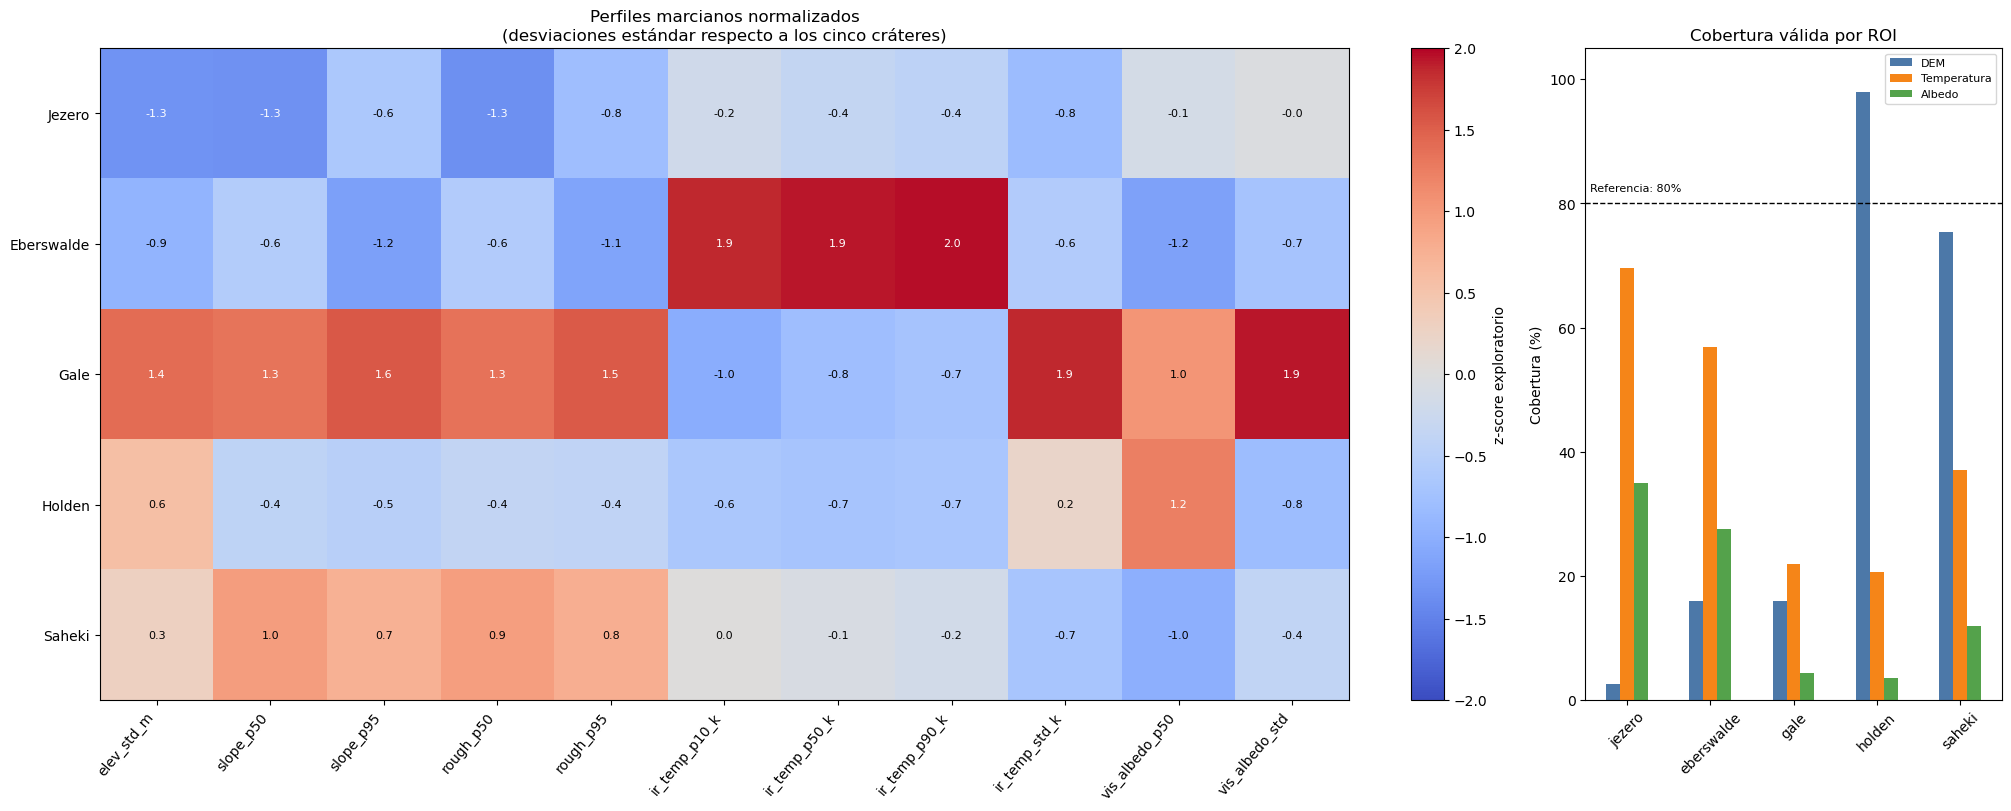

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


df_mars = mars_profile_final_5.copy()

features_core = [
    "elev_std_m",
    "slope_p50",
    "slope_p95",
    "rough_p50",
    "rough_p95",
    "ir_temp_p10_k",
    "ir_temp_p50_k",
    "ir_temp_p90_k",
    "ir_temp_std_k",
    "vis_albedo_p50",
    "vis_albedo_std",
]

coverage_cols = [
    "dem_roi_coverage_pct",
    "ir_temp_roi_coverage_pct",
    "vis_albedo_roi_coverage_pct",
]

features_core = [
    col for col in features_core
    if col in df_mars.columns
]

coverage_cols = [
    col for col in coverage_cols
    if col in df_mars.columns
]

print("=== FINAL CSV VALIDATION ===")
print(f"Dimensions: {df_mars.shape[0]} craters × {df_mars.shape[1]} columns")
print(f"Craters: {df_mars['site'].tolist()}")

print("\n=== FEATURES PRINCIPALES ===")
display(df_mars[["site"] + features_core].round(4))

print("\n=== COVERAGE PER CRATER ===")
display(df_mars[["site"] + coverage_cols].round(2))

print("\n=== VALORES FALTANTES ===")
nulls = df_mars[features_core + coverage_cols].isna().sum()

if nulls.sum() == 0:
    print("✓ No missing values in features or coverage.")
else:
    display(nulls[nulls > 0].to_frame("null_counts"))

print("\n=== STATISTICAL SUMMARY ===")
display(df_mars[features_core].T.round(4))


# ------------------------------------------------------------
# Heatmap of normalised profiles: exploratory comparison.
# Not used for the ranking yet.
# ------------------------------------------------------------

matrix = df_mars.set_index("site")[features_core].astype(float)

z_matrix = (
    matrix - matrix.mean(axis=0)
) / matrix.std(axis=0, ddof=0)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(20, 8),
    gridspec_kw={"width_ratios": [3, 1]},
    constrained_layout=True,
)

heatmap = axes[0].imshow(
    z_matrix.values,
    cmap="coolwarm",
    vmin=-2,
    vmax=2,
    aspect="auto",
)

axes[0].set_title(
    "Normalised Martian profiles\n"
    "(standard deviations relative to the five craters)"
)
axes[0].set_yticks(range(len(z_matrix.index)))
axes[0].set_yticklabels(z_matrix.index.str.capitalize())
axes[0].set_xticks(range(len(z_matrix.columns)))
axes[0].set_xticklabels(z_matrix.columns, rotation=50, ha="right")

for row in range(z_matrix.shape[0]):
    for col in range(z_matrix.shape[1]):
        value = z_matrix.iloc[row, col]

        axes[0].text(
            col,
            row,
            f"{value:.1f}",
            ha="center",
            va="center",
            fontsize=8,
            color="black" if abs(value) < 1.2 else "white",
        )

colorbar = fig.colorbar(heatmap, ax=axes[0])
colorbar.set_label("z-score exploratorio")


# ------------------------------------------------------------
# Data coverage
# ------------------------------------------------------------

coverage_values = df_mars.set_index("site")[coverage_cols]

coverage_values.plot(
    kind="bar",
    ax=axes[1],
    color=["#4C78A8", "#F58518", "#54A24B"][:len(coverage_cols)],
)

axes[1].set_title("Valid coverage per ROI")
axes[1].set_xlabel("")
axes[1].set_ylabel("Coverage (%)")
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(
    ["DEM", "Temperatura", "Albedo"][:len(coverage_cols)],
    fontsize=8,
)

axes[1].axhline(80, color="black", linestyle="--", linewidth=1)
axes[1].text(
    -0.45,
    82,
    "Referencia: 80%",
    fontsize=8,
)

plt.show()

## 9. Identifying Additional Areas of Interest


### 9.1 Defining Martian ROIs and Search Areas


In [18]:
import pandas as pd

# Planetocentric coordinates, east-positive longitude: 0–360°.
# The PIA sites have a local ROI with a context buffer.
# Large regions are recorded as "macro" and split later.

mars_new_zones = pd.DataFrame(
    [
        {
            "site": "pia18625_arabia_lake",
            "display_name": "PIA18625 — sedimentos lacustres",
            "zone_type": "roi_local",
            "minlat": 35.88,
            "maxlat": 36.03,
            "westernlon": 351.73,
            "easternlon": 351.91,
            "mid_lat": 35.952,
            "mid_lon": 351.821,
            "analysis_scale": "local (~9 km)",
            "location_source": "HiRISE ESP_035843_2165 / PIA18625",
            "note": (
                "HiRISE image with stereo pair. "
                "Search HiRISE DTMs first; use HRSC as fallback."
            ),
            "suitable_for_dtm_search": True,
            "suitable_for_direct_similarity": True,
        },
        {
            "site": "pia04488_arabia_layers",
            "display_name": "PIA04488 — capas sedimentarias",
            "zone_type": "roi_local",
            "minlat": 7.94,
            "maxlat": 8.06,
            "westernlon": 352.94,
            "easternlon": 353.06,
            "mid_lat": 8.00,
            "mid_lon": 353.00,
            "analysis_scale": "local (~7 km)",
            "location_source": "MOC / PIA04488",
            "note": (
                "MOC image of sedimentary layers. "
                "Search for an available HRSC or HiRISE DTM in the area."
            ),
            "suitable_for_dtm_search": True,
            "suitable_for_direct_similarity": True,
        },
        {
            "site": "olympus_mons",
            "display_name": "Monte Olimpo",
            "zone_type": "macro_region",
            "minlat": 13.55,
            "maxlat": 23.55,
            "westernlon": 220.70,
            "easternlon": 231.00,
            "mid_lat": 18.40,
            "mid_lon": 226.00,
            "analysis_scale": "regional (~648 km)",
            "location_source": "USGS Gazetteer of Planetary Nomenclature",
            "note": (
                "Will be evaluated as a whole volcanic edifice or split "
                "into caldera, flanks and basal scarp."
            ),
            "suitable_for_dtm_search": False,
            "suitable_for_direct_similarity": False,
        },
        {
            "site": "valles_marineris",
            "display_name": "Valles Marineris",
            "zone_type": "macro_region",
            "minlat": -19.09,
            "maxlat": -2.96,
            "westernlon": 267.30,
            "easternlon": 331.10,
            "mid_lat": -13.74,
            "mid_lon": 300.80,
            "analysis_scale": "macroregional (~3,769 km)",
            "location_source": "USGS Gazetteer of Planetary Nomenclature",
            "note": (
                "Will not be used as a single observation. It will be split into "
                "western, central and eastern subzones."
            ),
            "suitable_for_dtm_search": False,
            "suitable_for_direct_similarity": False,
        },
        {
            "site": "elysium_planitia",
            "display_name": "Elysium Planitia",
            "zone_type": "macro_region",
            "minlat": -4.94,
            "maxlat": 9.88,
            "westernlon": 130.00,
            "easternlon": 180.00,
            "mid_lat": 1.98,
            "mid_lon": 155.00,
            "analysis_scale": "macroregional (~3,000 km)",
            "location_source": "USGS Gazetteer of Planetary Nomenclature",
            "note": (
                "Large plain; representative subzones will be created "
                "before computing the similarity profile."
            ),
            "suitable_for_dtm_search": False,
            "suitable_for_direct_similarity": False,
        },
    ]
)

display(mars_new_zones)

# Only these two can go straight to the DTM/PDS search.
zones_dtm_immediate = mars_new_zones.query(
    "suitable_for_dtm_search == True"
).copy()

SITES_NEW = (
    zones_dtm_immediate
    .set_index("site")[["minlat", "maxlat", "westernlon", "easternlon"]]
    .to_dict(orient="index")
)

print("=== ZONES READY FOR DTM SEARCH ===")
display(zones_dtm_immediate[
    ["site", "display_name", "mid_lat", "mid_lon", "analysis_scale"]
])

print("\n=== DICTIONARY FOR PDS / ODE ===")
SITES_NEW

,site,display_name,zone_type,minlat,maxlat,westernlon,easternlon,mid_lat,mid_lon,analysis_scale,location_source,note,suitable_for_dtm_search,suitable_for_direct_similarity
0,pia18625_arabia_lake,PIA18625 — sedimentos lacustres,roi_local,35.88,36.03,351.73,351.91,35.952,351.821,local (~9 km),HiRISE ESP_035843_2165 / PIA18625,HiRISE image with stereo pair. Buscar p...,True,True
1,pia04488_arabia_layers,PIA04488 — capas sedimentarias,roi_local,7.94,8.06,352.94,353.06,8.000,353.000,local (~7 km),MOC / PIA04488,MOC image of sedimentary layers. Buscar DTM ...,True,True
2,olympus_mons,Monte Olimpo,macro_region,13.55,23.55,220.70,231.00,18.400,226.000,regional (~648 km),USGS Gazetteer of Planetary Nomenclature,Will be evaluated as a whole volcanic edifi...,False,False
3,valles_marineris,Valles Marineris,macro_region,-19.09,-2.96,267.30,331.10,-13.740,300.800,"macroregional (~3,769 km)",USGS Gazetteer of Planetary Nomenclature,Will not be used as a single observation. It...,False,False
4,elysium_planitia,Elysium Planitia,macro_region,-4.94,9.88,130.00,180.00,1.980,155.000,"macroregional (~3,000 km)",USGS Gazetteer of Planetary Nomenclature,Large plain; representative subzones will b...,False,False


=== ZONES READY FOR DTM SEARCH ===


,site,display_name,mid_lat,mid_lon,analysis_scale
0,pia18625_arabia_lake,PIA18625 — sedimentos lacustres,35.952,351.821,local (~9 km)
1,pia04488_arabia_layers,PIA04488 — capas sedimentarias,8.000,353.000,local (~7 km)



=== DICTIONARY FOR PDS / ODE ===


{'pia18625_arabia_lake': {'minlat': 35.88,
  'maxlat': 36.03,
  'westernlon': 351.73,
  'easternlon': 351.91},
 'pia04488_arabia_layers': {'minlat': 7.94,
  'maxlat': 8.06,
  'westernlon': 352.94,
  'easternlon': 353.06}}

### 9.2 Querying and Ranking DTM Candidates for PIA Regions


In [21]:
# ============================================================
# PDS/ODE DTM SEARCH AND RANKING FOR PIA18625 AND PIA04488
# Does not download files.
#
# Requires: SITES_NEW
# ============================================================

import numpy as np
import pandas as pd
import requests


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
ODE_URL = "https://oderest.rsl.wustl.edu/live2/"
RESULTS_PER_SOURCE = 100
TIMEOUT_SECONDS = 60

DTM_SOURCES = [
    {
        "dtm_source": "HiRISE_DTM",
        "ihid": "MRO",
        "iid": "HIRISE",
        "pt": "DTM",
        "source_priority": 1,
    },
    {
        "dtm_source": "HRSC_DTMRDR",
        "ihid": "MEX",
        "iid": "HRSC",
        "pt": "DTMRDR",
        "source_priority": 2,
    },
]

if "SITES_NEW" not in globals():
    raise NameError(
        "SITES_NEW does not exist. First run the cell "
        "that declares the PIA zones."
    )


# ------------------------------------------------------------
# 2. Analysis ROI and search ROI
# ------------------------------------------------------------
# The analysis ROI is the one used later to extract features.
SITES_ANALYSIS = {
    site: dict(bounds)
    for site, bounds in SITES_NEW.items()
}

# For PIA04488 ONLY the search space is widened.
# The final clip is still the small ROI from SITES_ANALYSIS.
SITES_DTM_SEARCH = {
    site: dict(bounds)
    for site, bounds in SITES_ANALYSIS.items()
}

SITES_DTM_SEARCH["pia04488_arabia_layers"] = {
    "minlat": 7.50,
    "maxlat": 8.50,
    "westernlon": 352.50,
    "easternlon": 353.50,
}


# ------------------------------------------------------------
# 3. Utilidades ODE
# ------------------------------------------------------------
def ode_request(params):
    """Queries ODE and returns the main results block."""
    response = requests.get(
        ODE_URL,
        params=params,
        timeout=TIMEOUT_SECONDS,
        headers={"Accept": "application/json"},
    )
    response.raise_for_status()

    payload = response.json()
    ode_results = payload.get("ODEResults", payload)

    if not isinstance(ode_results, dict):
        return {}

    status = str(ode_results.get("Status", "")).upper()

    if status and status != "SUCCESS":
        error = ode_results.get("Error", "No detail")
        raise RuntimeError(f"ODE answered {status}: {error}")

    return ode_results


def extract_products(ode_results):
    """
    Extracts products even when ODE answers with text
    because no candidates were found.
    """
    if not isinstance(ode_results, dict):
        return []

    products_block = ode_results.get("Products", {})

    if isinstance(products_block, str) or products_block is None:
        return []

    if isinstance(products_block, list):
        return [
            product
            for product in products_block
            if isinstance(product, dict)
        ]

    if not isinstance(products_block, dict):
        return []

    products = products_block.get("Product", [])

    if isinstance(products, dict):
        products = [products]

    if not isinstance(products, list):
        return []

    return [
        product
        for product in products
        if isinstance(product, dict)
    ]


def numeric_column(df, candidate_columns):
    """Takes the first existing column and converts it to numeric."""
    for column in candidate_columns:
        if column in df.columns:
            return pd.to_numeric(df[column], errors="coerce")

    return pd.Series(np.nan, index=df.index, dtype=float)


def circular_lon_distance(lon_a, lon_b):
    """Minimum distance between longitudes given in 0–360°."""
    if not np.isfinite(lon_a) or not np.isfinite(lon_b):
        return np.nan

    return abs((lon_a - lon_b + 180) % 360 - 180)


def longitude_inside_interval(lon, west, east):
    """Checks whether a longitude lies inside a 0–360° interval."""
    if not all(np.isfinite([lon, west, east])):
        return np.nan

    lon = lon % 360
    west = west % 360
    east = east % 360

    if west <= east:
        return west <= lon <= east

    # Case of an interval crossing 0°.
    return lon >= west or lon <= east


def product_covers_roi(row):
    """
    Checks whether the ODE-reported footprint covers the analysis ROI.
    Returns NaN if coverage metadata are missing.
    """
    needed = [
        "product_min_lat",
        "product_max_lat",
        "product_west_lon",
        "product_east_lon",
        "roi_minlat",
        "roi_maxlat",
        "roi_westernlon",
        "roi_easternlon",
    ]

    if not all(np.isfinite(row[column]) for column in needed):
        return np.nan

    lat_ok = (
        row["product_min_lat"] <= row["roi_minlat"]
        and row["product_max_lat"] >= row["roi_maxlat"]
    )

    west_ok = longitude_inside_interval(
        row["roi_westernlon"],
        row["product_west_lon"],
        row["product_east_lon"],
    )

    east_ok = longitude_inside_interval(
        row["roi_easternlon"],
        row["product_west_lon"],
        row["product_east_lon"],
    )

    return bool(lat_ok and west_ok and east_ok)


def query_dtm_candidates(site_name, search_bounds, source):
    """
    Searches DTMs in ODE.
    results='pm' requests product identifier and metadata.
    """
    params = {
        "target": "mars",
        "query": "product",
        "ihid": source["ihid"],
        "iid": source["iid"],
        "pt": source["pt"],
        "minlat": search_bounds["minlat"],
        "maxlat": search_bounds["maxlat"],
        "westernlon": search_bounds["westernlon"],
        "easternlon": search_bounds["easternlon"],
        "loc": "f",
        "results": "pm",
        "output": "JSON",
        "offset": 0,
        "limit": RESULTS_PER_SOURCE,
    }

    ode_results = ode_request(params)
    products = extract_products(ode_results)

    if not products:
        return pd.DataFrame()

    result = pd.json_normalize(products)

    result["site"] = site_name
    result["dtm_source"] = source["dtm_source"]
    result["source_priority"] = source["source_priority"]

    # HRSC_DTMRDR groups several rasters derived from the same scene.
    # Only *_DT4.IMG is the elevation DTM.
    if source["dtm_source"] == "HRSC_DTMRDR":
        if "pdsid" not in result.columns:
            return pd.DataFrame()

        mask_dt4 = (
            result["pdsid"]
            .astype(str)
            .str.upper()
            .str.endswith("_DT4.IMG")
        )

        result = result.loc[mask_dt4].copy()

    return result


# ------------------------------------------------------------
# 4. Query both sources for each PIA
# ------------------------------------------------------------
frames = []

for site_name, search_bounds in SITES_DTM_SEARCH.items():
    print(f"\n=== {site_name.upper()} ===")

    for source in DTM_SOURCES:
        try:
            result = query_dtm_candidates(
                site_name=site_name,
                search_bounds=search_bounds,
                source=source,
            )

            print(
                f"{source['dtm_source']}: "
                f"{len(result):,} candidato(s)"
            )

            if not result.empty:
                frames.append(result)

        except Exception as error:
            print(f"{source['dtm_source']}: error -> {error}")


if not frames:
    raise RuntimeError(
        "ODE returned no DTM candidates. "
        "Share this output to adjust the strategy."
    )

dtm_candidates_pia = pd.concat(frames, ignore_index=True)


# ------------------------------------------------------------
# 5. Normalise metadata and evaluate coverage
# ------------------------------------------------------------
dtm_candidates_pia["map_resolution_m"] = numeric_column(
    dtm_candidates_pia,
    ["Map_resolution", "Map_Resolution", "map_resolution"],
)

dtm_candidates_pia["center_lat"] = numeric_column(
    dtm_candidates_pia,
    ["Center_latitude", "Center_Latitude", "center_latitude"],
)

dtm_candidates_pia["center_lon"] = numeric_column(
    dtm_candidates_pia,
    ["Center_longitude", "Center_Longitude", "center_longitude"],
)

dtm_candidates_pia["product_min_lat"] = numeric_column(
    dtm_candidates_pia,
    ["Minimum_latitude", "Minimum_Latitude"],
)

dtm_candidates_pia["product_max_lat"] = numeric_column(
    dtm_candidates_pia,
    ["Maximum_latitude", "Maximum_Latitude"],
)

dtm_candidates_pia["product_west_lon"] = numeric_column(
    dtm_candidates_pia,
    ["Westernmost_longitude", "Westernmost_Longitude"],
)

dtm_candidates_pia["product_east_lon"] = numeric_column(
    dtm_candidates_pia,
    ["Easternmost_longitude", "Easternmost_Longitude"],
)

# Add the analysis ROI bounds, not the widened search bounds.
for column in ["minlat", "maxlat", "westernlon", "easternlon"]:
    dtm_candidates_pia[f"roi_{column}"] = dtm_candidates_pia["site"].map(
        {
            site: values[column]
            for site, values in SITES_ANALYSIS.items()
        }
    )

dtm_candidates_pia["roi_center_lat"] = (
    dtm_candidates_pia["roi_minlat"]
    + dtm_candidates_pia["roi_maxlat"]
) / 2

dtm_candidates_pia["roi_center_lon"] = (
    dtm_candidates_pia["roi_westernlon"]
    + dtm_candidates_pia["roi_easternlon"]
) / 2

dtm_candidates_pia["distance_to_roi_center_deg"] = dtm_candidates_pia.apply(
    lambda row: np.sqrt(
        (row["center_lat"] - row["roi_center_lat"]) ** 2
        + circular_lon_distance(
            row["center_lon"],
            row["roi_center_lon"],
        ) ** 2
    )
    if np.isfinite(row["center_lat"]) and np.isfinite(row["center_lon"])
    else np.nan,
    axis=1,
)

dtm_candidates_pia["covers_analysis_roi"] = dtm_candidates_pia.apply(
    product_covers_roi,
    axis=1,
)

# Preference order:
# 1) fully covers the ROI;
# 2) highest-priority source;
# 3) best resolution;
# 4) proximity to the ROI center.
dtm_candidates_pia["coverage_order"] = (
    dtm_candidates_pia["covers_analysis_roi"]
    .map({True: 0, False: 1})
    .fillna(2)
)

dtm_candidates_pia = dtm_candidates_pia.sort_values(
    by=[
        "site",
        "coverage_order",
        "source_priority",
        "map_resolution_m",
        "distance_to_roi_center_deg",
    ],
    na_position="last",
).reset_index(drop=True)

dtm_candidates_pia["rank_in_site"] = (
    dtm_candidates_pia
    .groupby("site")
    .cumcount()
    .add(1)
)


# ------------------------------------------------------------
# 6. Show and keep the candidates
# ------------------------------------------------------------
COLUMNS_TO_SHOW = [
    "site",
    "rank_in_site",
    "dtm_source",
    "pdsid",
    "map_resolution_m",
    "center_lat",
    "center_lon",
    "covers_analysis_roi",
    "distance_to_roi_center_deg",
    "product_min_lat",
    "product_max_lat",
    "product_west_lon",
    "product_east_lon",
    "Product_files.Product_file",
]

COLUMNS_TO_SHOW = [
    column
    for column in COLUMNS_TO_SHOW
    if column in dtm_candidates_pia.columns
]

print("\n=== CANDIDATOS DTM ORDENADOS ===")
display(dtm_candidates_pia[COLUMNS_TO_SHOW])

print("\n=== BEST PRELIMINARY CANDIDATE PER ROI ===")
display(
    dtm_candidates_pia
    .groupby("site", as_index=False)
    .head(1)[COLUMNS_TO_SHOW]
)

print("\n=== RAW COLUMNS RETURNED BY ODE ===")
print(dtm_candidates_pia.columns.tolist())


=== PIA18625_LAGO_ARABIA ===
HiRISE_DTM: 0 candidato(s)
HRSC_DTMRDR: 2 candidato(s)

=== PIA04488_CAPAS_ARABIA ===
HiRISE_DTM: 1 candidato(s)
HRSC_DTMRDR: 0 candidato(s)

=== CANDIDATOS DTM ORDENADOS ===


,site,rank_in_site,dtm_source,pdsid,map_resolution_m,center_lat,center_lon,covers_analysis_roi,distance_to_roi_center_deg,product_min_lat,product_max_lat,product_west_lon,product_east_lon
0,pia04488_arabia_layers,1,HiRISE_DTM,DTEEC_002878_1880_002733_1880_U01,58599.870713,8.1148,353.1760,False,0.210131,7.9944,8.2406,353.120,353.232
1,pia18625_arabia_lake,1,HRSC_DTMRDR,H2872_0000_DT4.IMG,263.428357,35.5211,350.2306,True,1.647562,30.2920,40.7330,347.408,353.613
2,pia18625_arabia_lake,2,HRSC_DTMRDR,H1205_0000_DT4.IMG,790.285072,38.7764,351.6069,True,2.829436,33.4267,44.1216,350.600,352.474



=== BEST PRELIMINARY CANDIDATE PER ROI ===


,site,rank_in_site,dtm_source,pdsid,map_resolution_m,center_lat,center_lon,covers_analysis_roi,distance_to_roi_center_deg,product_min_lat,product_max_lat,product_west_lon,product_east_lon
0,pia04488_arabia_layers,1,HiRISE_DTM,DTEEC_002878_1880_002733_1880_U01,58599.870713,8.1148,353.1760,False,0.210131,7.9944,8.2406,353.120,353.232
1,pia18625_arabia_lake,1,HRSC_DTMRDR,H2872_0000_DT4.IMG,263.428357,35.5211,350.2306,True,1.647562,30.2920,40.7330,347.408,353.613



=== RAW COLUMNS RETURNED BY ODE ===
['BB_georeferenced', 'Center_georeferenced', 'Center_latitude', 'Center_longitude', 'Data_Set_Id', 'Easternmost_longitude', 'External_url', 'FilesURL', 'Footprint_C0_geometry', 'Footprint_geometry', 'Footprint_GL_geometry', 'Footprint_NP_geometry', 'Footprint_souce', 'Footprint_SP_geometry', 'Footprints_cross_meridian', 'ihid', 'iid', 'Label_product_type', 'LabelFileName', 'LabelURL', 'Map_resolution', 'Map_scale', 'Maximum_latitude', 'Minimum_latitude', 'Observation_time', 'pdsid', 'PDSVolume_Id', 'Pole_state', 'Product_creation_time', 'ProductURL', 'pt', 'RelativePathtoVol', 'SpaceCraft_clock_start_count', 'SpaceCraft_clock_stop_count', 'Start_orbit_number', 'Stop_orbit_number', 'Target_name', 'UTC_start_time', 'UTC_stop_time', 'Westernmost_longitude', 'ODE_notes.ODE_note', 'site', 'dtm_source', 'source_priority', 'Comment', 'Producer_id', 'Product_version_id', 'map_resolution_m', 'center_lat', 'center_lon', 'product_min_lat', 'product_max_lat', '

### 9.3 Searching for DTMs in Additional Martian Regions


In [23]:
# ============================================================
# LAST MARTIAN ZONES — ANALYSIS ROIs AND DTM SEARCH
#
# Requires these to exist in the notebook:
# - DTM_SOURCES
# - query_dtm_candidates()
# - SITES_ANALYSIS / SITES_DTM_SEARCH are not required
# ============================================================

import pandas as pd

# Planetocentric coordinates, east-positive longitude: 0–360°.
# Macro-regions are represented by one scientific subzone
# to avoid summarising thousands of kilometres as a single observation.

mars_final_zones = pd.DataFrame(
    [
        {
            "site": "pia04488_arabia_layers",
            "display_name": "PIA04488 — capas sedimentarias",
            "zone_type": "roi_local",
            "minlat": 7.94,
            "maxlat": 8.06,
            "westernlon": 352.94,
            "easternlon": 353.06,
            "target_source": "PIA04488 / MOC",
            "note": "Local ROI of sedimentary layers in Arabia Terra.",
        },
        {
            "site": "olympus_mons_caldera",
            "display_name": "Olympus Mons — caldera and summit",
            "zone_type": "representative_subzone",
            "minlat": 17.25,
            "maxlat": 20.00,
            "westernlon": 224.50,
            "easternlon": 227.50,
            "target_source": "USGS Olympus Mons",
            "note": "Central zone of the volcanic edifice, including the caldera.",
        },
        {
            "site": "elysium_planitia_central",
            "display_name": "Elysium Planitia — central zone",
            "zone_type": "representative_subzone",
            "minlat": 1.50,
            "maxlat": 4.50,
            "westernlon": 153.00,
            "easternlon": 156.00,
            "target_source": "USGS Elysium Planitia",
            "note": "Central sample of a volcanic plain.",
        },
        {
            "site": "valles_marineris_melas",
            "display_name": "Valles Marineris — Melas Chasma",
            "zone_type": "representative_subzone",
            "minlat": -15.50,
            "maxlat": -12.00,
            "westernlon": 294.00,
            "easternlon": 303.00,
            "target_source": "USGS Valles Marineris",
            "note": "Representative central segment of the canyon system.",
        },
    ]
)

display(mars_final_zones)

SITES_FINAL = (
    mars_final_zones
    .set_index("site")[["minlat", "maxlat", "westernlon", "easternlon"]]
    .to_dict(orient="index")
)


# ------------------------------------------------------------
# Search HiRISE and HRSC DTMs for the four zones
# ------------------------------------------------------------
frames = []

for site_name, bounds in SITES_FINAL.items():
    print(f"\n=== {site_name.upper()} ===")

    for source in DTM_SOURCES:
        try:
            result = query_dtm_candidates(
                site_name=site_name,
                search_bounds=bounds,
                source=source,
            )

            print(
                f"{source['dtm_source']}: "
                f"{len(result):,} candidato(s)"
            )

            if not result.empty:
                frames.append(result)

        except Exception as error:
            print(f"{source['dtm_source']}: error -> {error}")


if not frames:
    raise RuntimeError("No DTMs found for the new zones.")

dtm_candidates_final = pd.concat(frames, ignore_index=True)


# ------------------------------------------------------------
# Normalise ODE resolution and sort candidates
# ------------------------------------------------------------
MARS_RADIUS_M = 3_396_190.0
MARS_METERS_PER_DEGREE = 2 * np.pi * MARS_RADIUS_M / 360

dtm_candidates_final["map_resolution_px_per_degree"] = numeric_column(
    dtm_candidates_final,
    ["Map_resolution", "Map_Resolution", "map_resolution"],
)

dtm_candidates_final["pixel_size_m_approx"] = (
    MARS_METERS_PER_DEGREE
    / dtm_candidates_final["map_resolution_px_per_degree"]
)

dtm_candidates_final = dtm_candidates_final.sort_values(
    by=[
        "site",
        "source_priority",
        "pixel_size_m_approx",
    ],
    ascending=True,
    na_position="last",
).reset_index(drop=True)

dtm_candidates_final["rank_in_site"] = (
    dtm_candidates_final
    .groupby("site")
    .cumcount()
    .add(1)
)

COLUMNS_TO_SHOW = [
    "site",
    "rank_in_site",
    "dtm_source",
    "pdsid",
    "map_resolution_px_per_degree",
    "pixel_size_m_approx",
    "Center_latitude",
    "Center_longitude",
    "Minimum_latitude",
    "Maximum_latitude",
    "Westernmost_longitude",
    "Easternmost_longitude",
    "Product_files.Product_file",
]

COLUMNS_TO_SHOW = [
    column
    for column in COLUMNS_TO_SHOW
    if column in dtm_candidates_final.columns
]

print("\n=== DTM CANDIDATES FOR THE LAST ZONES ===")
display(dtm_candidates_final[COLUMNS_TO_SHOW].head(30))

print("\n=== BEST PRELIMINARY CANDIDATE PER ZONE ===")
display(
    dtm_candidates_final
    .groupby("site", as_index=False)
    .head(1)[COLUMNS_TO_SHOW]
)

,site,display_name,zone_type,minlat,maxlat,westernlon,easternlon,target_source,note
0,pia04488_arabia_layers,PIA04488 — capas sedimentarias,roi_local,7.94,8.06,352.94,353.06,PIA04488 / MOC,Local ROI of sedimentary layers in Arabia Terra.
1,olympus_mons_caldera,Olympus Mons — caldera and summit,representative_subzone,17.25,20.00,224.50,227.50,USGS Olympus Mons,"Central zone of the volcanic edifice, inclu..."
2,elysium_planitia_central,Elysium Planitia — central zone,representative_subzone,1.50,4.50,153.00,156.00,USGS Elysium Planitia,Central sample of a volcanic plain.
3,valles_marineris_melas,Valles Marineris — Melas Chasma,representative_subzone,-15.50,-12.00,294.00,303.00,USGS Valles Marineris,Representative central segment of the cany...



=== PIA04488_CAPAS_ARABIA ===
HiRISE_DTM: 0 candidato(s)
HRSC_DTMRDR: 0 candidato(s)

=== OLYMPUS_MONS_CALDERA ===
HiRISE_DTM: 1 candidato(s)
HRSC_DTMRDR: 2 candidato(s)

=== ELYSIUM_PLANITIA_CENTRAL ===
HiRISE_DTM: 1 candidato(s)
HRSC_DTMRDR: 3 candidato(s)

=== VALLES_MARINERIS_MELAS ===
HiRISE_DTM: 22 candidato(s)
HRSC_DTMRDR: 12 candidato(s)

=== DTM CANDIDATES FOR THE LAST ZONES ===


,site,rank_in_site,dtm_source,pdsid,map_resolution_px_per_degree,pixel_size_m_approx,Center_latitude,Center_longitude,Minimum_latitude,Maximum_latitude,Westernmost_longitude,Easternmost_longitude
0,elysium_planitia_central,1,HiRISE_DTM,DTEEC_010335_1840_006762_1840_L01,58583.459058,1.011799,3.7484,155.4582,3.5712,3.9255,155.3928,155.5232
1,elysium_planitia_central,2,HRSC_DTMRDR,H2110_0000_DT4.IMG,790.285072,75.004197,4.6699,154.8507,-4.098,13.4387,154.188,155.646
2,elysium_planitia_central,3,HRSC_DTMRDR,H2121_0000_DT4.IMG,790.285072,75.004197,1.178,153.8982,-4.1441,6.4994,153.279,154.602
3,elysium_planitia_central,4,HRSC_DTMRDR,H2143_0000_DT4.IMG,790.285072,75.004197,0.644,152.7867,-4.3626,5.6493,152.124,153.549
4,olympus_mons_caldera,1,HiRISE_DTM,DTEEC_005533_1975_005388_1975_A01,58672.350614,1.010266,17.2794,226.6751,17.0656,17.4931,226.6037,226.7463
5,olympus_mons_caldera,2,HRSC_DTMRDR,H0037_0000_DT4.IMG,1185.427608,50.002798,29.3638,227.3935,14.1033,44.6393,226.001,230.874
6,olympus_mons_caldera,3,HRSC_DTMRDR,H2047_0000_DT4.IMG,1185.427608,50.002798,15.3192,225.603,13.3506,17.2891,225.018,226.227
7,valles_marineris_melas,1,HiRISE_DTM,DTEEC_017569_1645_016857_1645_A01,58651.774259,1.010621,-15.1685,301.078,-15.3352,-15.0018,301.022,301.133
8,valles_marineris_melas,2,HiRISE_DTM,DTEEC_019270_1645_019903_1645_A01,58651.774254,1.010621,-15.1811,301.1865,-15.2843,-15.0789,301.134,301.239
9,valles_marineris_melas,3,HiRISE_DTM,DTEEC_030518_1650_022949_1650_A01,58648.876803,1.010671,-14.9388,299.71,-15.0719,-14.8057,299.651,299.769



=== BEST PRELIMINARY CANDIDATE PER ZONE ===


,site,rank_in_site,dtm_source,pdsid,map_resolution_px_per_degree,pixel_size_m_approx,Center_latitude,Center_longitude,Minimum_latitude,Maximum_latitude,Westernmost_longitude,Easternmost_longitude
0,elysium_planitia_central,1,HiRISE_DTM,DTEEC_010335_1840_006762_1840_L01,58583.459058,1.011799,3.7484,155.4582,3.5712,3.9255,155.3928,155.5232
4,olympus_mons_caldera,1,HiRISE_DTM,DTEEC_005533_1975_005388_1975_A01,58672.350614,1.010266,17.2794,226.6751,17.0656,17.4931,226.6037,226.7463
7,valles_marineris_melas,1,HiRISE_DTM,DTEEC_017569_1645_016857_1645_A01,58651.774259,1.010621,-15.1685,301.078,-15.3352,-15.0018,301.022,301.133


### 9.4 Verifying DTM Coverage over the ROIs


In [24]:
# ============================================================
# VALIDATE REAL DTM COVERAGE OVER EACH ANALYSIS ROI
# Run after creating dtm_candidates_final and SITES_FINAL
# ============================================================

def get_numeric_column(df, names):
    for name in names:
        if name in df.columns:
            return pd.to_numeric(df[name], errors="coerce")

    return pd.Series(np.nan, index=df.index, dtype=float)


def lon_in_interval(lon, west, east):
    """Evaluates planetocentric longitude intervals 0–360°."""
    if not all(np.isfinite([lon, west, east])):
        return np.nan

    lon = lon % 360
    west = west % 360
    east = east % 360

    if west <= east:
        return west <= lon <= east

    return lon >= west or lon <= east


def candidate_covers_roi(row):
    """Checks whether the product bounds fully cover the ROI."""
    required = [
        "product_minlat",
        "product_maxlat",
        "product_westlon",
        "product_eastlon",
        "roi_minlat",
        "roi_maxlat",
        "roi_westlon",
        "roi_eastlon",
    ]

    if not all(np.isfinite(row[column]) for column in required):
        return np.nan

    latitude_ok = (
        row["product_minlat"] <= row["roi_minlat"]
        and row["product_maxlat"] >= row["roi_maxlat"]
    )

    west_ok = lon_in_interval(
        row["roi_westlon"],
        row["product_westlon"],
        row["product_eastlon"],
    )

    east_ok = lon_in_interval(
        row["roi_eastlon"],
        row["product_westlon"],
        row["product_eastlon"],
    )

    return bool(latitude_ok and west_ok and east_ok)


# Bounds that ODE returns for each candidate product.
dtm_candidates_final["product_minlat"] = get_numeric_column(
    dtm_candidates_final,
    ["Minimum_latitude", "Minimum_Latitude"],
)

dtm_candidates_final["product_maxlat"] = get_numeric_column(
    dtm_candidates_final,
    ["Maximum_latitude", "Maximum_Latitude"],
)

dtm_candidates_final["product_westlon"] = get_numeric_column(
    dtm_candidates_final,
    ["Westernmost_longitude", "Westernmost_Longitude"],
)

dtm_candidates_final["product_eastlon"] = get_numeric_column(
    dtm_candidates_final,
    ["Easternmost_longitude", "Easternmost_Longitude"],
)

# Bounds of each ROI to analyse.
for bound_name in ["minlat", "maxlat", "westernlon", "easternlon"]:
    dtm_candidates_final[f"roi_{bound_name}"] = (
        dtm_candidates_final["site"].map(
            {
                site: bounds[bound_name]
                for site, bounds in SITES_FINAL.items()
            }
        )
    )

dtm_candidates_final = dtm_candidates_final.rename(
    columns={
        "roi_westernlon": "roi_westlon",
        "roi_easternlon": "roi_eastlon",
    }
)

dtm_candidates_final["covers_analysis_roi"] = (
    dtm_candidates_final.apply(candidate_covers_roi, axis=1)
)

# Only candidates that really cover the whole ROI.
valid_dtms = (
    dtm_candidates_final
    .loc[dtm_candidates_final["covers_analysis_roi"] == True]
    .copy()
)

valid_dtms = valid_dtms.sort_values(
    by=[
        "site",
        "source_priority",
        "pixel_size_m_approx",
    ],
    ascending=True,
    na_position="last",
).reset_index(drop=True)

valid_dtms["full_coverage_rank"] = (
    valid_dtms
    .groupby("site")
    .cumcount()
    .add(1)
)

COVERAGE_COLUMNS = [
    "site",
    "full_coverage_rank",
    "dtm_source",
    "pdsid",
    "pixel_size_m_approx",
    "product_minlat",
    "product_maxlat",
    "product_westlon",
    "product_eastlon",
    "roi_minlat",
    "roi_maxlat",
    "roi_westlon",
    "roi_eastlon",
    "Product_files.Product_file",
]

COVERAGE_COLUMNS = [
    column
    for column in COVERAGE_COLUMNS
    if column in valid_dtms.columns
]

print("=== CANDIDATES THAT FULLY COVER THE ROI ===")
display(valid_dtms[COVERAGE_COLUMNS])

print("\n=== NUMBER OF CANDIDATES WITH FULL COVERAGE ===")
display(
    valid_dtms.groupby("site").size()
    .reindex(SITES_FINAL.keys(), fill_value=0)
    .rename("n_valid_candidates")
    .to_frame()
)

=== CANDIDATES THAT FULLY COVER THE ROI ===


,site,full_coverage_rank,dtm_source,pdsid,pixel_size_m_approx,product_minlat,product_maxlat,product_westlon,product_eastlon,roi_minlat,roi_maxlat,roi_westlon,roi_eastlon



=== NUMBER OF CANDIDATES WITH FULL COVERAGE ===


,n_valid_candidates
site,
pia04488_arabia_layers,0
olympus_mons_caldera,0
elysium_planitia_central,0
valles_marineris_melas,0


### 9.5 Selecting a Representative DTM for Each Area


In [25]:
# ============================================================
# SELECTION OF ONE REPRESENTATIVE LOCAL DTM PER ZONE
#
# Requiere:
# - dtm_candidates_final
# - SITES_FINAL
# ============================================================

def get_numeric_column(df, names):
    for name in names:
        if name in df.columns:
            return pd.to_numeric(df[name], errors="coerce")

    return pd.Series(np.nan, index=df.index, dtype=float)


def circular_lon_distance(lon_a, lon_b):
    if not np.isfinite(lon_a) or not np.isfinite(lon_b):
        return np.nan

    return abs((lon_a - lon_b + 180) % 360 - 180)


# Geographic center of each target ROI.
target_centers = {
    site: {
        "target_lat": (bounds["minlat"] + bounds["maxlat"]) / 2,
        "target_lon": (bounds["westernlon"] + bounds["easternlon"]) / 2,
    }
    for site, bounds in SITES_FINAL.items()
}

local_dtms = dtm_candidates_final.copy()

local_dtms["candidate_center_lat"] = get_numeric_column(
    local_dtms,
    ["Center_latitude", "Center_Latitude"],
)

local_dtms["candidate_center_lon"] = get_numeric_column(
    local_dtms,
    ["Center_longitude", "Center_Longitude"],
)

local_dtms["target_lat"] = local_dtms["site"].map(
    {site: values["target_lat"] for site, values in target_centers.items()}
)

local_dtms["target_lon"] = local_dtms["site"].map(
    {site: values["target_lon"] for site, values in target_centers.items()}
)

# Prefer proximity to the target zone.
# On a tie, prefer HiRISE and then higher resolution.
local_dtms["distance_to_target_deg"] = local_dtms.apply(
    lambda row: np.sqrt(
        (row["candidate_center_lat"] - row["target_lat"]) ** 2
        + circular_lon_distance(
            row["candidate_center_lon"],
            row["target_lon"],
        ) ** 2
    )
    if np.isfinite(row["candidate_center_lat"])
    and np.isfinite(row["candidate_center_lon"])
    else np.nan,
    axis=1,
)

local_dtms = local_dtms.sort_values(
    by=[
        "site",
        "distance_to_target_deg",
        "source_priority",
        "pixel_size_m_approx",
    ],
    ascending=True,
    na_position="last",
).reset_index(drop=True)

local_dtms["representative_local_rank"] = (
    local_dtms
    .groupby("site")
    .cumcount()
    .add(1)
)

# One representative DTM per zone.
dtm_selected_final = (
    local_dtms
    .groupby("site", as_index=False)
    .head(1)
    .copy()
)

SELECTION_COLUMNS = [
    "site",
    "representative_local_rank",
    "dtm_source",
    "pdsid",
    "pixel_size_m_approx",
    "candidate_center_lat",
    "candidate_center_lon",
    "target_lat",
    "target_lon",
    "distance_to_target_deg",
    "Product_files.Product_file",
]

SELECTION_COLUMNS = [
    column
    for column in SELECTION_COLUMNS
    if column in dtm_selected_final.columns
]

print("=== LOCAL DTM SELECTED PER ZONE ===")
display(dtm_selected_final[SELECTION_COLUMNS])

print("\n=== ALTERNATIVAS CERCANAS ===")
display(
    local_dtms
    .groupby("site", as_index=False)
    .head(3)[SELECTION_COLUMNS]
)

# This object is used in the download block.

=== LOCAL DTM SELECTED PER ZONE ===


,site,representative_local_rank,dtm_source,pdsid,pixel_size_m_approx,candidate_center_lat,candidate_center_lon,target_lat,target_lon,distance_to_target_deg
0,elysium_planitia_central,1,HiRISE_DTM,DTEEC_010335_1840_006762_1840_L01,1.011799,3.7484,155.4582,3.000,154.5,1.215833
4,olympus_mons_caldera,1,HiRISE_DTM,DTEEC_005533_1975_005388_1975_A01,1.010266,17.2794,226.6751,18.625,226.0,1.505457
7,valles_marineris_melas,1,HiRISE_DTM,DTEEC_060333_1660_060188_1660_A01,1.010849,-13.7616,298.2562,-13.750,298.5,0.244076



=== ALTERNATIVAS CERCANAS ===


,site,representative_local_rank,dtm_source,pdsid,pixel_size_m_approx,candidate_center_lat,candidate_center_lon,target_lat,target_lon,distance_to_target_deg
0,elysium_planitia_central,1,HiRISE_DTM,DTEEC_010335_1840_006762_1840_L01,1.011799,3.7484,155.4582,3.000,154.5,1.215833
1,elysium_planitia_central,2,HRSC_DTMRDR,H2110_0000_DT4.IMG,75.004197,4.6699,154.8507,3.000,154.5,1.706328
2,elysium_planitia_central,3,HRSC_DTMRDR,H2121_0000_DT4.IMG,75.004197,1.1780,153.8982,3.000,154.5,1.918814
4,olympus_mons_caldera,1,HiRISE_DTM,DTEEC_005533_1975_005388_1975_A01,1.010266,17.2794,226.6751,18.625,226.0,1.505457
5,olympus_mons_caldera,2,HRSC_DTMRDR,H2047_0000_DT4.IMG,50.002798,15.3192,225.6030,18.625,226.0,3.329553
6,olympus_mons_caldera,3,HRSC_DTMRDR,H0037_0000_DT4.IMG,50.002798,29.3638,227.3935,18.625,226.0,10.828835
7,valles_marineris_melas,1,HiRISE_DTM,DTEEC_060333_1660_060188_1660_A01,1.010849,-13.7616,298.2562,-13.750,298.5,0.244076
8,valles_marineris_melas,2,HiRISE_DTM,DTEEC_048689_1670_048610_1670_A01,1.010989,-12.7316,298.5710,-13.750,298.5,1.020872
9,valles_marineris_melas,3,HiRISE_DTM,DTEEC_073561_1660_067758_1660_A01,1.010880,-13.5708,299.6731,-13.750,298.5,1.186708


## 10. Download and Processing of DTMs for Additional Areas


### 10.1 Resumable Download of Four HiRISE DTMs


In [27]:
# ============================================================
# DOWNLOAD OF THE 4 FINAL HiRISE DTMs
#
# Incluye:
# - PIA04488
# - Elysium Planitia central
# - Monte Olimpo, caldera
# - Valles Marineris, Melas Chasma
# ============================================================

from pathlib import Path
import re
import requests
import pandas as pd
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. Add PIA04488 to the three recent selections
# ------------------------------------------------------------
PIA04488_DTM_ID = "DTEEC_002878_1880_002733_1880_U01"

pia04488_selected = (
    dtm_candidates_pia
    .loc[
        (
            dtm_candidates_pia["site"] == "pia04488_arabia_layers"
        )
        & (
            dtm_candidates_pia["pdsid"] == PIA04488_DTM_ID
        )
    ]
    .copy()
)

if pia04488_selected.empty:
    raise RuntimeError(
        "The PIA04488 HiRISE DTM was not found in dtm_candidates_pia."
    )

dtm_final_download = pd.concat(
    [
        pia04488_selected,
        dtm_selected_final,
    ],
    ignore_index=True,
)

dtm_final_download = (
    dtm_final_download
    .drop_duplicates(subset=["site"])
    .sort_values("site")
    .reset_index(drop=True)
)

# All are representative microsites.
dtm_final_download["analysis_scale"] = "representative_microsite"

print("=== DTM FINALES A DESCARGAR ===")
display(
    dtm_final_download[
        [
            "site",
            "pdsid",
            "dtm_source",
            "pixel_size_m_approx",
            "candidate_center_lat",
            "candidate_center_lon",
            "analysis_scale",
        ]
    ]
)


# ------------------------------------------------------------
# 2. Build the official PDS URL for a HiRISE DTM
# ------------------------------------------------------------
PDS_HIRISE_DTM_BASE = "https://hirise-pds.lpl.arizona.edu/PDS/DTM"
OUTPUT_ROOT = Path("pds_dtms_last_zones")


def hirise_mission_from_orbit(orbit_number):
    """
    PSP: primary science phase.
    ESP: extended science phase.
    """
    return "PSP" if orbit_number < 12_000 else "ESP"


def hirise_dtm_url(product_id):
    """Builds the official PDS URL of a HiRISE DTM."""
    match = re.fullmatch(
        r"DT[A-Z]{3}_[0-9]{6}_[0-9]{4}_[0-9]{6}_[0-9]{4}_[A-Z][0-9]{2}",
        str(product_id).upper(),
    )

    if match is None:
        raise ValueError(
            f"Unrecognised HiRISE identifier: {product_id}"
        )

    parts = product_id.upper().split("_")

    orbit_left = int(parts[1])
    latitude_code_left = parts[2]

    orbit_right = int(parts[3])
    latitude_code_right = parts[4]

    mission_left = hirise_mission_from_orbit(orbit_left)
    mission_right = hirise_mission_from_orbit(orbit_right)

    observation_left = f"{mission_left}_{orbit_left:06d}_{latitude_code_left}"
    observation_right = f"{mission_right}_{orbit_right:06d}_{latitude_code_right}"

    orbit_block_start = (orbit_left // 100) * 100
    orbit_block_end = orbit_block_start + 99

    return (
        f"{PDS_HIRISE_DTM_BASE}/"
        f"{mission_left}/"
        f"ORB_{orbit_block_start:06d}_{orbit_block_end:06d}/"
        f"{observation_left}_{observation_right}/"
        f"{product_id.upper()}.IMG"
    )


# ------------------------------------------------------------
# 3. Descarga reanudable
# ------------------------------------------------------------
def download_file(url, destination, chunk_size=1024 * 1024):
    """
    Downloads a file in chunks.
    If a .part file exists, tries to resume the download.
    """
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".part")

    destination.parent.mkdir(parents=True, exist_ok=True)

    existing_bytes = temporary.stat().st_size if temporary.exists() else 0

    headers = {}
    mode = "wb"

    if existing_bytes > 0:
        headers["Range"] = f"bytes={existing_bytes}-"
        mode = "ab"

    with requests.get(
        url,
        stream=True,
        timeout=120,
        headers=headers,
    ) as response:

        if response.status_code == 416 and temporary.exists():
            temporary.rename(destination)
            return destination

        response.raise_for_status()

        # If the server does not support Range, restart safely.
        if existing_bytes > 0 and response.status_code == 200:
            existing_bytes = 0
            mode = "wb"

        content_length = response.headers.get("Content-Length")
        remaining_bytes = int(content_length) if content_length else None
        total_bytes = (
            existing_bytes + remaining_bytes
            if remaining_bytes is not None
            else None
        )

        with open(temporary, mode) as file, tqdm(
            total=total_bytes,
            initial=existing_bytes,
            unit="B",
            unit_scale=True,
            desc=destination.name,
        ) as progress:

            for chunk in response.iter_content(chunk_size=chunk_size):
                if not chunk:
                    continue

                file.write(chunk)
                progress.update(len(chunk))

    temporary.replace(destination)

    return destination


# ------------------------------------------------------------
# 4. Download the four DTMs
# ------------------------------------------------------------
download_records = []

for _, row in dtm_final_download.iterrows():
    site = row["site"]
    product_id = row["pdsid"]

    if not str(product_id).upper().startswith("DT"):
        raise ValueError(
            f"{site}: {product_id} does not look like a HiRISE DTM."
        )

    url = hirise_dtm_url(product_id)

    local_path = (
        OUTPUT_ROOT
        / site
        / f"{product_id}.IMG"
    )

    print(f"\nDownloading: {site}")
    print(f"Producto: {product_id}")

    if local_path.exists() and local_path.stat().st_size > 0:
        print(f"Ya existe: {local_path}")
    else:
        download_file(url, local_path)

    download_records.append(
        {
            "site": site,
            "pdsid": product_id,
            "dtm_source": "HiRISE_DTM",
            "raster_path": str(local_path),
            "source_url": url,
            "analysis_scale": "representative_microsite",
        }
    )

dtm_last_zones_downloaded = pd.DataFrame(download_records)

print("\n=== DTM DESCARGADOS ===")
display(dtm_last_zones_downloaded)

=== DTM FINALES A DESCARGAR ===


,site,pdsid,dtm_source,pixel_size_m_approx,candidate_center_lat,candidate_center_lon,analysis_scale
0,elysium_planitia_central,DTEEC_010335_1840_006762_1840_L01,HiRISE_DTM,1.011799,3.7484,155.4582,representative_microsite
1,olympus_mons_caldera,DTEEC_005533_1975_005388_1975_A01,HiRISE_DTM,1.010266,17.2794,226.6751,representative_microsite
2,pia04488_arabia_layers,DTEEC_002878_1880_002733_1880_U01,HiRISE_DTM,NaN,NaN,NaN,representative_microsite
3,valles_marineris_melas,DTEEC_060333_1660_060188_1660_A01,HiRISE_DTM,1.010849,-13.7616,298.2562,representative_microsite



Downloading: elysium_planitia_central
Producto: DTEEC_010335_1840_006762_1840_L01


DTEEC_010335_1840_006762_1840_L01.IMG:   0%|          | 0.00/635M [00:00<?, ?B/s]


Downloading: olympus_mons_caldera
Producto: DTEEC_005533_1975_005388_1975_A01


DTEEC_005533_1975_005388_1975_A01.IMG:   0%|          | 0.00/829M [00:00<?, ?B/s]

... (2 outputs left out)


Downloading: valles_marineris_melas
Producto: DTEEC_060333_1660_060188_1660_A01


DTEEC_060333_1660_060188_1660_A01.IMG:   0%|          | 0.00/242M [00:00<?, ?B/s]


=== DTM DESCARGADOS ===


,site,pdsid,dtm_source,raster_path,source_url,analysis_scale
0,elysium_planitia_central,DTEEC_010335_1840_006762_1840_L01,HiRISE_DTM,pds_dtms_last_zones/elysium_planitia_centra...,https://hirise-pds.lpl.arizona.edu/PDS/DTM/PSP...,representative_microsite
1,olympus_mons_caldera,DTEEC_005533_1975_005388_1975_A01,HiRISE_DTM,pds_dtms_last_zones/olympus_mons_caldera/DT...,https://hirise-pds.lpl.arizona.edu/PDS/DTM/PSP...,representative_microsite
2,pia04488_arabia_layers,DTEEC_002878_1880_002733_1880_U01,HiRISE_DTM,pds_dtms_last_zones/pia04488_arabia_layers/D...,https://hirise-pds.lpl.arizona.edu/PDS/DTM/PSP...,representative_microsite
3,valles_marineris_melas,DTEEC_060333_1660_060188_1660_A01,HiRISE_DTM,pds_dtms_last_zones/valles_marineris_melas/...,https://hirise-pds.lpl.arizona.edu/PDS/DTM/ESP...,representative_microsite


### 10.2 Extracting Elevation, Slope, and Roughness at a Common Resolution


In [ ]:
# ============================================================
# TOPOGRAPHIC FEATURES OF THE LAST 4 ZONES
#
# Computes profiles at 125 m/pixel with a 625 m roughness window.
# ============================================================

import numpy as np
import pandas as pd
import rasterio

from rasterio.enums import Resampling
from scipy.ndimage import generic_filter


ANALYSIS_RESOLUTION_M = 125.0
ROUGHNESS_WINDOW_PX = 5
ROUGHNESS_SUPPORT_M = ANALYSIS_RESOLUTION_M * ROUGHNESS_WINDOW_PX


def read_dem_at_common_resolution(raster_path, target_resolution_m):
    """
    Reads a DEM and downsamples it to a common physical resolution.
    Returns the array, valid mask, effective resolution and metadata.
    """
    with rasterio.open(raster_path) as src:
        source_res_x, source_res_y = map(abs, src.res)

        out_width = max(
            1,
            int(np.ceil(src.width * source_res_x / target_resolution_m)),
        )

        out_height = max(
            1,
            int(np.ceil(src.height * source_res_y / target_resolution_m)),
        )

        dem_masked = src.read(
            1,
            masked=True,
            out_shape=(out_height, out_width),
            resampling=Resampling.average,
        )

        dem = dem_masked.astype(np.float64).filled(np.nan)
        valid_dem = np.isfinite(dem)

        effective_res_x = src.width * source_res_x / out_width
        effective_res_y = src.height * source_res_y / out_height

        metadata = {
            "source_width_px": src.width,
            "source_height_px": src.height,
            "source_res_x_m": source_res_x,
            "source_res_y_m": source_res_y,
            "analysis_width_px": out_width,
            "analysis_height_px": out_height,
            "analysis_res_x_m": effective_res_x,
            "analysis_res_y_m": effective_res_y,
            "nodata": src.nodata,
            "bounds_left": src.bounds.left,
            "bounds_bottom": src.bounds.bottom,
            "bounds_right": src.bounds.right,
            "bounds_top": src.bounds.top,
            "crs": str(src.crs),
        }

    return dem, valid_dem, metadata


def nan_std_window(values):
    """Standard deviation ignoring NoData."""
    valid_values = values[np.isfinite(values)]

    if len(valid_values) < 2:
        return np.nan

    return np.std(valid_values)


def calculate_topographic_features(dem, valid_dem, res_x_m, res_y_m):
    """Computes elevation, slope and roughness."""
    valid_values = dem[valid_dem]

    # Slope in degrees.
    dz_dy, dz_dx = np.gradient(dem, res_y_m, res_x_m)

    slope_deg = np.degrees(
        np.arctan(
            np.sqrt(dz_dx ** 2 + dz_dy ** 2)
        )
    )

    slope_deg[~np.isfinite(slope_deg)] = np.nan

    # Roughness: local standard deviation of elevation.
    roughness_m = generic_filter(
        dem,
        function=nan_std_window,
        size=ROUGHNESS_WINDOW_PX,
        mode="constant",
        cval=np.nan,
    )

    roughness_m[~np.isfinite(roughness_m)] = np.nan

    slope_valid = slope_deg[np.isfinite(slope_deg)]
    roughness_valid = roughness_m[np.isfinite(roughness_m)]

    return {
        "elev_min_m": np.min(valid_values),
        "elev_p02_m": np.percentile(valid_values, 2),
        "elev_p50_m": np.percentile(valid_values, 50),
        "elev_mean_m": np.mean(valid_values),
        "elev_p98_m": np.percentile(valid_values, 98),
        "elev_max_m": np.max(valid_values),
        "elev_std_m": np.std(valid_values),
        "relief_m": np.max(valid_values) - np.min(valid_values),
        "slope_p50": np.percentile(slope_valid, 50),
        "slope_p95": np.percentile(slope_valid, 95),
        "rough_p50": np.percentile(roughness_valid, 50),
        "rough_p95": np.percentile(roughness_valid, 95),
        "n_pixels_elevation": len(valid_values),
        "n_pixels_slope": len(slope_valid),
        "n_pixels_roughness": len(roughness_valid),
    }


# ------------------------------------------------------------
# Compute profiles for the four zones
# ------------------------------------------------------------
records = []

for _, row in dtm_last_zones_downloaded.iterrows():
    site = row["site"]
    raster_path = row["raster_path"]

    print(f"Procesando: {site}")

    dem, valid_dem, metadata = read_dem_at_common_resolution(
        raster_path=raster_path,
        target_resolution_m=ANALYSIS_RESOLUTION_M,
    )

    features = calculate_topographic_features(
        dem=dem,
        valid_dem=valid_dem,
        res_x_m=metadata["analysis_res_x_m"],
        res_y_m=metadata["analysis_res_y_m"],
    )

    records.append(
        {
            "site": site,
            "dtm_pdsid_value": row["pdsid"],
            "raster_path_dtm": raster_path,
            "dtm_source": row["dtm_source"],
            "zone_type": "representative_microsite",
            "resolution_target_m": ANALYSIS_RESOLUTION_M,
            "roughness_window_px": ROUGHNESS_WINDOW_PX,
            "roughness_support_m": ROUGHNESS_SUPPORT_M,
            "valid_coverage_pct": 100 * valid_dem.mean(),
            **metadata,
            **features,
        }
    )

topographic_profile_last_zones = pd.DataFrame(records)

print("\n=== TOPOGRAPHIC FEATURES: LAST ZONES ===")

display(
    topographic_profile_last_zones[
        [
            "site",
            "zone_type",
            "analysis_res_x_m",
            "analysis_res_y_m",
            "valid_coverage_pct",
            "elev_std_m",
            "slope_p50",
            "slope_p95",
            "rough_p50",
            "rough_p95",
            "relief_m",
        ]
    ]
)

Procesando: elysium_planitia_central
Procesando: olympus_mons_caldera
Procesando: pia04488_arabia_layers
Procesando: valles_marineris_melas

=== TOPOGRAPHIC FEATURES: LAST ZONES ===


,site,zone_type,analysis_res_x_m,analysis_res_y_m,valid_coverage_pct,elev_std_m,slope_p50,slope_p95,rough_p50,rough_p95,relief_m
0,elysium_planitia_central,representative_microsite,124.728731,124.337550,68.963543,15.761013,0.258263,2.918355,0.787482,7.177186,184.697754
1,olympus_mons_caldera,representative_microsite,123.429575,124.597592,64.448489,267.160034,3.310066,31.785057,9.360977,104.289922,1139.699219
2,pia04488_arabia_layers,representative_microsite,124.167335,124.835824,79.816371,131.084936,5.785045,16.895273,18.109689,38.653018,566.791260
3,valles_marineris_melas,representative_microsite,123.193964,124.135870,77.758535,769.562999,23.274001,33.652140,66.757713,109.962562,3681.697510


## 11. Integrating THEMIS and DTM Data in New Regions


### 11.1 Searching for THEMIS Scenes Using DTM Footprints


In [30]:
# ============================================================
# THEMIS SEARCH FOR THE LAST 4 ZONES
# Uses the real footprints of the downloaded HiRISE DTMs.
# ============================================================

import numpy as np
import pandas as pd
import rasterio
import requests

from pyproj import CRS, Transformer


ODE_URL = "https://oderest.rsl.wustl.edu/live2/"
TIMEOUT_SECONDS = 60
THEMIS_SEARCH_BUFFER_DEG = 0.10

MARS_GEOGRAPHIC_CRS = CRS.from_proj4(
    "+proj=longlat +a=3396190 +b=3396190 +no_defs"
)

THEMIS_PRODUCTS = [
    {
        "product_item": "IRPBT4",
        "ihid": "ODY",
        "iid": "THEMIS",
        "pt": "IRPBT4",
    },
    {
        "product_item": "VISALB4",
        "ihid": "ODY",
        "iid": "THEMIS",
        "pt": "VISALB4",
    },
]


# ------------------------------------------------------------
# 1. Utilidades
# ------------------------------------------------------------
def ode_request_themis(params):
    response = requests.get(
        ODE_URL,
        params=params,
        timeout=TIMEOUT_SECONDS,
        headers={"Accept": "application/json"},
    )

    response.raise_for_status()

    payload = response.json()
    ode_results = payload.get("ODEResults", payload)

    if not isinstance(ode_results, dict):
        return {}

    status = str(ode_results.get("Status", "")).upper()

    if status and status != "SUCCESS":
        error = ode_results.get("Error", "No detail")
        raise RuntimeError(f"ODE answered {status}: {error}")

    return ode_results


def extract_ode_products(ode_results):
    if not isinstance(ode_results, dict):
        return []

    products_block = ode_results.get("Products", {})

    if isinstance(products_block, str) or products_block is None:
        return []

    if not isinstance(products_block, dict):
        return []

    products = products_block.get("Product", [])

    if isinstance(products, dict):
        products = [products]

    if not isinstance(products, list):
        return []

    return [
        product
        for product in products
        if isinstance(product, dict)
    ]


def get_numeric_column(df, names):
    for name in names:
        if name in df.columns:
            return pd.to_numeric(df[name], errors="coerce")

    return pd.Series(np.nan, index=df.index, dtype=float)


def circular_lon_distance(lon_a, lon_b):
    if not np.isfinite(lon_a) or not np.isfinite(lon_b):
        return np.nan

    return abs((lon_a - lon_b + 180) % 360 - 180)


def lon_in_interval(lon, west, east):
    if not all(np.isfinite([lon, west, east])):
        return np.nan

    lon = lon % 360
    west = west % 360
    east = east % 360

    if west <= east:
        return west <= lon <= east

    return lon >= west or lon <= east


def product_covers_dtm_footprint(row):
    required = [
        "product_minlat",
        "product_maxlat",
        "product_westlon",
        "product_eastlon",
        "roi_minlat",
        "roi_maxlat",
        "roi_westlon",
        "roi_eastlon",
    ]

    if not all(np.isfinite(row[column]) for column in required):
        return np.nan

    latitude_ok = (
        row["product_minlat"] <= row["roi_minlat"]
        and row["product_maxlat"] >= row["roi_maxlat"]
    )

    west_ok = lon_in_interval(
        row["roi_westlon"],
        row["product_westlon"],
        row["product_eastlon"],
    )

    east_ok = lon_in_interval(
        row["roi_eastlon"],
        row["product_westlon"],
        row["product_eastlon"],
    )

    return bool(latitude_ok and west_ok and east_ok)


def dtm_bounds_to_mars_geographic(raster_path):
    """Converts DTM bounds to the 0–360° planetocentric system."""
    with rasterio.open(raster_path) as src:
        if src.crs is None:
            raise ValueError(f"The DTM has no CRS: {raster_path}")

        bounds = src.bounds

        transformer = Transformer.from_crs(
            src.crs,
            MARS_GEOGRAPHIC_CRS,
            always_xy=True,
        )

        x_corners = [
            bounds.left,
            bounds.left,
            bounds.right,
            bounds.right,
        ]

        y_corners = [
            bounds.bottom,
            bounds.top,
            bounds.bottom,
            bounds.top,
        ]

        longitudes, latitudes = transformer.transform(
            x_corners,
            y_corners,
        )

        longitudes = np.asarray(longitudes) % 360
        latitudes = np.asarray(latitudes)

        return {
            "minlat": float(np.min(latitudes)),
            "maxlat": float(np.max(latitudes)),
            "westernlon": float(np.min(longitudes)),
            "easternlon": float(np.max(longitudes)),
        }


def expand_bounds(bounds, buffer_deg):
    """Widens bounds only to improve the ODE search."""
    return {
        "minlat": max(-90, bounds["minlat"] - buffer_deg),
        "maxlat": min(90, bounds["maxlat"] + buffer_deg),
        "westernlon": (bounds["westernlon"] - buffer_deg) % 360,
        "easternlon": (bounds["easternlon"] + buffer_deg) % 360,
    }


def query_themis(site_name, search_bounds, product_info):
    params = {
        "target": "mars",
        "query": "product",
        "ihid": product_info["ihid"],
        "iid": product_info["iid"],
        "pt": product_info["pt"],
        "minlat": search_bounds["minlat"],
        "maxlat": search_bounds["maxlat"],
        "westernlon": search_bounds["westernlon"],
        "easternlon": search_bounds["easternlon"],
        "loc": "f",
        "results": "pm",
        "output": "JSON",
        "offset": 0,
        "limit": 100,
    }

    ode_results = ode_request_themis(params)
    products = extract_ode_products(ode_results)

    if not products:
        return pd.DataFrame()

    result = pd.json_normalize(products)

    result["site"] = site_name
    result["themis_product"] = product_info["product_item"]

    return result


# ------------------------------------------------------------
# 2. Get the real geographic footprints of the four DTMs
# ------------------------------------------------------------
dtm_footprints_records = []

for _, row in dtm_last_zones_downloaded.iterrows():
    footprint = dtm_bounds_to_mars_geographic(row["raster_path"])

    dtm_footprints_records.append(
        {
            "site": row["site"],
            "dtm_pdsid_value": row["pdsid"],
            "raster_path_dtm": row["raster_path"],
            **footprint,
        }
    )

dtm_footprints_last_zones = pd.DataFrame(dtm_footprints_records)

print("=== REAL GEOGRAPHIC FOOTPRINTS OF THE DTMs ===")
display(dtm_footprints_last_zones)


# ------------------------------------------------------------
# 3. Search THEMIS thermal and albedo scenes
# ------------------------------------------------------------
frames = []

for _, row in dtm_footprints_last_zones.iterrows():
    site_name = row["site"]

    real_bounds = {
        "minlat": row["minlat"],
        "maxlat": row["maxlat"],
        "westernlon": row["westernlon"],
        "easternlon": row["easternlon"],
    }

    search_bounds = expand_bounds(
        real_bounds,
        buffer_deg=THEMIS_SEARCH_BUFFER_DEG,
    )

    print(f"\n=== {site_name.upper()} ===")

    for product_info in THEMIS_PRODUCTS:
        try:
            result = query_themis(
                site_name=site_name,
                search_bounds=search_bounds,
                product_info=product_info,
            )

            print(
                f"{product_info['product_item']}: "
                f"{len(result):,} scene_row(s)"
            )

            if not result.empty:
                frames.append(result)

        except Exception as error:
            print(f"{product_info['product_item']}: error -> {error}")


if not frames:
    raise RuntimeError(
        "ODE returned no THEMIS scenes for the DTM footprints."
    )

themis_candidates_last_zones = pd.concat(
    frames,
    ignore_index=True,
)


# ------------------------------------------------------------
# 4. Normalise, validate coverage and sort scenes
# ------------------------------------------------------------
themis_candidates_last_zones["center_lat"] = get_numeric_column(
    themis_candidates_last_zones,
    ["Center_latitude", "Center_Latitude"],
)

themis_candidates_last_zones["center_lon"] = get_numeric_column(
    themis_candidates_last_zones,
    ["Center_longitude", "Center_Longitude"],
)

themis_candidates_last_zones["emission_angle"] = get_numeric_column(
    themis_candidates_last_zones,
    ["Emission_angle", "Emission_Angle"],
)

themis_candidates_last_zones["product_minlat"] = get_numeric_column(
    themis_candidates_last_zones,
    ["Minimum_latitude", "Minimum_Latitude"],
)

themis_candidates_last_zones["product_maxlat"] = get_numeric_column(
    themis_candidates_last_zones,
    ["Maximum_latitude", "Maximum_Latitude"],
)

themis_candidates_last_zones["product_westlon"] = get_numeric_column(
    themis_candidates_last_zones,
    ["Westernmost_longitude", "Westernmost_Longitude"],
)

themis_candidates_last_zones["product_eastlon"] = get_numeric_column(
    themis_candidates_last_zones,
    ["Easternmost_longitude", "Easternmost_Longitude"],
)

for bound_name in ["minlat", "maxlat", "westernlon", "easternlon"]:
    themis_candidates_last_zones[f"roi_{bound_name}"] = (
        themis_candidates_last_zones["site"].map(
            dtm_footprints_last_zones
            .set_index("site")[bound_name]
            .to_dict()
        )
    )

themis_candidates_last_zones = themis_candidates_last_zones.rename(
    columns={
        "roi_westernlon": "roi_westlon",
        "roi_easternlon": "roi_eastlon",
    }
)

themis_candidates_last_zones["covers_dtm_footprint"] = (
    themis_candidates_last_zones.apply(
        product_covers_dtm_footprint,
        axis=1,
    )
)

themis_candidates_last_zones["roi_center_lat"] = (
    themis_candidates_last_zones["roi_minlat"]
    + themis_candidates_last_zones["roi_maxlat"]
) / 2

themis_candidates_last_zones["roi_center_lon"] = (
    themis_candidates_last_zones["roi_westlon"]
    + themis_candidates_last_zones["roi_eastlon"]
) / 2

themis_candidates_last_zones["distance_to_dtm_center_deg"] = (
    themis_candidates_last_zones.apply(
        lambda row: np.sqrt(
            (row["center_lat"] - row["roi_center_lat"]) ** 2
            + circular_lon_distance(
                row["center_lon"],
                row["roi_center_lon"],
            ) ** 2
        )
        if np.isfinite(row["center_lat"])
        and np.isfinite(row["center_lon"])
        else np.nan,
        axis=1,
    )
)

themis_candidates_last_zones["coverage_order"] = (
    themis_candidates_last_zones["covers_dtm_footprint"]
    .map({True: 0, False: 1})
    .fillna(2)
)

themis_candidates_last_zones = (
    themis_candidates_last_zones
    .sort_values(
        by=[
            "site",
            "themis_product",
            "coverage_order",
            "distance_to_dtm_center_deg",
            "emission_angle",
        ],
        ascending=True,
        na_position="last",
    )
    .reset_index(drop=True)
)

themis_candidates_last_zones["rank_in_product"] = (
    themis_candidates_last_zones
    .groupby(["site", "themis_product"])
    .cumcount()
    .add(1)
)

COLUMNS_TO_SHOW = [
    "site",
    "themis_product",
    "rank_in_product",
    "pdsid",
    "covers_dtm_footprint",
    "distance_to_dtm_center_deg",
    "emission_angle",
    "Center_latitude",
    "Center_longitude",
    "UTC_start_time",
    "Product_files.Product_file",
]

COLUMNS_TO_SHOW = [
    column
    for column in COLUMNS_TO_SHOW
    if column in themis_candidates_last_zones.columns
]

print("\n=== CANDIDATE THEMIS SCENES ===")
display(themis_candidates_last_zones[COLUMNS_TO_SHOW].head(40))

themis_selected_last_zones = (
    themis_candidates_last_zones
    .groupby(["site", "themis_product"], as_index=False)
    .head(1)
    .copy()
)

print("\n=== PRELIMINARY THEMIS SCENE PER PRODUCT AND ZONE ===")
display(themis_selected_last_zones[COLUMNS_TO_SHOW])

=== REAL GEOGRAPHIC FOOTPRINTS OF THE DTMs ===


,site,dtm_pdsid_value,raster_path_dtm,minlat,maxlat,westernlon,easternlon
0,elysium_planitia_central,DTEEC_010335_1840_006762_1840_L01,pds_dtms_last_zones/elysium_planitia_centra...,3.571162,3.925664,155.392763,155.523226
1,olympus_mons_caldera,DTEEC_005533_1975_005388_1975_A01,pds_dtms_last_zones/olympus_mons_caldera/DT...,17.063966,17.495055,226.603615,226.748110
2,pia04488_arabia_layers,DTEEC_002878_1880_002733_1880_U01,pds_dtms_last_zones/pia04488_arabia_layers/D...,7.991690,8.242322,353.119051,353.232606
3,valles_marineris_melas,DTEEC_060333_1660_060188_1660_A01,pds_dtms_last_zones/valles_marineris_melas/...,-13.851300,-13.671163,298.206855,298.306062



=== ELYSIUM_PLANITIA_CENTRAL ===
IRPBT4: 13 scene_row(s)
VISALB4: 1 scene_row(s)

=== OLYMPUS_MONS_CALDERA ===
IRPBT4: 43 scene_row(s)
VISALB4: 7 scene_row(s)

=== PIA04488_CAPAS_ARABIA ===
IRPBT4: 9 scene_row(s)
VISALB4: 0 scene_row(s)

=== VALLES_MARINERIS_MELAS ===
IRPBT4: 22 scene_row(s)
VISALB4: 1 scene_row(s)

=== CANDIDATE THEMIS SCENES ===


,site,themis_product,rank_in_product,pdsid,covers_dtm_footprint,distance_to_dtm_center_deg,emission_angle,Center_latitude,Center_longitude,UTC_start_time
0,elysium_planitia_central,IRPBT4,1,i90744013pbt,True,0.156355,1.792,3.898,155.5035,2022-05-30T04:59:46.866Z
1,elysium_planitia_central,IRPBT4,2,i90457009pbt,True,0.312921,1.723,3.464,155.3275,2022-05-06T13:50:15.474Z
2,elysium_planitia_central,IRPBT4,3,i83107017pbt,True,0.853217,2.425,4.393,156.017,2020-09-08T09:15:50.739Z
3,elysium_planitia_central,IRPBT4,4,i01792009pbt,True,2.721763,1.596,6.469,155.538,2002-05-11T03:26:24.143Z
4,elysium_planitia_central,IRPBT4,5,i85790010pbt,True,2.768034,1.749,6.483,155.887,2021-04-17T07:06:43.342Z
5,elysium_planitia_central,IRPBT4,6,i82078015pbt,True,4.347033,1.560,8.06,154.904,2020-06-15T14:53:07.463Z
6,elysium_planitia_central,IRPBT4,7,i01237007pbt,True,4.851112,0.686,8.56,154.84,2002-03-26T09:59:24.247Z
7,elysium_planitia_central,IRPBT4,8,i93783005pbt,True,5.899077,1.427,9.617,154.859,2023-02-04T09:32:56.700Z
8,elysium_planitia_central,IRPBT4,9,i92778024pbt,True,7.332324,1.004,-3.52,154.492,2022-11-13T16:30:05.495Z
9,elysium_planitia_central,IRPBT4,10,i93352008pbt,True,11.154053,1.625,-7.36,154.45,2022-12-30T22:48:51.014Z



=== PRELIMINARY THEMIS SCENE PER PRODUCT AND ZONE ===


,site,themis_product,rank_in_product,pdsid,covers_dtm_footprint,distance_to_dtm_center_deg,emission_angle,Center_latitude,Center_longitude,UTC_start_time
0,elysium_planitia_central,IRPBT4,1,i90744013pbt,True,0.156355,1.792,3.898,155.5035,2022-05-30T04:59:46.866Z
13,elysium_planitia_central,VISALB4,1,v82365020alb,False,0.275624,0.480,3.937,155.659,2020-07-09T06:02:36.176Z
14,olympus_mons_caldera,IRPBT4,1,i96357002pbt,True,0.079773,0.879,17.202,226.657,2023-09-04T08:57:40.594Z
57,olympus_mons_caldera,VISALB4,1,v94654003alb,True,0.292409,0.250,17.464,226.449,2023-04-17T02:49:22.790Z
64,pia04488_arabia_layers,IRPBT4,1,ia4339006pbt,True,0.605957,0.710,8.708,353.042,2025-06-22T14:20:35.932Z
73,valles_marineris_melas,IRPBT4,1,i84875002pbt,True,0.319902,1.436,-13.955,298.511,2021-01-31T21:07:15.391Z
95,valles_marineris_melas,VISALB4,1,v82435010alb,True,0.457849,0.667,-13.36,298.477,2020-07-15T00:15:52.664Z


### 11.2 Spatial Intersection, Common Grid, and THEMIS Feature Extraction


=== INPUTS FOR THEMIS FEATURES ===


,site,dtm_path,ir_pdsid,ir_path,vis_pdsid,vis_path
0,elysium_planitia_central,pds_dtms_last_zones/elysium_planitia_centra...,i90744013pbt,themis_last_zones/elysium_planitia_central/...,v82365020alb,themis_last_zones/elysium_planitia_central/...
1,olympus_mons_caldera,pds_dtms_last_zones/olympus_mons_caldera/DT...,i96357002pbt,themis_last_zones/olympus_mons_caldera/IRPB...,v94654003alb,themis_last_zones/olympus_mons_caldera/VISA...
2,valles_marineris_melas,pds_dtms_last_zones/valles_marineris_melas/...,i84875002pbt,themis_last_zones/valles_marineris_melas/IR...,v82435010alb,themis_last_zones/valles_marineris_melas/VI...



Procesando: elysium_planitia_central
  Valid common cells: 0 / 2,750 (0.00%)


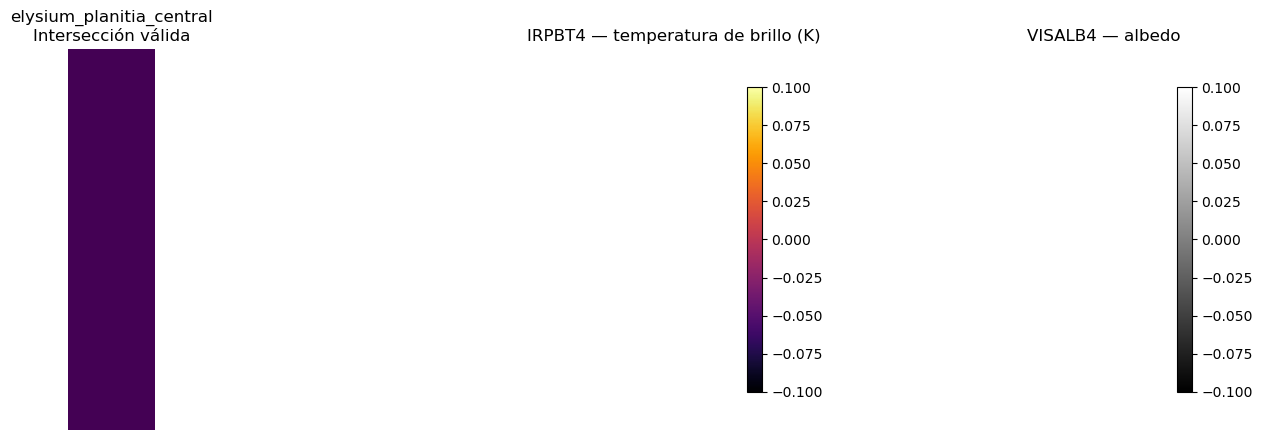


Procesando: olympus_mons_caldera
  Valid common cells: 8,449 / 13,735 (61.51%)


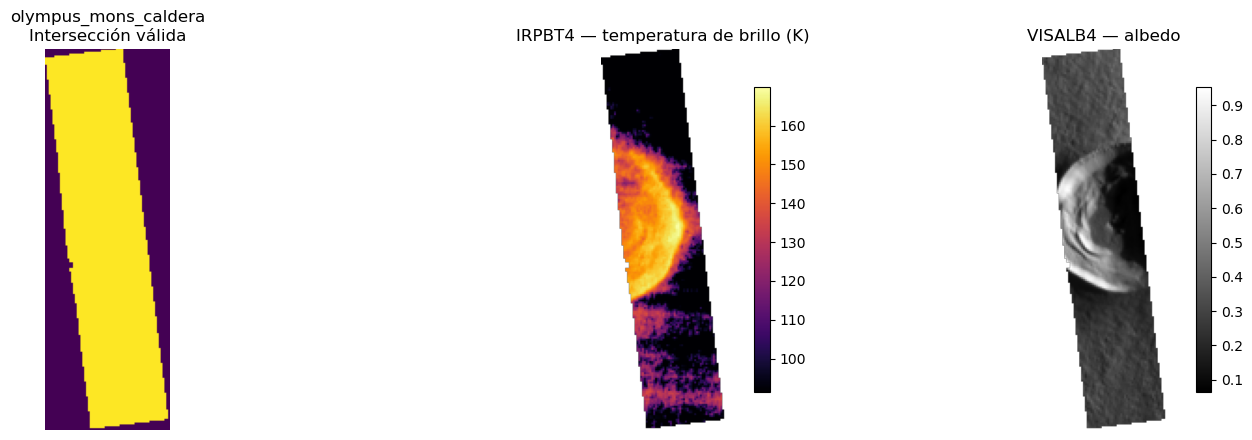


Procesando: valles_marineris_melas
  Valid common cells: 0 / 4,042 (0.00%)


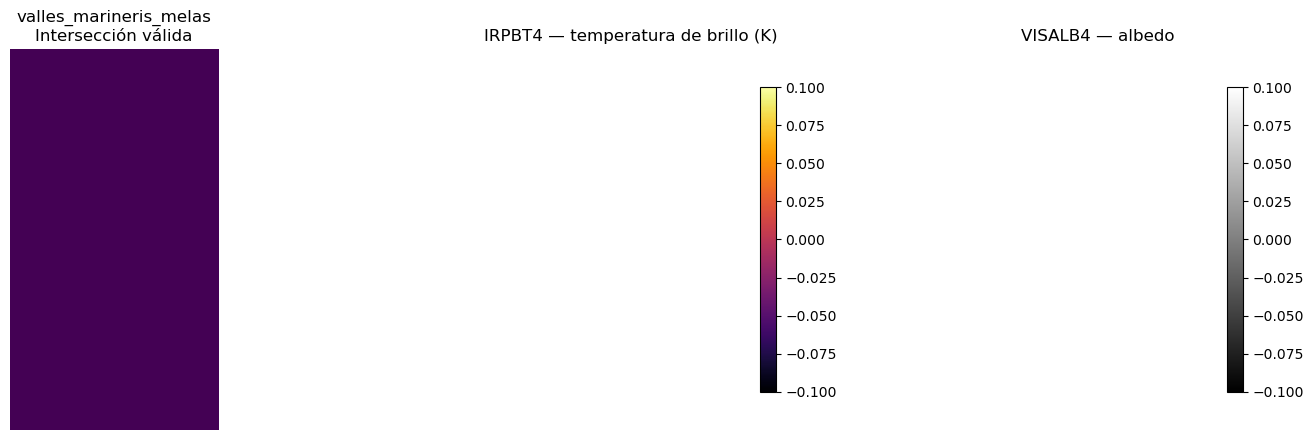


=== THEMIS FEATURES: FINAL ZONES ===


,site,common_coverage_pct,common_area_km2,ir_temp_p10,ir_temp_p50,ir_temp_p90,ir_temp_std,vis_albedo_p10,vis_albedo_p50,vis_albedo_p90,vis_albedo_std
0,elysium_planitia_central,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,olympus_mons_caldera,61.514379,132.015625,91.431152,102.96761,154.881447,25.391022,0.135923,0.295681,0.537799,0.157031
2,valles_marineris_melas,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Saved: features_last_zones/features_themis_last_zones.csv


In [34]:
# ============================================================
# THEMIS FEATURES IN THE DTM + IRPBT4 + VISALB4 INTERSECTION
# ============================================================

import numpy as np
import pandas as pd
import rasterio
from pathlib import Path
from rasterio.crs import CRS
from rasterio.transform import from_origin
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.windows import from_bounds, Window
import matplotlib.pyplot as plt
from pyproj import CRS as PyprojCRS
# Same physical scale used for the topographic variables.
ANALYSIS_RESOLUTION_M = 125.0

QUANTITATIVE_SITES = [
    "elysium_planitia_central",
    "olympus_mons_caldera",
    "valles_marineris_melas",
]

OUTPUT_DIR = Path("features_last_zones")
OUTPUT_DIR.mkdir(exist_ok=True)

# Automatically detect the name of the column holding the DTM path.
DTM_PATH_COL = next(
    col for col in ["raster_path_dtm", "raster_path"]
    if col in dtm_last_zones_downloaded.columns
)

dtms = (
    dtm_last_zones_downloaded[
        dtm_last_zones_downloaded["site"].isin(QUANTITATIVE_SITES)
    ][["site", DTM_PATH_COL]]
    .rename(columns={DTM_PATH_COL: "dtm_path"})
    .copy()
)

themis = (
    themis_last_zones_downloaded[
        themis_last_zones_downloaded["site"].isin(QUANTITATIVE_SITES)
    ][["site", "product_item", "pdsid", "raster_path"]]
    .copy()
)

ir_paths = (
    themis[themis["product_item"] == "IRPBT4"]
    .rename(
        columns={
            "pdsid": "ir_pdsid",
            "raster_path": "ir_path",
        }
    )[["site", "ir_pdsid", "ir_path"]]
)

vis_paths = (
    themis[themis["product_item"] == "VISALB4"]
    .rename(
        columns={
            "pdsid": "vis_pdsid",
            "raster_path": "vis_path",
        }
    )[["site", "vis_pdsid", "vis_path"]]
)

inputs = (
    dtms.merge(ir_paths, on="site", how="inner")
    .merge(vis_paths, on="site", how="inner")
)

print("=== INPUTS FOR THEMIS FEATURES ===")
display(inputs)


def raster_geographic_bounds(src, mars_geo_crs):
    """Converts raster bounds to Martian geographic coordinates."""
    return transform_bounds(
        src.crs,
        mars_geo_crs,
        *src.bounds,
        densify_pts=21,
    )


def intersect_bounds(bounds_list):
    """Bounds intersection: left, bottom, right, top."""
    left = max(bounds[0] for bounds in bounds_list)
    bottom = max(bounds[1] for bounds in bounds_list)
    right = min(bounds[2] for bounds in bounds_list)
    top = min(bounds[3] for bounds in bounds_list)

    if left >= right or bottom >= top:
        raise ValueError(
            "There is no geographic intersection between DTM, IRPBT4 and VISALB4."
        )

    return left, bottom, right, top


def bounded_window(src, geographic_bounds, mars_geo_crs):
    """Gets the raster window that intersects the common geographic area."""
    src_bounds = transform_bounds(
        mars_geo_crs,
        src.crs,
        *geographic_bounds,
        densify_pts=21,
    )

    window = from_bounds(*src_bounds, transform=src.transform)
    window = window.round_offsets().round_lengths()

    full_window = Window(
        col_off=0,
        row_off=0,
        width=src.width,
        height=src.height,
    )

    return window.intersection(full_window)


def read_as_nan(src, window=None, zero_is_nodata=False):
    """
    Reads a raster as float and converts NoData to NaN.
    For THEMIS, zeros are also treated as pixels with no observation.
    """
    raw = src.read(1, window=window).astype(np.float64)
    valid_mask = src.read_masks(1, window=window) > 0

    if src.nodata is not None and np.isfinite(src.nodata):
        valid_mask &= ~np.isclose(raw, src.nodata)

    if zero_is_nodata:
        valid_mask &= raw != 0

    # Apply PDS/GDAL scale and offset when present.
    scale = src.scales[0] if src.scales and src.scales[0] is not None else 1.0
    offset = src.offsets[0] if src.offsets and src.offsets[0] is not None else 0.0

    raw = raw * scale + offset
    raw[~valid_mask] = np.nan

    return raw, scale, offset


def reproject_to_common_grid(
    src,
    target_crs,
    target_transform,
    target_shape,
    geographic_bounds,
    mars_geo_crs,
    zero_is_nodata=False,
):
    """Clips and reprojects a raster to the common 125 m grid."""
    window = bounded_window(src, geographic_bounds, mars_geo_crs)

    data, scale, offset = read_as_nan(
        src,
        window=window,
        zero_is_nodata=zero_is_nodata,
    )

    destination = np.full(target_shape, np.nan, dtype=np.float64)

    reproject(
        source=data,
        destination=destination,
        src_transform=src.window_transform(window),
        src_crs=src.crs,
        src_nodata=np.nan,
        dst_transform=target_transform,
        dst_crs=target_crs,
        dst_nodata=np.nan,
        resampling=Resampling.bilinear,
        init_dest_nodata=True,
    )

    return destination, scale, offset


def get_statistics(values, prefix):
    """Percentiles and heterogeneity for a valid variable."""
    values = values[np.isfinite(values)]

    if values.size == 0:
        return {
            f"{prefix}_p10": np.nan,
            f"{prefix}_p50": np.nan,
            f"{prefix}_p90": np.nan,
            f"{prefix}_std": np.nan,
        }

    return {
        f"{prefix}_p10": np.percentile(values, 10),
        f"{prefix}_p50": np.percentile(values, 50),
        f"{prefix}_p90": np.percentile(values, 90),
        f"{prefix}_std": np.std(values),
    }

def get_mars_geographic_crs(src_crs):
    """
    Gets the Martian geographic CRS, compatible with older
    Rasterio versions, from the DTM's projected CRS.
    """
    pyproj_crs = PyprojCRS.from_wkt(src_crs.to_wkt())
    mars_geographic = pyproj_crs.geodetic_crs

    return rasterio.crs.CRS.from_wkt(mars_geographic.to_wkt())


def plot_common_coverage(site, temperature, albedo, common_mask):
    """Visual check: shows only the area used in the calculations."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    temp_plot = np.ma.masked_where(~common_mask, temperature)
    alb_plot = np.ma.masked_where(~common_mask, albedo)

    axes[0].imshow(common_mask, cmap="viridis")
    axes[0].set_title(f"{site}\nValid intersection")
    axes[0].set_axis_off()

    im_temp = axes[1].imshow(temp_plot, cmap="inferno")
    axes[1].set_title("IRPBT4 — brightness temperature (K)")
    axes[1].set_axis_off()
    plt.colorbar(im_temp, ax=axes[1], shrink=0.8)

    im_albedo = axes[2].imshow(alb_plot, cmap="gray")
    axes[2].set_title("VISALB4 — albedo")
    axes[2].set_axis_off()
    plt.colorbar(im_albedo, ax=axes[2], shrink=0.8)

    plt.tight_layout()
    plt.show()


record_list = []

for _, row in inputs.iterrows():
    site = row["site"]

    print(f"\nProcesando: {site}")

    with rasterio.open(row["dtm_path"]) as dtm_src, \
         rasterio.open(row["ir_path"]) as ir_src, \
         rasterio.open(row["vis_path"]) as vis_src:

        # Martian geographic CRS derived from the DTM.
        mars_geo_crs = get_mars_geographic_crs(dtm_src.crs)
        # Geographic intersection of the three rasters.
        common_geo_bounds = intersect_bounds(
            [
                raster_geographic_bounds(dtm_src, mars_geo_crs),
                raster_geographic_bounds(ir_src, mars_geo_crs),
                raster_geographic_bounds(vis_src, mars_geo_crs),
            ]
        )

        # Common 125 m grid, in the DTM CRS.
        dtm_common_bounds = transform_bounds(
            mars_geo_crs,
            dtm_src.crs,
            *common_geo_bounds,
            densify_pts=21,
        )

        left, bottom, right, top = dtm_common_bounds

        width = int(np.ceil((right - left) / ANALYSIS_RESOLUTION_M))
        height = int(np.ceil((top - bottom) / ANALYSIS_RESOLUTION_M))

        common_transform = from_origin(
            left,
            top,
            ANALYSIS_RESOLUTION_M,
            ANALYSIS_RESOLUTION_M,
        )

        common_shape = (height, width)

        dem, dem_scale, dem_offset = reproject_to_common_grid(
            dtm_src,
            dtm_src.crs,
            common_transform,
            common_shape,
            common_geo_bounds,
            mars_geo_crs,
            zero_is_nodata=False,
        )

        ir_temp, ir_scale, ir_offset = reproject_to_common_grid(
            ir_src,
            dtm_src.crs,
            common_transform,
            common_shape,
            common_geo_bounds,
            mars_geo_crs,
            zero_is_nodata=True,
        )

        vis_albedo, vis_scale, vis_offset = reproject_to_common_grid(
            vis_src,
            dtm_src.crs,
            common_transform,
            common_shape,
            common_geo_bounds,
            mars_geo_crs,
            zero_is_nodata=True,
        )

        # Only cells present in all three products are kept.
        common_mask = (
            np.isfinite(dem)
            & np.isfinite(ir_temp)
            & np.isfinite(vis_albedo)
        )

        n_common = int(common_mask.sum())
        n_total = int(common_mask.size)
        common_coverage_pct = 100 * n_common / n_total

        ir_values = ir_temp[common_mask]
        albedo_values = vis_albedo[common_mask]

        record = {
            "site": site,
            "zone_type": "representative_microsite",
            "dtm_pdsid": row.get("dtm_pdsid", np.nan),
            "ir_pdsid": row["ir_pdsid"],
            "vis_pdsid": row["vis_pdsid"],
            "analysis_resolution_m": ANALYSIS_RESOLUTION_M,
            "common_minlat": common_geo_bounds[1],
            "common_maxlat": common_geo_bounds[3],
            "common_westernlon": common_geo_bounds[0],
            "common_easternlon": common_geo_bounds[2],
            "common_n_cells": n_common,
            "common_coverage_pct": common_coverage_pct,
            "common_area_km2": n_common * ANALYSIS_RESOLUTION_M**2 / 1e6,
            "ir_scale": ir_scale,
            "ir_offset": ir_offset,
            "vis_scale": vis_scale,
            "vis_offset": vis_offset,
        }

        record.update(get_statistics(ir_values, "ir_temp"))
        record.update(get_statistics(albedo_values, "vis_albedo"))

        record_list.append(record)

        print(
            f"  Valid common cells: {n_common:,} / {n_total:,} "
            f"({common_coverage_pct:.2f}%)"
        )

        plot_common_coverage(
            site,
            ir_temp,
            vis_albedo,
            common_mask,
        )

themis_features_last_zones = pd.DataFrame(record_list)

print("\n=== THEMIS FEATURES: FINAL ZONES ===")
display(
    themis_features_last_zones[
        [
            "site",
            "common_coverage_pct",
            "common_area_km2",
            "ir_temp_p10",
            "ir_temp_p50",
            "ir_temp_p90",
            "ir_temp_std",
            "vis_albedo_p10",
            "vis_albedo_p50",
            "vis_albedo_p90",
            "vis_albedo_std",
        ]
    ]
)

themis_features_last_zones.to_csv(
    OUTPUT_DIR / "features_themis_last_zones.csv",
    index=False,
)

print(
    "\nGuardado:",
    OUTPUT_DIR / "features_themis_last_zones.csv"
)

### 11.3 Diagnosing Spatial Coverage and Valid Value Ranges


In [35]:
# ============================================================
# COVERAGE AND RANGE DIAGNOSTICS: DTM + THEMIS
# ============================================================

def diagnostic_raster(path, name, zero_is_nodata=False):
    with rasterio.open(path) as src:
        data = src.read(1).astype(np.float64)
        mask = src.read_masks(1) > 0

        if src.nodata is not None and np.isfinite(src.nodata):
            mask &= ~np.isclose(data, src.nodata)

        if zero_is_nodata:
            mask &= data != 0

        scale = src.scales[0] if src.scales else 1.0
        offset = src.offsets[0] if src.offsets else 0.0

        values = data[mask] * scale + offset

        print(f"\n--- {name} ---")
        print(f"File: {path}")
        print(f"CRS: {src.crs}")
        print(f"Dimensions: {src.width:,} × {src.height:,}")
        print(f"Resolution: {src.res}")
        print(f"NoData: {src.nodata}")
        print(f"Scale / offset: {scale} / {offset}")
        print(f"Bounds nativos: {src.bounds}")
        print(f"Valid pixels: {mask.sum():,} / {mask.size:,} ({100 * mask.mean():.2f}%)")

        if values.size:
            print(
                f"Valid range: {np.nanmin(values):.4f} a {np.nanmax(values):.4f} | "
                f"p10={np.nanpercentile(values, 10):.4f} | "
                f"p50={np.nanpercentile(values, 50):.4f} | "
                f"p90={np.nanpercentile(values, 90):.4f}"
            )
        else:
            print("WARNING: no valid pixels left.")

        return src.crs, src.bounds


for _, row in inputs.iterrows():
    site = row["site"]

    print("\n" + "=" * 70)
    print(f"DIAGNOSTICS: {site.upper()}")
    print("=" * 70)

    with rasterio.open(row["dtm_path"]) as dtm_src:
        mars_geo_crs = get_mars_geographic_crs(dtm_src.crs)

    print("\nMartian geographic CRS used:")
    print(mars_geo_crs)

    dtm_crs, dtm_bounds = diagnostic_raster(
        row["dtm_path"],
        "DTM",
        zero_is_nodata=False,
    )

    ir_crs, ir_bounds = diagnostic_raster(
        row["ir_path"],
        "IRPBT4",
        zero_is_nodata=True,
    )

    vis_crs, vis_bounds = diagnostic_raster(
        row["vis_path"],
        "VISALB4",
        zero_is_nodata=True,
    )

    try:
        dtm_geo = transform_bounds(dtm_crs, mars_geo_crs, *dtm_bounds, densify_pts=21)
        ir_geo = transform_bounds(ir_crs, mars_geo_crs, *ir_bounds, densify_pts=21)
        vis_geo = transform_bounds(vis_crs, mars_geo_crs, *vis_bounds, densify_pts=21)

        print("\nMartian geographic bounds [west, south, east, north]:")
        print("DTM:    ", np.round(dtm_geo, 6))
        print("IRPBT4: ", np.round(ir_geo, 6))
        print("VISALB4:", np.round(vis_geo, 6))

        common = intersect_bounds([dtm_geo, ir_geo, vis_geo])

        print("\nComputed geographic intersection:")
        print(np.round(common, 6))

    except Exception as error:
        print("\nERROR computing geographic intersection:")
        print(error)


DIAGNOSTICS: ELYSIUM_PLANITIA_CENTRAL

Martian geographic CRS used:
GEOGCS["GCS_MARS",DATUM["D_MARS",SPHEROID["MARS_localRadius",3396190,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Longitude",EAST],AXIS["Latitude",NORTH]]

--- DTM ---
File: pds_dtms_last_zones/elysium_planitia_central/DTEEC_010335_1840_006762_1840_L01.IMG
CRS: PROJCS["EQUIRECTANGULAR MARS",GEOGCS["GCS_MARS",DATUM["D_MARS",SPHEROID["MARS_localRadius",3396190,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",155.46],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Dimensions: 7,643 × 20,768
Resolution: (1.0117992087934, 1.0117992087934)
NoData: -3.4028226550889045e+38
Scale / offset: 1.0 / 0.0
Bounds nativos: BoundingBox(left=-3985.47

## 12. Building a Final Profile for Olympus Mons


### 12.1 Integrating DTM and THEMIS; Updating the Six-Region Master CSV


In [38]:
# ============================================================
# FINAL PROFILE: OLYMPUS MONS IN THE DTM + THEMIS INTERSECTION
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import rasterio

from pyproj import CRS as PyprojCRS
from rasterio.transform import from_origin
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.windows import from_bounds, Window
from scipy.ndimage import convolve, uniform_filter

ANALYSIS_RESOLUTION_M = 125.0
ROUGHNESS_SUPPORT_M = 625.0
ROUGHNESS_WINDOW_PX = int(
    round(ROUGHNESS_SUPPORT_M / ANALYSIS_RESOLUTION_M)
)

SITE = "olympus_mons_caldera"

# Change this path only if your master CSV has another name or location.
MASTER_CSV = Path("data/craters.csv")
OUTPUT_CSV = Path("mars_profiles_6_zones.csv")


def get_mars_geographic_crs(src_crs):
    pyproj_crs = PyprojCRS.from_wkt(src_crs.to_wkt())
    return rasterio.crs.CRS.from_wkt(pyproj_crs.geodetic_crs.to_wkt())


def intersect_bounds(bounds_list):
    left = max(bounds[0] for bounds in bounds_list)
    bottom = max(bounds[1] for bounds in bounds_list)
    right = min(bounds[2] for bounds in bounds_list)
    top = min(bounds[3] for bounds in bounds_list)

    if left >= right or bottom >= top:
        raise ValueError("There is no valid geographic intersection.")

    return left, bottom, right, top


def raster_geographic_bounds(src, mars_geo_crs):
    return transform_bounds(
        src.crs,
        mars_geo_crs,
        *src.bounds,
        densify_pts=21,
    )


def bounded_window(src, geographic_bounds, mars_geo_crs):
    src_bounds = transform_bounds(
        mars_geo_crs,
        src.crs,
        *geographic_bounds,
        densify_pts=21,
    )

    window = from_bounds(*src_bounds, transform=src.transform)
    window = window.round_offsets().round_lengths()

    full_window = Window(0, 0, src.width, src.height)
    return window.intersection(full_window)


def read_small_raster(src, geographic_bounds, mars_geo_crs, zero_is_nodata):
    """
    THEMIS is relatively small: read, clip and reproject it.
    Zeros are read as missing observations.
    """
    window = bounded_window(src, geographic_bounds, mars_geo_crs)

    data = src.read(1, window=window).astype(np.float64)
    valid = src.read_masks(1, window=window) > 0

    if src.nodata is not None and np.isfinite(src.nodata):
        valid &= ~np.isclose(data, src.nodata)

    if zero_is_nodata:
        valid &= data != 0

    scale = src.scales[0] if src.scales else 1.0
    offset = src.offsets[0] if src.offsets else 0.0

    data = data * scale + offset
    data[~valid] = np.nan

    return data, src.window_transform(window), scale, offset


def reproject_small_to_grid(
    src,
    target_crs,
    target_transform,
    target_shape,
    geographic_bounds,
    mars_geo_crs,
    zero_is_nodata=True,
):
    source, source_transform, scale, offset = read_small_raster(
        src=src,
        geographic_bounds=geographic_bounds,
        mars_geo_crs=mars_geo_crs,
        zero_is_nodata=zero_is_nodata,
    )

    destination = np.full(target_shape, np.nan, dtype=np.float64)

    reproject(
        source=source,
        destination=destination,
        src_transform=source_transform,
        src_crs=src.crs,
        src_nodata=np.nan,
        dst_transform=target_transform,
        dst_crs=target_crs,
        dst_nodata=np.nan,
        resampling=Resampling.bilinear,
        init_dest_nodata=True,
    )

    return destination, scale, offset


def reproject_dtm_to_grid(
    src,
    target_transform,
    target_shape,
):
    """
    Rasterio reprojects straight from disk to the 125 m grid:
    avoids loading the full ~829 MB HiRISE DTM.
    """
    destination = np.full(target_shape, np.nan, dtype=np.float64)

    reproject(
        source=rasterio.band(src, 1),
        destination=destination,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=src.nodata,
        dst_transform=target_transform,
        dst_crs=src.crs,
        dst_nodata=np.nan,
        resampling=Resampling.bilinear,
        init_dest_nodata=True,
    )

    return destination


def percentile_stats(values, prefix, unit_suffix=""):
    values = values[np.isfinite(values)]

    return {
        f"{prefix}_p10{unit_suffix}": np.percentile(values, 10),
        f"{prefix}_p50{unit_suffix}": np.percentile(values, 50),
        f"{prefix}_p90{unit_suffix}": np.percentile(values, 90),
        f"{prefix}_std{unit_suffix}": np.std(values),
    }


# ------------------------------------------------------------
# 1. Select Olympus paths
# ------------------------------------------------------------

DTM_PATH_COL = next(
    col for col in ["raster_path_dtm", "raster_path"]
    if col in dtm_last_zones_downloaded.columns
)

dtm_row = (
    dtm_last_zones_downloaded
    .loc[dtm_last_zones_downloaded["site"] == SITE]
    .iloc[0]
)

ir_row = (
    themis_last_zones_downloaded
    .loc[
        (themis_last_zones_downloaded["site"] == SITE)
        & (themis_last_zones_downloaded["product_item"] == "IRPBT4")
    ]
    .iloc[0]
)

vis_row = (
    themis_last_zones_downloaded
    .loc[
        (themis_last_zones_downloaded["site"] == SITE)
        & (themis_last_zones_downloaded["product_item"] == "VISALB4")
    ]
    .iloc[0]
)

dtm_path = dtm_row[DTM_PATH_COL]
ir_path = ir_row["raster_path"]
vis_path = vis_row["raster_path"]

print("=== FILES USED FOR OLYMPUS ===")
print("DTM:    ", dtm_path)
print("IRPBT4: ", ir_path)
print("VISALB4:", vis_path)


# ------------------------------------------------------------
# 2. Build the intersection and the common 125 m grid
# ------------------------------------------------------------

with rasterio.open(dtm_path) as dtm_src, \
     rasterio.open(ir_path) as ir_src, \
     rasterio.open(vis_path) as vis_src:

    mars_geo_crs = get_mars_geographic_crs(dtm_src.crs)

    common_geo_bounds = intersect_bounds(
        [
            raster_geographic_bounds(dtm_src, mars_geo_crs),
            raster_geographic_bounds(ir_src, mars_geo_crs),
            raster_geographic_bounds(vis_src, mars_geo_crs),
        ]
    )

    dtm_common_bounds = transform_bounds(
        mars_geo_crs,
        dtm_src.crs,
        *common_geo_bounds,
        densify_pts=21,
    )

    left, bottom, right, top = dtm_common_bounds

    width = int(np.ceil((right - left) / ANALYSIS_RESOLUTION_M))
    height = int(np.ceil((top - bottom) / ANALYSIS_RESOLUTION_M))

    common_transform = from_origin(
        left,
        top,
        ANALYSIS_RESOLUTION_M,
        ANALYSIS_RESOLUTION_M,
    )
    common_shape = (height, width)

    dem = reproject_dtm_to_grid(
        src=dtm_src,
        target_transform=common_transform,
        target_shape=common_shape,
    )

    ir_temp, ir_scale, ir_offset = reproject_small_to_grid(
        src=ir_src,
        target_crs=dtm_src.crs,
        target_transform=common_transform,
        target_shape=common_shape,
        geographic_bounds=common_geo_bounds,
        mars_geo_crs=mars_geo_crs,
        zero_is_nodata=True,
    )

    vis_albedo, vis_scale, vis_offset = reproject_small_to_grid(
        src=vis_src,
        target_crs=dtm_src.crs,
        target_transform=common_transform,
        target_shape=common_shape,
        geographic_bounds=common_geo_bounds,
        mars_geo_crs=mars_geo_crs,
        zero_is_nodata=True,
    )


# ------------------------------------------------------------
# 3. Common mask and topographic variables
# ------------------------------------------------------------

common_mask = (
    np.isfinite(dem)
    & np.isfinite(ir_temp)
    & np.isfinite(vis_albedo)
)

if common_mask.sum() == 0:
    raise RuntimeError("Olympus produced no valid common pixels.")

coverage_pct = 100 * common_mask.mean()
common_area_km2 = (
    common_mask.sum() * ANALYSIS_RESOLUTION_M**2 / 1e6
)

# Slope: used only where the full 3×3 neighbourhood is valid.
dem_filled = np.where(common_mask, dem, 0.0)

gy, gx = np.gradient(
    dem_filled,
    ANALYSIS_RESOLUTION_M,
    ANALYSIS_RESOLUTION_M,
)

slope_deg = np.degrees(np.arctan(np.hypot(gx, gy)))

kernel_3 = np.ones((3, 3), dtype=np.uint8)
valid_slope = (
    convolve(
        common_mask.astype(np.uint8),
        kernel_3,
        mode="constant",
        cval=0,
    ) == 9
)

# Roughness: local standard deviation of elevation in a 625 m window.
kernel_n = ROUGHNESS_WINDOW_PX * ROUGHNESS_WINDOW_PX

local_mean = uniform_filter(
    dem_filled,
    size=ROUGHNESS_WINDOW_PX,
    mode="constant",
)

local_mean_sq = uniform_filter(
    dem_filled**2,
    size=ROUGHNESS_WINDOW_PX,
    mode="constant",
)

roughness = np.sqrt(
    np.maximum(local_mean_sq - local_mean**2, 0)
)

valid_rough = (
    convolve(
        common_mask.astype(np.uint8),
        np.ones((ROUGHNESS_WINDOW_PX, ROUGHNESS_WINDOW_PX), dtype=np.uint8),
        mode="constant",
        cval=0,
    ) == kernel_n
)

dem_values = dem[common_mask]
slope_values = slope_deg[valid_slope]
rough_values = roughness[valid_rough]
ir_values = ir_temp[common_mask]
albedo_values = vis_albedo[common_mask]


# ------------------------------------------------------------
# 4. Build a homogeneous profile for Gower / HDBSCAN
# ------------------------------------------------------------

olympus_profile = {
    "site": SITE,
    "zone_type": "representative_microsite",
    "dtm_pdsid": Path(dtm_path).stem,
    "ir_pdsid": ir_row["pdsid"],
    "vis_pdsid": vis_row["pdsid"],
    "analysis_res_x_m": ANALYSIS_RESOLUTION_M,
    "analysis_res_y_m": ANALYSIS_RESOLUTION_M,
    "valid_coverage_pct": coverage_pct,
    "common_area_km2": common_area_km2,
    "common_minlat": common_geo_bounds[1],
    "common_maxlat": common_geo_bounds[3],
    "common_westernlon": common_geo_bounds[0],
    "common_easternlon": common_geo_bounds[2],

    "elev_std_m": np.std(dem_values),
    "slope_p50": np.percentile(slope_values, 50),
    "slope_p95": np.percentile(slope_values, 95),
    "rough_p50": np.percentile(rough_values, 50),
    "rough_p95": np.percentile(rough_values, 95),
    "relief_m": np.percentile(dem_values, 98) - np.percentile(dem_values, 2),

    "ir_temp_p10_k": np.percentile(ir_values, 10),
    "ir_temp_p50_k": np.percentile(ir_values, 50),
    "ir_temp_p90_k": np.percentile(ir_values, 90),
    "ir_temp_std_k": np.std(ir_values),

    "vis_albedo_p10": np.percentile(albedo_values, 10),
    "vis_albedo_p50": np.percentile(albedo_values, 50),
    "vis_albedo_p90": np.percentile(albedo_values, 90),
    "vis_albedo_std": np.std(albedo_values),

    "ir_scale": ir_scale,
    "ir_offset": ir_offset,
    "vis_scale": vis_scale,
    "vis_offset": vis_offset,
}

olympus_profile_row = pd.DataFrame([olympus_profile])

print("\n=== FINAL OLYMPUS MONS PROFILE ===")
display(olympus_profile_row)


# ------------------------------------------------------------
# 5. Append to the master CSV without changing the original five
# ------------------------------------------------------------

olympus_profile_row.to_csv(
    "olympus_mons_caldera_profile.csv",
    index=False,
)

if MASTER_CSV.exists():
    base_profiles = pd.read_csv(MASTER_CSV)

    # Remove a previous Olympus version, if any.
    base_profiles = base_profiles.loc[
        base_profiles["site"] != SITE
    ].copy()

    all_columns = list(
        dict.fromkeys(
            list(base_profiles.columns)
            + list(olympus_profile_row.columns)
        )
    )

    mars_profiles_6_zones = pd.concat(
        [
            base_profiles.reindex(columns=all_columns),
            olympus_profile_row.reindex(columns=all_columns),
        ],
        ignore_index=True,
    )

    mars_profiles_6_zones.to_csv(OUTPUT_CSV, index=False)

    print(f"\nFinal CSV saved: {OUTPUT_CSV}")
    print(f"Total profiles: {len(mars_profiles_6_zones)}")

else:
    print(
        f"\nNot found: {MASTER_CSV}. "
        "olympus_mons_caldera_profile.csv was saved."
    )

=== FILES USED FOR OLYMPUS ===
DTM:     pds_dtms_last_zones/olympus_mons_caldera/DTEEC_005533_1975_005388_1975_A01.IMG
IRPBT4:  themis_last_zones/olympus_mons_caldera/IRPBT4/i96357002pbt/I96357002PBT.IMG
VISALB4: themis_last_zones/olympus_mons_caldera/VISALB4/v94654003alb/V94654003ALB.IMG

=== FINAL OLYMPUS MONS PROFILE ===


,site,zone_type,dtm_pdsid,ir_pdsid,vis_pdsid,analysis_res_x_m,analysis_res_y_m,valid_coverage_pct,common_area_km2,common_minlat,...,ir_temp_p90_k,ir_temp_std_k,vis_albedo_p10,vis_albedo_p50,vis_albedo_p90,vis_albedo_std,ir_scale,ir_offset,vis_scale,vis_offset
0,olympus_mons_caldera,representative_microsite,DTEEC_005533_1975_005388_1975_A01,i96357002pbt,v94654003alb,125.0,125.0,61.514379,132.015625,17.063966,...,154.881447,25.391022,0.135923,0.295681,0.537799,0.157031,1.0,0.0,1.0,0.0



Final CSV saved: mars_profiles_6_zones.csv
Total profiles: 6


## Conclusion

This notebook documents a **workflow for exploring, selecting, and extracting geospatial features from Martian data**. It starts with the inspection of DEM/DTM and THEMIS products, proceeds through the definition of regions of interest and the handling of invalid data, and combines topographic measurements with thermal and albedo information in tables that can support subsequent comparative analyses.

Key parts of the workflow include **coverage verification**, **spatial intersection between sensors**, **NoData handling**, and **resolution harmonization**, all of which help prevent inconsistent comparisons. The file retains several exploratory versions and repeated functions; a subsequent cleanup phase could consolidate utilities, centralize paths and configuration, isolate the terrestrial-data test, and verify that the complete workflow runs reproducibly from beginning to end.
